In [1]:
from google.colab import drive
drive.mount("/content/drive")

import os
import sys
import gc
import numpy as np
import torch

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"
MODEL_DIR = f"{BASE_DIR}/models"

INSTANTMESH_DIR = f"{MODEL_DIR}/instantmesh"
ZERO123_DIR = f"{MODEL_DIR}/zero123plus"

MODEL_CKPT = f"{INSTANTMESH_DIR}/instant_mesh_large.ckpt"
UNET_CKPT = f"{INSTANTMESH_DIR}/diffusion_pytorch_model.bin"

REPO_DIR = "/content/InstantMesh"
CONFIG_PATH = f"{REPO_DIR}/configs/instant-mesh-large.yaml"

SNAPSHOT_DIR = (
    ZERO123_DIR
    + "/models--sudo-ai--zero123plus-v1.2/snapshots/"
    + "2da07e89919e1a130c9b5add1584c70c7aa065fd"
)

OUTPUT_DIR = f"{BASE_DIR}/outputs"
VIEWS_DIR = f"{OUTPUT_DIR}/zero123_views"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(VIEWS_DIR, exist_ok=True)

if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

for path in [MODEL_CKPT, UNET_CKPT, CONFIG_PATH, SNAPSHOT_DIR]:
    print(os.path.exists(path), path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
GPU: Tesla T4
True /content/drive/MyDrive/Sketch2Shape_AI/models/instantmesh/instant_mesh_large.ckpt
True /content/drive/MyDrive/Sketch2Shape_AI/models/instantmesh/diffusion_pytorch_model.bin
True /content/InstantMesh/configs/instant-mesh-large.yaml
True /content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd


In [2]:
import transformers.pytorch_utils as pytorch_utils

def find_pruneable_heads_and_indices(
    heads, n_heads, head_size, already_pruned_heads
):
    mask = torch.ones(n_heads, head_size)
    heads = set(heads) - already_pruned_heads

    for head in heads:
        head -= sum(1 for h in already_pruned_heads if h < head)
        mask[head] = 0

    index = torch.arange(mask.numel())[mask.view(-1).bool()]
    return heads, index.long()

pytorch_utils.find_pruneable_heads_and_indices = (
    find_pruneable_heads_and_indices
)

from src.models.encoder.dino import ViTModel

def compatible_get_head_mask(self, head_mask, num_hidden_layers):
    if head_mask is None:
        return [None] * num_hidden_layers

    return self._convert_head_mask_to_5d(
        head_mask, num_hidden_layers
    )

ViTModel.get_head_mask = compatible_get_head_mask

print("Compatibility patches applied.")

Compatibility patches applied.


In [6]:
import rembg
import trimesh
import matplotlib.pyplot as plt

from PIL import Image
from einops import rearrange
from omegaconf import OmegaConf
from torchvision.transforms import v2

from diffusers import (
    DiffusionPipeline,
    EulerAncestralDiscreteScheduler
)
from src.utils.infer_util import (
    remove_background,
    resize_foreground
)

from src.utils.camera_util import get_zero123plus_input_cameras

from src.utils.train_util import instantiate_from_config

print("All imports successful.")

All imports successful.


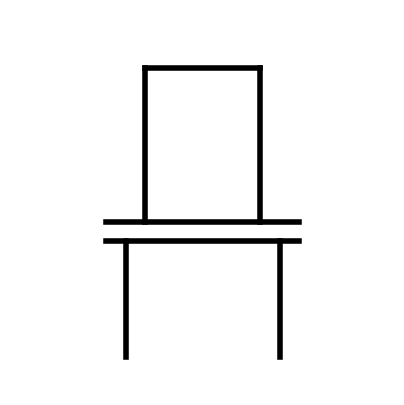

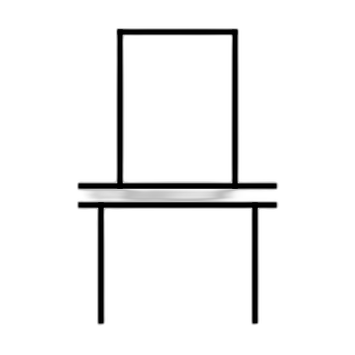

Original size: (404, 405)
Processed size: (355, 355)
Saved at: /content/drive/MyDrive/Sketch2Shape_AI/outputs/chair_sketch.png


204

In [8]:
import matplotlib.pyplot as plt
import rembg
import gc
from PIL import Image

# 1. Create a simple chair sketch
fig, ax = plt.subplots(figsize=(5, 5))

# Chair back
ax.plot([0.35, 0.35], [0.45, 0.85], 'black', linewidth=4)
ax.plot([0.65, 0.65], [0.45, 0.85], 'black', linewidth=4)
ax.plot([0.35, 0.65], [0.85, 0.85], 'black', linewidth=4)

# Seat
ax.plot([0.25, 0.75], [0.45, 0.45], 'black', linewidth=4)
ax.plot([0.25, 0.75], [0.40, 0.40], 'black', linewidth=4)

# Legs
ax.plot([0.30, 0.30], [0.40, 0.10], 'black', linewidth=4)
ax.plot([0.70, 0.70], [0.40, 0.10], 'black', linewidth=4)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect('equal')
ax.axis('off')

INPUT_IMAGE = f"{OUTPUT_DIR}/chair_sketch.png"

plt.savefig(
    INPUT_IMAGE,
    bbox_inches="tight",
    pad_inches=0.1,
    facecolor="white"
)
plt.show()
plt.close(fig)

# 2. Load sketch
original_image = Image.open(INPUT_IMAGE).convert("RGB")

# 3. Remove background
rembg_session = rembg.new_session("u2net")

processed_image = rembg.remove(
    original_image,
    session=rembg_session
)

# 4. Resize foreground
processed_image = resize_foreground(
    processed_image, 0.85
)

# 5. Display result
display(processed_image)

print("Original size:", original_image.size)
print("Processed size:", processed_image.size)
print("Saved at:", INPUT_IMAGE)

del rembg_session
gc.collect()

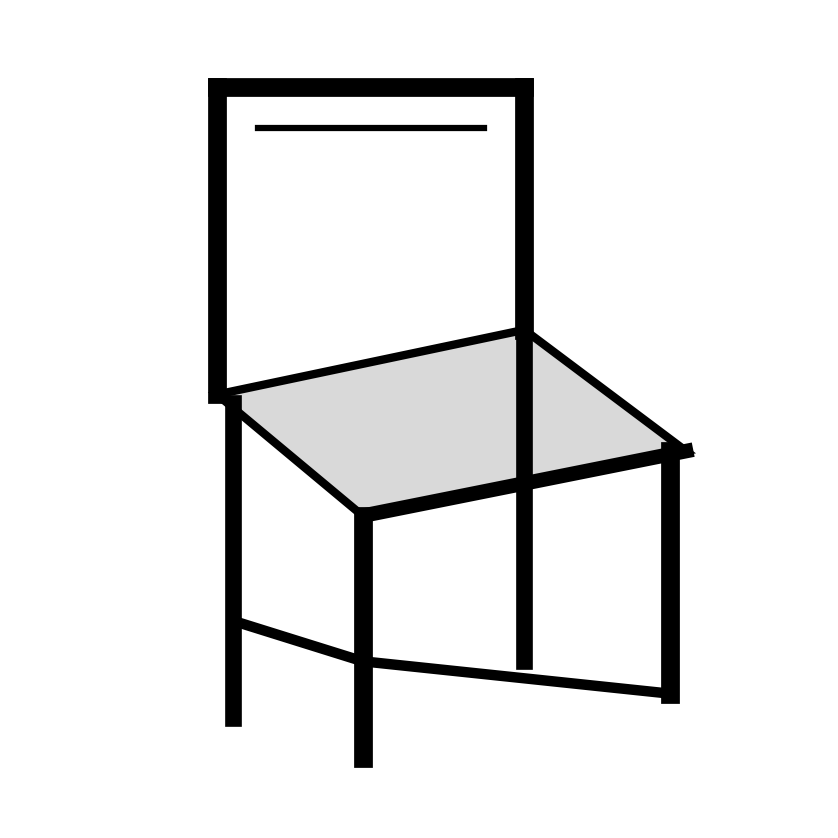

Improved sketch saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/chair_sketch.png


In [ ]:
INPUT_IMAGE = f"{OUTPUT_DIR}/chair_sketch.png"

if not os.path.exists(INPUT_IMAGE):
    raise FileNotFoundError(
        f"Sketch not found: {INPUT_IMAGE}\n"
        "Create or save a sketch at this location first."
    )

original_image = Image.open(INPUT_IMAGE).convert("RGB")

rembg_session = rembg.new_session("u2net")

processed_image = rembg.remove(
    original_image,
    session=rembg_session
)

processed_image = resize_foreground(
    processed_image, 0.85
)

display(processed_image)

print("Original size:", original_image.size)
print("Processed size:", processed_image.size)

del rembg_session
gc.collect()

In [13]:
pipeline = DiffusionPipeline.from_pretrained(
    SNAPSHOT_DIR,
    custom_pipeline=f"{REPO_DIR}/zero123plus",
    local_files_only=True
)

# Move model to T4 GPU in FP16
pipeline = pipeline.to(
    device="cuda",
    dtype=torch.float16
)

# Load custom InstantMesh white-background UNet
state_dict = torch.load(
    UNET_CKPT,
    map_location="cpu",
    weights_only=True
)

load_result = pipeline.unet.load_state_dict(
    state_dict,
    strict=True
)

print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

# Configure scheduler
pipeline.scheduler = EulerAncestralDiscreteScheduler.from_config(
    pipeline.scheduler.config,
    timestep_spacing="trailing"
)

print("\nZero123++ loaded successfully!")
print("GPU allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

Loading pipeline components...:   0%|          | 0/8 [00:00<?, ?it/s]

: 

: 

: 

In [1]:
from google.colab import drive
drive.mount("/content/drive")

import os

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"
OUTPUT_DIR = f"{BASE_DIR}/outputs"

INPUT_IMAGE = f"{OUTPUT_DIR}/chair_sketch.png"

print("Sketch exists:", os.path.exists(INPUT_IMAGE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Sketch exists: True


In [3]:
import sys

REPO_DIR = "/content/InstantMesh"

if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from src.utils.infer_util import resize_foreground

print("resize_foreground imported successfully!")

resize_foreground imported successfully!


Original image: (853, 853)


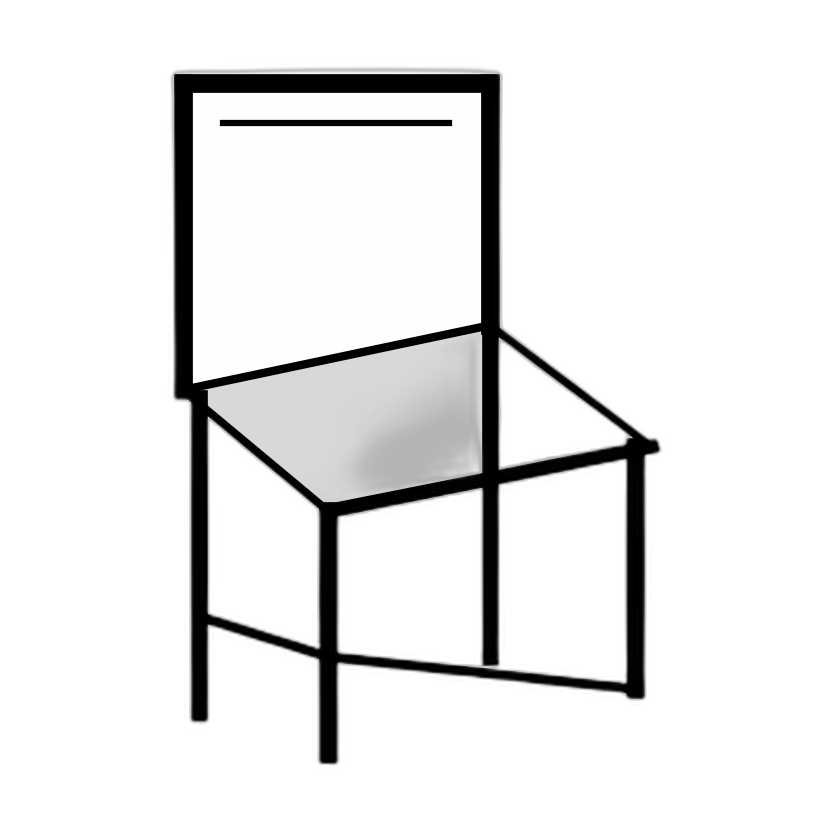

Processed image: (834, 834)


30

In [4]:
from PIL import Image
import rembg
import gc

INPUT_IMAGE = f"{OUTPUT_DIR}/chair_sketch.png"

original_image = Image.open(INPUT_IMAGE).convert("RGB")

print("Original image:", original_image.size)

rembg_session = rembg.new_session("u2net")

processed_image = rembg.remove(
    original_image,
    session=rembg_session
)

processed_image = resize_foreground(
    processed_image,
    0.85
)

display(processed_image)

print("Processed image:", processed_image.size)

del rembg_session
gc.collect()

Image size: (834, 834)
Image mode: RGBA


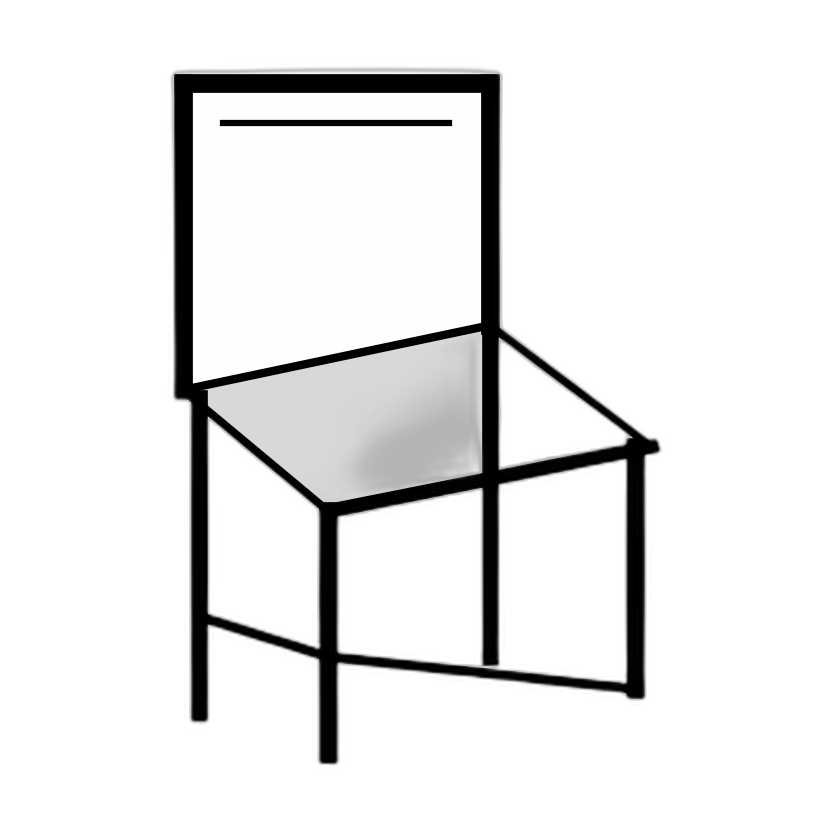

In [5]:
print("Image size:", processed_image.size)
print("Image mode:", processed_image.mode)

display(processed_image)

In [8]:
import os
import sys
import torch
import gc

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"
MODEL_DIR = f"{BASE_DIR}/models"

INSTANTMESH_DIR = f"{MODEL_DIR}/instantmesh"
ZERO123_DIR = f"{MODEL_DIR}/zero123plus"

MODEL_CKPT = f"{INSTANTMESH_DIR}/instant_mesh_large.ckpt"
UNET_CKPT = f"{INSTANTMESH_DIR}/diffusion_pytorch_model.bin"

REPO_DIR = "/content/InstantMesh"
CONFIG_PATH = f"{REPO_DIR}/configs/instant-mesh-large.yaml"

SNAPSHOT_DIR = (
    ZERO123_DIR
    + "/models--sudo-ai--zero123plus-v1.2/snapshots/"
    + "2da07e89919e1a130c9b5add1584c70c7aa065fd"
)

OUTPUT_DIR = f"{BASE_DIR}/outputs"
VIEWS_DIR = f"{OUTPUT_DIR}/zero123_views"

device = torch.device("cuda")

if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

print("GPU:", torch.cuda.get_device_name(0))

for path in [MODEL_CKPT, UNET_CKPT, CONFIG_PATH, SNAPSHOT_DIR]:
    print(os.path.exists(path), path)

GPU: Tesla T4
True /content/drive/MyDrive/Sketch2Shape_AI/models/instantmesh/instant_mesh_large.ckpt
True /content/drive/MyDrive/Sketch2Shape_AI/models/instantmesh/diffusion_pytorch_model.bin
True /content/InstantMesh/configs/instant-mesh-large.yaml
True /content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd


In [9]:
from diffusers import (
    DiffusionPipeline,
    EulerAncestralDiscreteScheduler
)

pipeline = DiffusionPipeline.from_pretrained(
    SNAPSHOT_DIR,
    custom_pipeline=f"{REPO_DIR}/zero123plus",
    local_files_only=True
)

pipeline = pipeline.to(
    device="cuda",
    dtype=torch.float16
)

state_dict = torch.load(
    UNET_CKPT,
    map_location="cpu",
    weights_only=True
)

load_result = pipeline.unet.load_state_dict(
    state_dict,
    strict=True
)

pipeline.scheduler = EulerAncestralDiscreteScheduler.from_config(
    pipeline.scheduler.config,
    timestep_spacing="trailing"
)

print("Zero123++ loaded successfully!")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

print(
    "GPU memory:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

Loading pipeline components...:   0%|          | 0/8 [00:00<?, ?it/s]

Zero123++ loaded successfully!
Missing keys: []
Unexpected keys: []
GPU memory: 3.6 GB


  0%|          | 0/75 [00:00<?, ?it/s]

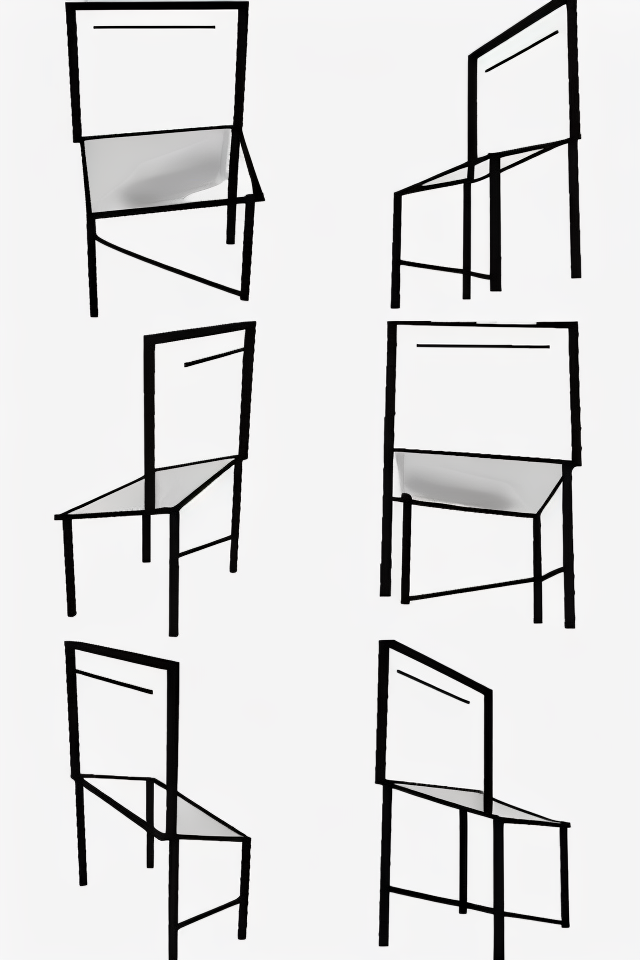

Generated views: 1
Contact sheet size: (640, 960)
Saved successfully!


In [10]:
with torch.inference_mode():
    result = pipeline(
        processed_image,
        num_inference_steps=75
    )

generated_images = result.images
contact_sheet = generated_images[0]

display(contact_sheet)

contact_sheet.save(
    f"{VIEWS_DIR}/contact_sheet.png"
)

print("Generated views:", len(generated_images))
print("Contact sheet size:", contact_sheet.size)
print("Saved successfully!")

  0%|          | 0/75 [00:00<?, ?it/s]

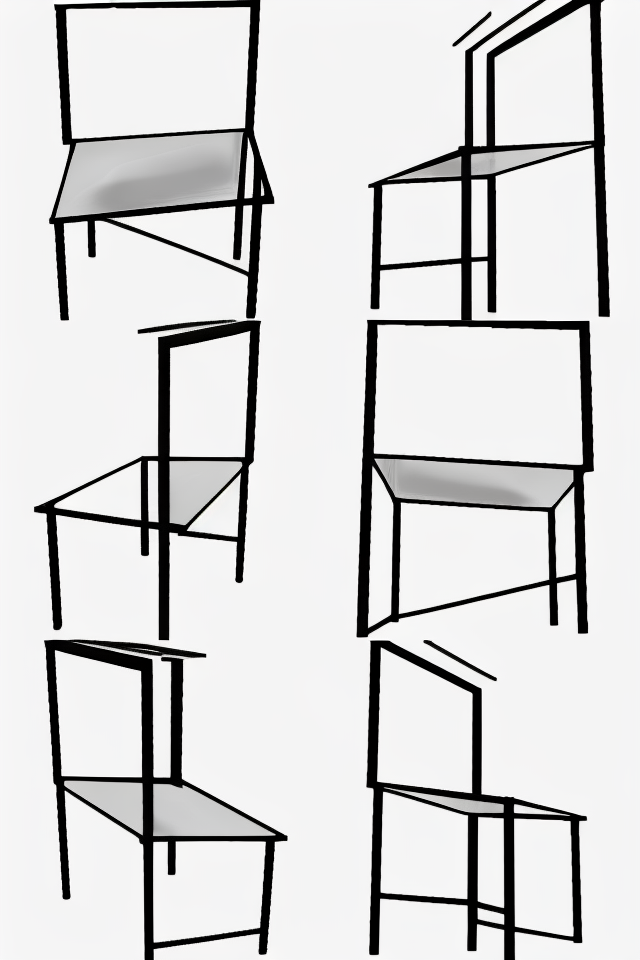

Generated views: 1
Contact sheet size: (640, 960)
Saved successfully!


In [11]:
with torch.inference_mode():
    result = pipeline(
        processed_image,
        num_inference_steps=75
    )

generated_images = result.images
contact_sheet = generated_images[0]

display(contact_sheet)

contact_sheet.save(
    f"{VIEWS_DIR}/contact_sheet.png"
)

print("Generated views:", len(generated_images))
print("Contact sheet size:", contact_sheet.size)
print("Saved successfully!")

In [12]:
import gc
import torch
import os

# Save six individual views
width, height = contact_sheet.size
view_width = width // 2
view_height = height // 3

for row in range(3):
    for col in range(2):
        view_number = row * 2 + col + 1

        view = contact_sheet.crop((
            col * view_width,
            row * view_height,
            (col + 1) * view_width,
            (row + 1) * view_height
        ))

        view.save(
            f"{VIEWS_DIR}/view_{view_number}.png"
        )

print("Six views saved.")

# Release Zero123++ GPU memory
del pipeline, result, generated_images
gc.collect()

torch.cuda.empty_cache()
torch.cuda.ipc_collect()

print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

print(
    "GPU memory free:",
    round(torch.cuda.mem_get_info()[0] / 1024**3, 2),
    "GB"
)

Six views saved.
GPU memory allocated: 0.01 GB
GPU memory free: 14.36 GB


In [13]:
from omegaconf import OmegaConf
from src.utils.train_util import instantiate_from_config

# Load configuration
config = OmegaConf.load(CONFIG_PATH)

model_config = config.model_config
infer_config = config.infer_config

# Initialize model
model = instantiate_from_config(model_config)

# Load pretrained checkpoint
checkpoint = torch.load(
    MODEL_CKPT,
    map_location="cpu",
    weights_only=False
)

state_dict = {
    k[14:]: v
    for k, v in checkpoint["state_dict"].items()
    if k.startswith("lrm_generator.")
    and "source_camera" not in k
}

load_result = model.load_state_dict(
    state_dict,
    strict=True
)

print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

# Move model to GPU
model = model.to(device)
model.eval()

# Reduce grid resolution for T4
model.grid_res = 64

model.init_flexicubes_geometry(
    device,
    fovy=30.0
)

print("\nInstantMesh loaded successfully!")

print(
    "GPU allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(
Some weights of ViTModel were not initialized from the model checkpoint at facebook/dino-vitb16 and are newly initialized: ['encoder.layer.0.adaLN_modulation.1.bias', 'encoder.layer.0.adaLN_modulation.1.weight', 'encoder.layer.1.adaLN_modulation.1.bias', 'encoder.layer.1.adaLN_modulation.1.weight', 'encoder.layer.10.adaLN_modulation.1.bias', 'encoder.layer.10.adaLN_modulation.1.weight', 'encoder.layer.11.adaLN_modulation.1.bias', 'encoder.layer.11.adaLN_modulation.1.weight', 'encoder.layer.2.adaLN_modulation.1.bias', 'enc

Missing keys: []
Unexpected keys: []

InstantMesh loaded successfully!
GPU allocated: 1.45 GB


In [16]:
from src.utils.camera_util import get_zero123plus_input_cameras

print("Camera utility imported successfully!")

Camera utility imported successfully!


In [17]:
from einops import rearrange
from PIL import Image
from torchvision.transforms import v2
import numpy as np

# Load saved contact sheet
sheet = Image.open(
    f"{VIEWS_DIR}/contact_sheet.png"
).convert("RGB")

# Convert image to tensor
images = np.asarray(
    sheet,
    dtype=np.float32
) / 255.0

images = torch.from_numpy(images)
images = images.permute(2, 0, 1).contiguous().float()

# Split 3x2 contact sheet into six views
images = rearrange(
    images,
    "c (n h) (m w) -> (n m) c h w",
    n=3,
    m=2
)

input_images = images.unsqueeze(0).to(device)

# Resize to InstantMesh input resolution
input_images = v2.functional.resize(
    input_images,
    (320, 320),
    interpolation=3,
    antialias=True
).clamp(0, 1)

# Generate camera parameters
input_cameras = get_zero123plus_input_cameras(
    batch_size=1,
    radius=4.0
).to(device)

print("Input images:", input_images.shape)
print("Input cameras:", input_cameras.shape)
print("Image range:", input_images.min().item(),
      input_images.max().item())

Input images: torch.Size([1, 6, 3, 320, 320])
Input cameras: torch.Size([1, 6, 16])
Image range: 0.0 1.0


In [18]:
# Generate 3D triplane representation
with torch.inference_mode():
    planes = model.forward_planes(
        input_images,
        input_cameras
    )

print("Triplane shape:", planes.shape)

print(
    "GPU allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

# Release input tensors
del input_images, input_cameras, images
gc.collect()
torch.cuda.empty_cache()

Triplane shape: torch.Size([1, 3, 80, 64, 64])
GPU allocated: 1.46 GB


In [19]:
torch.cuda.empty_cache()

with torch.inference_mode():
    mesh_out = model.extract_mesh(
        planes,
        use_texture_map=False,
        **infer_config
    )

vertices, faces, vertex_colors = mesh_out

print("===== MESH EXTRACTION =====")
print("Vertices:", vertices.shape)
print("Faces:", faces.shape)
print("Vertex colors:", vertex_colors.shape)

print(
    "GPU allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

===== MESH EXTRACTION =====
Vertices: (4804, 3)
Faces: (9484, 3)
Vertex colors: (4804, 3)
GPU allocated: 1.46 GB


In [20]:
import trimesh
import numpy as np

mesh = trimesh.Trimesh(
    vertices=vertices,
    faces=faces,
    vertex_colors=vertex_colors,
    process=False
)

print("===== MESH VALIDATION =====")
print("Watertight:", mesh.is_watertight)
print("Winding consistent:", mesh.is_winding_consistent)
print("Vertices:", len(mesh.vertices))
print("Faces:", len(mesh.faces))
print("Surface area:", mesh.area)
print("Volume:", mesh.volume)
print("Bounding box:\n", mesh.bounds)

print(
    "NaN in vertices:",
    np.isnan(vertices).any()
)

print(
    "NaN in colors:",
    np.isnan(vertex_colors).any()
)

===== MESH VALIDATION =====
Watertight: True
Winding consistent: True
Vertices: 4804
Faces: 9484
Surface area: 3.05768712667402
Volume: 0.03820437690568306
Bounding box:
 [[-0.75791186 -0.78476167 -0.96187007]
 [ 0.79053038  0.82476735  0.99210942]]
NaN in vertices: False
NaN in colors: False


In [21]:
import os

GLB_PATH = f"{OUTPUT_DIR}/chair_improved.glb"
OBJ_PATH = f"{OUTPUT_DIR}/chair_improved.obj"

mesh.export(GLB_PATH)
mesh.export(OBJ_PATH)

print("===== EXPORT SUCCESSFUL =====")
print("GLB:", GLB_PATH)
print("OBJ:", OBJ_PATH)

print(
    "GLB size:",
    round(os.path.getsize(GLB_PATH) / (1024**2), 2),
    "MB"
)

print(
    "OBJ size:",
    round(os.path.getsize(OBJ_PATH) / (1024**2), 2),
    "MB"
)

===== EXPORT SUCCESSFUL =====
GLB: /content/drive/MyDrive/Sketch2Shape_AI/outputs/chair_improved.glb
OBJ: /content/drive/MyDrive/Sketch2Shape_AI/outputs/chair_improved.obj
GLB size: 0.18 MB
OBJ size: 0.47 MB


In [22]:
loaded_mesh = trimesh.load(
    GLB_PATH,
    force="mesh"
)

print("Vertices:", len(loaded_mesh.vertices))
print("Faces:", len(loaded_mesh.faces))
print("Watertight:", loaded_mesh.is_watertight)

loaded_mesh.show()

Vertices: 4804
Faces: 9484
Watertight: True


In [28]:
import os

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"

INPUT_IMAGE = f"{BASE_DIR}/examples/chair.png"

OUTPUT_DIR = f"{BASE_DIR}/outputs"
VIEWS_DIR = f"{OUTPUT_DIR}/zero123_views"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(VIEWS_DIR, exist_ok=True)

print("Input exists:", os.path.exists(INPUT_IMAGE))
print("Input path:", INPUT_IMAGE)

Input exists: True
Input path: /content/drive/MyDrive/Sketch2Shape_AI/examples/chair.png


Image size: (512, 512)


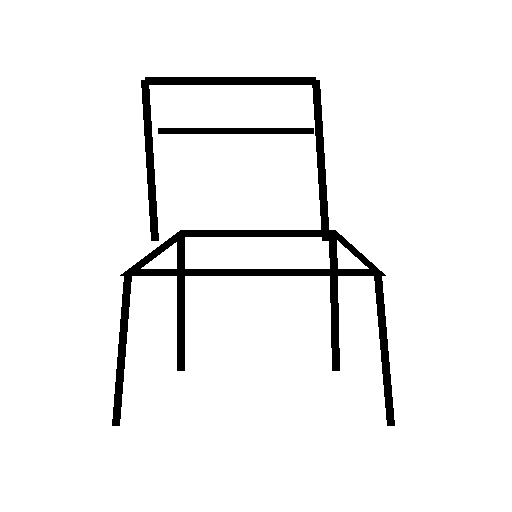

In [29]:
from PIL import Image

original_image = Image.open(INPUT_IMAGE).convert("RGB")

print("Image size:", original_image.size)
display(original_image)

Original size: (512, 512)


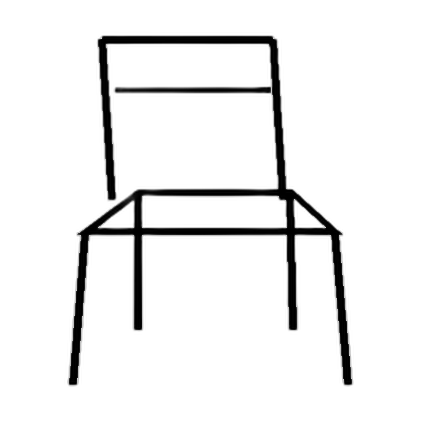

Processed size: (421, 421)
Image mode: RGBA


8

In [30]:
import rembg
import gc
from PIL import Image

from src.utils.infer_util import resize_foreground

# Load original sketch
original_image = Image.open(INPUT_IMAGE).convert("RGB")

print("Original size:", original_image.size)

# Create background removal session
rembg_session = rembg.new_session("u2net")

# Remove background
processed_image = rembg.remove(
    original_image,
    session=rembg_session
)

# Resize and center foreground
processed_image = resize_foreground(
    processed_image,
    0.85
)

# Display result
display(processed_image)

print("Processed size:", processed_image.size)
print("Image mode:", processed_image.mode)

# Release session
del rembg_session
gc.collect()

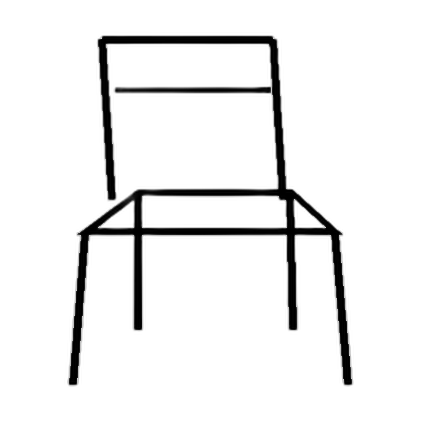

Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/processed_chair_sketch.png


In [31]:
PROCESSED_IMAGE = f"{OUTPUT_DIR}/processed_chair_sketch.png"

processed_image.save(PROCESSED_IMAGE)

display(processed_image)

print("Saved:", PROCESSED_IMAGE)

In [32]:
import gc
import torch

# Release InstantMesh and previous reconstruction data
for var in ["model", "planes", "mesh", "mesh_out",
            "vertices", "faces", "vertex_colors",
            "loaded_mesh", "checkpoint", "state_dict"]:
    if var in globals():
        del globals()[var]

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

print("GPU allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

print("GPU free:",
      round(torch.cuda.mem_get_info()[0] / 1024**3, 2), "GB")

GPU allocated: 0.01 GB
GPU free: 14.36 GB


In [33]:
from diffusers import (
    DiffusionPipeline,
    EulerAncestralDiscreteScheduler
)

pipeline = DiffusionPipeline.from_pretrained(
    SNAPSHOT_DIR,
    custom_pipeline=f"{REPO_DIR}/zero123plus",
    local_files_only=True
)

pipeline = pipeline.to(
    device="cuda",
    dtype=torch.float16
)

state_dict = torch.load(
    UNET_CKPT,
    map_location="cpu",
    weights_only=True
)

load_result = pipeline.unet.load_state_dict(
    state_dict,
    strict=True
)

pipeline.scheduler = EulerAncestralDiscreteScheduler.from_config(
    pipeline.scheduler.config,
    timestep_spacing="trailing"
)

print("Zero123++ loaded successfully!")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

Loading pipeline components...:   0%|          | 0/8 [00:00<?, ?it/s]

Zero123++ loaded successfully!
Missing keys: []
Unexpected keys: []


In [34]:
from diffusers import (
    DiffusionPipeline,
    EulerAncestralDiscreteScheduler
)

pipeline = DiffusionPipeline.from_pretrained(
    SNAPSHOT_DIR,
    custom_pipeline=f"{REPO_DIR}/zero123plus",
    local_files_only=True
)

pipeline = pipeline.to(
    device="cuda",
    dtype=torch.float16
)

state_dict = torch.load(
    UNET_CKPT,
    map_location="cpu",
    weights_only=True
)

load_result = pipeline.unet.load_state_dict(
    state_dict,
    strict=True
)

pipeline.scheduler = EulerAncestralDiscreteScheduler.from_config(
    pipeline.scheduler.config,
    timestep_spacing="trailing"
)

print("Zero123++ loaded successfully!")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

Loading pipeline components...:   0%|          | 0/8 [00:00<?, ?it/s]

Zero123++ loaded successfully!
Missing keys: []
Unexpected keys: []


  0%|          | 0/75 [00:00<?, ?it/s]

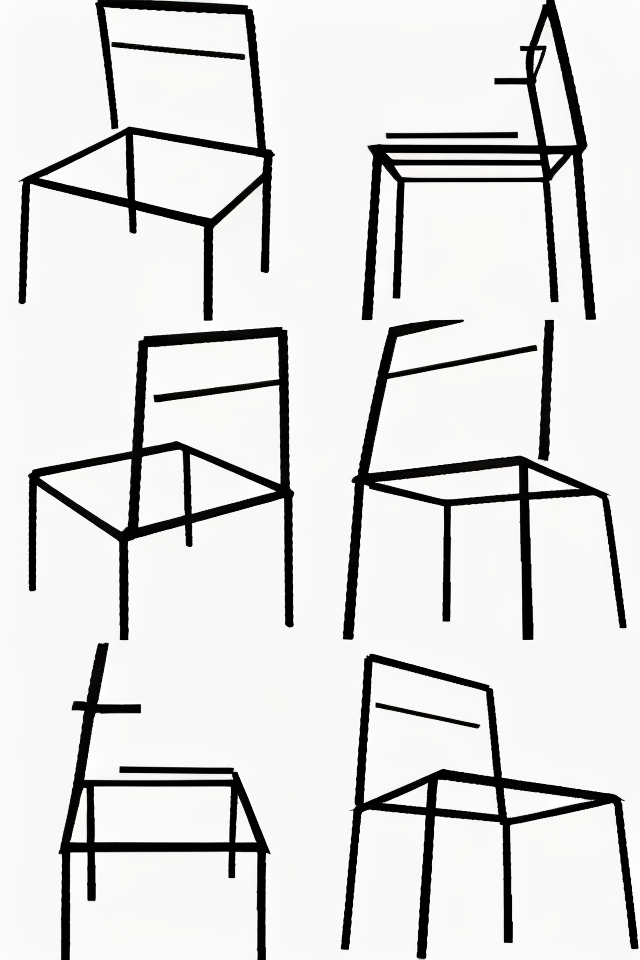

Generated views: 1
Contact sheet size: (640, 960)
Saved successfully!


In [35]:
with torch.inference_mode():
    result = pipeline(
        processed_image,
        num_inference_steps=75
    )

generated_images = result.images
contact_sheet = generated_images[0]

# Display six generated views
display(contact_sheet)

# Save contact sheet
contact_sheet.save(
    f"{VIEWS_DIR}/chair_zero123_views.png"
)

print("Generated views:", len(generated_images))
print("Contact sheet size:", contact_sheet.size)
print("Saved successfully!")

In [36]:
import gc
import torch

# Save individual views
width, height = contact_sheet.size
view_width = width // 2
view_height = height // 3

for row in range(3):
    for col in range(2):

        view_number = row * 2 + col + 1

        view = contact_sheet.crop((
            col * view_width,
            row * view_height,
            (col + 1) * view_width,
            (row + 1) * view_height
        ))

        view.save(
            f"{VIEWS_DIR}/chair_view_{view_number}.png"
        )

print("Six individual views saved.")

# Release Zero123++ from GPU
del pipeline, result, generated_images

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

print(
    "GPU allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

print(
    "GPU free:",
    round(torch.cuda.mem_get_info()[0] / 1024**3, 2),
    "GB"
)

Six individual views saved.
GPU allocated: 0.01 GB
GPU free: 14.36 GB


In [37]:
from omegaconf import OmegaConf
from src.utils.train_util import instantiate_from_config

# Load configuration
config = OmegaConf.load(CONFIG_PATH)

model_config = config.model_config
infer_config = config.infer_config

# Initialize InstantMesh
model = instantiate_from_config(model_config)

# Load pretrained checkpoint
checkpoint = torch.load(
    MODEL_CKPT,
    map_location="cpu",
    weights_only=False
)

state_dict = {
    k[14:]: v
    for k, v in checkpoint["state_dict"].items()
    if k.startswith("lrm_generator.")
    and "source_camera" not in k
}

load_result = model.load_state_dict(
    state_dict,
    strict=True
)

print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

# Move to GPU
model = model.to(device)
model.eval()

# T4-compatible geometry resolution
model.grid_res = 64

model.init_flexicubes_geometry(
    device,
    fovy=30.0
)

print("\nInstantMesh loaded successfully!")
print(
    "GPU allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

Some weights of ViTModel were not initialized from the model checkpoint at facebook/dino-vitb16 and are newly initialized: ['encoder.layer.0.adaLN_modulation.1.bias', 'encoder.layer.0.adaLN_modulation.1.weight', 'encoder.layer.1.adaLN_modulation.1.bias', 'encoder.layer.1.adaLN_modulation.1.weight', 'encoder.layer.10.adaLN_modulation.1.bias', 'encoder.layer.10.adaLN_modulation.1.weight', 'encoder.layer.11.adaLN_modulation.1.bias', 'encoder.layer.11.adaLN_modulation.1.weight', 'encoder.layer.2.adaLN_modulation.1.bias', 'encoder.layer.2.adaLN_modulation.1.weight', 'encoder.layer.3.adaLN_modulation.1.bias', 'encoder.layer.3.adaLN_modulation.1.weight', 'encoder.layer.4.adaLN_modulation.1.bias', 'encoder.layer.4.adaLN_modulation.1.weight', 'encoder.layer.5.adaLN_modulation.1.bias', 'encoder.layer.5.adaLN_modulation.1.weight', 'encoder.layer.6.adaLN_modulation.1.bias', 'encoder.layer.6.adaLN_modulation.1.weight', 'encoder.layer.7.adaLN_modulation.1.bias', 'encoder.layer.7.adaLN_modulation.1.w

Missing keys: []
Unexpected keys: []

InstantMesh loaded successfully!
GPU allocated: 1.45 GB


In [38]:
from einops import rearrange
from PIL import Image
from torchvision.transforms import v2
from src.utils.camera_util import get_zero123plus_input_cameras

# Load the Zero123++ contact sheet
sheet = Image.open(
    f"{VIEWS_DIR}/chair_zero123_views.png"
).convert("RGB")

# Convert to tensor
images = np.asarray(sheet, dtype=np.float32) / 255.0

images = torch.from_numpy(images)
images = images.permute(2, 0, 1).contiguous().float()

# Split 3x2 contact sheet into six views
images = rearrange(
    images,
    "c (n h) (m w) -> (n m) c h w",
    n=3,
    m=2
)

input_images = images.unsqueeze(0).to(device)

# Resize for InstantMesh
input_images = v2.functional.resize(
    input_images,
    (320, 320),
    interpolation=3,
    antialias=True
).clamp(0, 1)

# Camera parameters
input_cameras = get_zero123plus_input_cameras(
    batch_size=1,
    radius=4.0
).to(device)

print("Input images:", input_images.shape)
print("Input cameras:", input_cameras.shape)

Input images: torch.Size([1, 6, 3, 320, 320])
Input cameras: torch.Size([1, 6, 16])


In [39]:
from einops import rearrange
from PIL import Image
from torchvision.transforms import v2
from src.utils.camera_util import get_zero123plus_input_cameras

# Load Zero123++ contact sheet
sheet = Image.open(
    f"{VIEWS_DIR}/chair_zero123_views.png"
).convert("RGB")

# Convert image to tensor
images = np.asarray(sheet, dtype=np.float32) / 255.0

images = torch.from_numpy(images)
images = images.permute(2, 0, 1).contiguous().float()

# Split 3x2 contact sheet
images = rearrange(
    images,
    "c (n h) (m w) -> (n m) c h w",
    n=3,
    m=2
)

input_images = images.unsqueeze(0).to(device)

# Resize
input_images = v2.functional.resize(
    input_images,
    (320, 320),
    interpolation=3,
    antialias=True
).clamp(0, 1)

# Generate camera parameters
input_cameras = get_zero123plus_input_cameras(
    batch_size=1,
    radius=4.0
).to(device)

print("Input images:", input_images.shape)
print("Input cameras:", input_cameras.shape)

Input images: torch.Size([1, 6, 3, 320, 320])
Input cameras: torch.Size([1, 6, 16])


In [41]:
with torch.inference_mode():
    planes = model.forward_planes(
        input_images,
        input_cameras
    )

print("Triplane shape:", planes.shape)

print(
    "GPU allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

# Release input tensors
del input_images, input_cameras, images
gc.collect()
torch.cuda.empty_cache()

Triplane shape: torch.Size([1, 3, 80, 64, 64])
GPU allocated: 1.46 GB


In [42]:
torch.cuda.empty_cache()

with torch.inference_mode():
    mesh_out = model.extract_mesh(
        planes,
        use_texture_map=False,
        **infer_config
    )

vertices, faces, vertex_colors = mesh_out

print("===== MESH EXTRACTION =====")
print("Vertices:", vertices.shape)
print("Faces:", faces.shape)
print("Vertex colors:", vertex_colors.shape)

print(
    "GPU allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

===== MESH EXTRACTION =====
Vertices: (2532, 3)
Faces: (5056, 3)
Vertex colors: (2532, 3)
GPU allocated: 1.46 GB


In [43]:
import trimesh
import numpy as np

mesh = trimesh.Trimesh(
    vertices=vertices,
    faces=faces,
    vertex_colors=vertex_colors,
    process=False
)

print("===== MESH VALIDATION =====")
print("Watertight:", mesh.is_watertight)
print("Winding consistent:", mesh.is_winding_consistent)
print("Vertices:", len(mesh.vertices))
print("Faces:", len(mesh.faces))
print("Surface area:", mesh.area)
print("Volume:", mesh.volume)
print("Bounding box:\n", mesh.bounds)

print("NaN in vertices:", np.isnan(vertices).any())
print("NaN in colors:", np.isnan(vertex_colors).any())

===== MESH VALIDATION =====
Watertight: True
Winding consistent: True
Vertices: 2532
Faces: 5056
Surface area: 1.2933788221314941
Volume: 0.009194159231033042
Bounding box:
 [[-0.62336975 -0.72371644 -0.98785722]
 [ 0.66477984  0.72298199  0.98969001]]
NaN in vertices: False
NaN in colors: False


In [44]:
import os

GLB_PATH = f"{OUTPUT_DIR}/chair_actual_sketch.glb"
OBJ_PATH = f"{OUTPUT_DIR}/chair_actual_sketch.obj"

mesh.export(GLB_PATH)
mesh.export(OBJ_PATH)

print("===== EXPORT SUCCESSFUL =====")
print("GLB:", GLB_PATH)
print("OBJ:", OBJ_PATH)

print(
    "GLB size:",
    round(os.path.getsize(GLB_PATH) / (1024**2), 2),
    "MB"
)

print(
    "OBJ size:",
    round(os.path.getsize(OBJ_PATH) / (1024**2), 2),
    "MB"
)

===== EXPORT SUCCESSFUL =====
GLB: /content/drive/MyDrive/Sketch2Shape_AI/outputs/chair_actual_sketch.glb
OBJ: /content/drive/MyDrive/Sketch2Shape_AI/outputs/chair_actual_sketch.obj
GLB size: 0.1 MB
OBJ size: 0.24 MB


In [45]:
loaded_mesh = trimesh.load(
    GLB_PATH,
    force="mesh"
)

print("Vertices:", len(loaded_mesh.vertices))
print("Faces:", len(loaded_mesh.faces))
print("Watertight:", loaded_mesh.is_watertight)

loaded_mesh.show()

Vertices: 2532
Faces: 5056
Watertight: True


In [46]:
import gc
import torch

# Preserve the processed sketch on disk
CONTROLNET_INPUT = f"{OUTPUT_DIR}/chair_controlnet_input.png"
processed_image.save(CONTROLNET_INPUT)

# Release InstantMesh and reconstruction variables
for var in [
    "model", "planes", "mesh", "mesh_out",
    "vertices", "faces", "vertex_colors",
    "loaded_mesh", "checkpoint", "state_dict"
]:
    if var in globals():
        del globals()[var]

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

print("ControlNet input saved:", CONTROLNET_INPUT)
print("GPU allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")
print("GPU free:",
      round(torch.cuda.mem_get_info()[0] / 1024**3, 2), "GB")

ControlNet input saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/chair_controlnet_input.png
GPU allocated: 0.01 GB
GPU free: 14.36 GB


In [47]:
from diffusers import (
    ControlNetModel,
    StableDiffusionControlNetPipeline
)

print("ControlNet imports successful!")
print("Diffusers version:", __import__("diffusers").__version__)
print("CUDA available:", torch.cuda.is_available())

ControlNet imports successful!
Diffusers version: 0.35.2
CUDA available: True


In [48]:
from diffusers import (
    ControlNetModel,
    StableDiffusionControlNetPipeline,
    UniPCMultistepScheduler
)

# Load Scribble ControlNet
controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-scribble",
    torch_dtype=torch.float16
)

# Load Stable Diffusion 1.5 with ControlNet
controlnet_pipeline = StableDiffusionControlNetPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    controlnet=controlnet,
    torch_dtype=torch.float16,
    safety_checker=None
)

# Configure scheduler
controlnet_pipeline.scheduler = UniPCMultistepScheduler.from_config(
    controlnet_pipeline.scheduler.config
)

# Move to T4 GPU
controlnet_pipeline = controlnet_pipeline.to("cuda")

print("ControlNet loaded successfully!")

print(
    "GPU allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

print(
    "GPU free:",
    round(torch.cuda.mem_get_info()[0] / 1024**3, 2),
    "GB"
)

config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/1.45G [00:00<?, ?B/s]

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

merges.txt: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

... (9 outputs left out)

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!
You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


ControlNet loaded successfully!
GPU allocated: 2.7 GB
GPU free: 11.67 GB


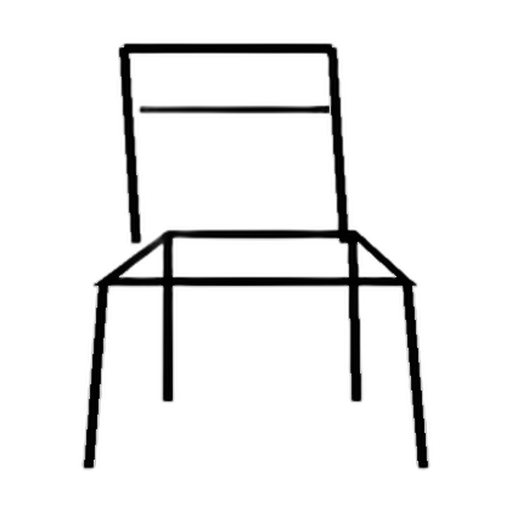

ControlNet input: (512, 512)
Mode: RGB
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/chair_controlnet_condition.png


In [49]:
from PIL import Image

# Convert transparent image to white background
rgba_image = processed_image.convert("RGBA")

white_background = Image.new(
    "RGBA",
    rgba_image.size,
    (255, 255, 255, 255)
)

control_image = Image.alpha_composite(
    white_background,
    rgba_image
).convert("RGB")

# Resize to 512x512
control_image = control_image.resize(
    (512, 512),
    Image.Resampling.LANCZOS
)

CONTROLNET_INPUT = f"{OUTPUT_DIR}/chair_controlnet_condition.png"

control_image.save(CONTROLNET_INPUT)

display(control_image)

print("ControlNet input:", control_image.size)
print("Mode:", control_image.mode)
print("Saved:", CONTROLNET_INPUT)

  0%|          | 0/30 [00:00<?, ?it/s]

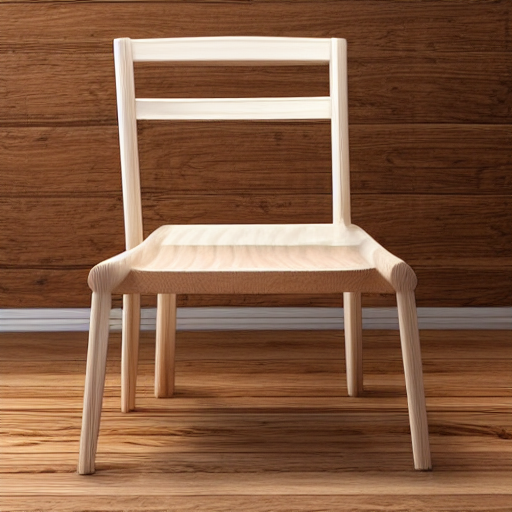

Generated image saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/chair_controlnet_generated.png
Image size: (512, 512)


In [50]:
prompt = """
A realistic wooden chair, three-quarter perspective view,
four clearly visible legs, solid seat with visible thickness,
upright rectangular backrest, accurate chair proportions,
natural wood material, professional studio photography,
single isolated object, centered composition,
plain white background, high detail, realistic 3D appearance.
"""

negative_prompt = """
multiple chairs, extra legs, missing legs, floating parts,
distorted geometry, broken structure, duplicate objects,
cropped object, blurry, low quality, text, watermark,
unrealistic proportions.
"""

generator = torch.Generator(device="cuda").manual_seed(42)

with torch.inference_mode():
    control_result = controlnet_pipeline(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=control_image,
        num_inference_steps=30,
        guidance_scale=7.5,
        controlnet_conditioning_scale=1.0,
        generator=generator,
        height=512,
        width=512
    )

controlnet_image = control_result.images[0]

display(controlnet_image)

CONTROLNET_OUTPUT = f"{OUTPUT_DIR}/chair_controlnet_generated.png"

controlnet_image.save(CONTROLNET_OUTPUT)

print("Generated image saved:", CONTROLNET_OUTPUT)
print("Image size:", controlnet_image.size)

In [51]:
CONTROLNET_OUTPUT = f"{OUTPUT_DIR}/chair_controlnet_generated.png"

controlnet_image.save(CONTROLNET_OUTPUT)

INPUT_IMAGE = CONTROLNET_OUTPUT

print("Next-stage input:", INPUT_IMAGE)
print("Image size:", controlnet_image.size)
print("Saved successfully.")

Next-stage input: /content/drive/MyDrive/Sketch2Shape_AI/outputs/chair_controlnet_generated.png
Image size: (512, 512)
Saved successfully.


In [52]:
from rembg import remove
from PIL import Image

# Use the ControlNet-generated image
input_image = Image.open(CONTROLNET_OUTPUT).convert("RGB")

# Remove background
chair_rgba = remove(input_image)

# Keep transparent background
chair_rgba = chair_rgba.convert("RGBA")

# Save background-removed image
BACKGROUND_REMOVED_PATH = (
    f"{OUTPUT_DIR}/chair_background_removed.png"
)

chair_rgba.save(BACKGROUND_REMOVED_PATH)

display(chair_rgba)

print("Background removal completed.")
print("Image size:", chair_rgba.size)
print("Mode:", chair_rgba.mode)
print("Saved:", BACKGROUND_REMOVED_PATH)

: 

: 

: 

In [1]:
import os
import sys
import subprocess
import importlib.util

print("========== RUNTIME CHECK ==========")
print("Python:", sys.version)
print("Python executable:", sys.executable)

print("\n========== GPU CHECK ==========")

import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Allocated:", round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")
    print("Reserved:", round(torch.cuda.memory_reserved() / 1024**3, 2), "GB")
    print("Free:", round(torch.cuda.mem_get_info()[0] / 1024**3, 2), "GB")

print("\n========== ONNX CHECK ==========")

if importlib.util.find_spec("onnxruntime"):
    import onnxruntime as ort
    print("ONNX Runtime:", ort.__version__)
    print("Providers:", ort.get_available_providers())
else:
    print("ONNX Runtime: NOT INSTALLED")

print("\n========== REMBG CHECK ==========")
print("rembg installed:", importlib.util.find_spec("rembg") is not None)

print("\n========== FILE CHECK ==========")

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"
OUTPUT_DIR = f"{BASE_DIR}/outputs"
CONTROLNET_OUTPUT = f"{OUTPUT_DIR}/chair_controlnet_generated.png"

print("Drive mounted:", os.path.exists(BASE_DIR))
print("ControlNet image exists:", os.path.exists(CONTROLNET_OUTPUT))

if os.path.exists(CONTROLNET_OUTPUT):
    from PIL import Image
    img = Image.open(CONTROLNET_OUTPUT)
    print("Image size:", img.size)
    print("Image mode:", img.mode)

print("\n========== CHECK COMPLETE ==========")

========== RUNTIME CHECK ==========
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Python executable: /usr/bin/python3

========== GPU CHECK ==========
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Allocated: 0.0 GB
Reserved: 0.0 GB
Free: 14.46 GB

========== ONNX CHECK ==========
ONNX Runtime: NOT INSTALLED

========== REMBG CHECK ==========
rembg installed: False

========== FILE CHECK ==========
Drive mounted: False
ControlNet image exists: False

========== CHECK COMPLETE ==========


In [4]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [6]:
import os

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"

print("MyDrive contents:")
print(os.listdir("/content/drive/MyDrive"))

print("\nProject folder exists:", os.path.exists(BASE_DIR))

if os.path.exists(BASE_DIR):
    print("\nProject contents:")
    print(os.listdir(BASE_DIR))

MyDrive contents:
['Screenshot_20190719_202851.jpg', 'merughati beauty.jpg', '1000013494.jpg', 'IMG_20240510_233026.jpg', 'Colab Notebooks', 'pankaj.gsheet', '5. Fertilizer & Water Plan Sheet (Sheet E).gsheet', '4. Crop Choice Sheet (Sheet D).gsheet', '3. Suggestions Sheet (Sheet C).gsheet', '2. Field Details Sheet (Sheet B).gsheet', '1. Onboarding Sheet (Sheet A).gsheet', '1. Onboarding Sheet (Sheet A).gscript', 'ଫସଲ ଚୟନ (ଓଡ଼ିଆ).gform', 'Crops Selection(English).gform', 'फसलों का चयन(हिंदी).gform', 'Farmer Onboarding.gform', 'Resume (1).gdoc', 'Resume.gdoc', 'Upahaar AI Proposal.gslides', 'Upahaar AI Detailed Proposal.gslides', 'IMG-20260203-WA0001.jpg', 'Screenshot_20260214_233504.jpg', 'ibm pankaj intro to LLMs.pdf', 'IBM Pankaj Gen AI for Software development.pdf', 'IBM Pankaj Granite moels for software development.pdf', 'Screenshot 2026-03-17 135737.png', 'pankaj ibm granite model fro software development Completion Certificate _ SkillsBuild.pdf', 'IBM_PROJECT_internship_pankaj.pd

In [7]:
import os

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"
MODEL_DIR = f"{BASE_DIR}/models"

print("========== MODEL DIRECTORY ==========")

for root, dirs, files in os.walk(MODEL_DIR):
    level = root.replace(MODEL_DIR, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        size_mb = os.path.getsize(os.path.join(root, file)) / (1024 ** 2)
        print(f"{indent}    {file} ({size_mb:.2f} MB)")

========== MODEL DIRECTORY ==========
models/
    instantmesh/
        instant_mesh_large.ckpt (1444.64 MB)
        diffusion_pytorch_model.bin (1651.82 MB)
        .cache/
            huggingface/
                CACHEDIR.TAG (0.00 MB)
                .gitignore (0.00 MB)
                download/
                    instant_mesh_large.ckpt.lock (0.00 MB)
                    instant_mesh_large.ckpt.metadata (0.00 MB)
                    diffusion_pytorch_model.bin.lock (0.00 MB)
                    diffusion_pytorch_model.bin.metadata (0.00 MB)
    zero123plus/
        .gitattributes (0.00 MB)
        model_index.json (0.00 MB)
        CACHEDIR.TAG (0.00 MB)
        .cache/
            huggingface/
                CACHEDIR.TAG (0.00 MB)
                .gitignore (0.00 MB)
                trees/
                    2da07e89919e1a130c9b5add1584c70c7aa065fd.json (0.00 MB)
                download/
                    model_index.json.lock (0.00 MB)
                    .gitattributes.loc

In [8]:
import os
import torch

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"

MODEL_DIR = f"{BASE_DIR}/models"
OUTPUT_DIR = f"{BASE_DIR}/outputs"

INSTANTMESH_DIR = f"{MODEL_DIR}/instantmesh"
ZERO123_DIR = f"{MODEL_DIR}/zero123plus"

MODEL_CKPT = f"{INSTANTMESH_DIR}/instant_mesh_large.ckpt"
UNET_CKPT = f"{INSTANTMESH_DIR}/diffusion_pytorch_model.bin"

REPO_DIR = "/content/InstantMesh"
CONFIG_PATH = f"{REPO_DIR}/configs/instant-mesh-large.yaml"

SNAPSHOT_DIR = (
    f"{ZERO123_DIR}/models--sudo-ai--zero123plus-v1.2/"
    "snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd"
)

VIEWS_DIR = f"{OUTPUT_DIR}/zero123_views"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(VIEWS_DIR, exist_ok=True)

print("GPU:", torch.cuda.get_device_name(0))
print("Free VRAM:", round(torch.cuda.mem_get_info()[0] / 1024**3, 2), "GB")

for name, path in {
    "InstantMesh checkpoint": MODEL_CKPT,
    "InstantMesh UNet": UNET_CKPT,
    "Zero123++ snapshot": SNAPSHOT_DIR,
    "InstantMesh config": CONFIG_PATH,
}.items():
    print(f"{name}: {'FOUND' if os.path.exists(path) else 'MISSING'}")

GPU: Tesla T4
Free VRAM: 14.46 GB
InstantMesh checkpoint: FOUND
InstantMesh UNet: FOUND
Zero123++ snapshot: FOUND
InstantMesh config: MISSING


In [9]:
import os

REPO_DIR = "/content/InstantMesh"
CONFIG_PATH = f"{REPO_DIR}/configs/instant-mesh-large.yaml"

print("Repository exists:", os.path.exists(REPO_DIR))
print("Configs folder exists:", os.path.exists(f"{REPO_DIR}/configs"))
print("Config exists:", os.path.exists(CONFIG_PATH))

Repository exists: False
Configs folder exists: False
Config exists: False


In [10]:
import os

REPO_DIR = "/content/InstantMesh"

if not os.path.exists(REPO_DIR):
    !git clone https://github.com/TencentARC/InstantMesh.git {REPO_DIR}
else:
    print("Repository already exists.")

CONFIG_PATH = f"{REPO_DIR}/configs/instant-mesh-large.yaml"

print("\nRepository cloned:", os.path.exists(REPO_DIR))
print("Config available:", os.path.exists(CONFIG_PATH))

Cloning into '/content/InstantMesh'...
remote: Enumerating objects: 334, done.
remote: Counting objects: 100% (176/176), done.
remote: Compressing objects: 100% (76/76), done.
remote: Total 334 (delta 130), reused 100 (delta 100), pack-reused 158 (from 1)
Receiving objects: 100% (334/334), 33.55 MiB | 27.33 MiB/s, done.
Resolving deltas: 100% (138/138), done.

Repository cloned: True
Config available: True


In [11]:
import sys
import torch
import transformers.pytorch_utils as pytorch_utils

sys.path.insert(0, REPO_DIR)

def find_pruneable_heads_and_indices(
    heads, n_heads, head_size, already_pruned_heads
):
    mask = torch.ones(n_heads, head_size)

    heads = set(heads) - already_pruned_heads

    for head in heads:
        head -= sum(1 for h in already_pruned_heads if h < head)
        mask[head] = 0

    index = torch.arange(mask.numel())[mask.view(-1).bool()]

    return heads, index.long()


pytorch_utils.find_pruneable_heads_and_indices = (
    find_pruneable_heads_and_indices
)

from src.models.encoder.dino import ViTModel

def compatible_get_head_mask(self, head_mask, num_hidden_layers):
    if head_mask is None:
        return [None] * num_hidden_layers

    return self._convert_head_mask_to_5d(
        head_mask, num_hidden_layers
    )


ViTModel.get_head_mask = compatible_get_head_mask

print("InstantMesh compatibility patches restored.")
print("CUDA available:", torch.cuda.is_available())
print("Config:", CONFIG_PATH)

InstantMesh compatibility patches restored.
CUDA available: True
Config: /content/InstantMesh/configs/instant-mesh-large.yaml


In [12]:
import importlib.util

packages = [
    "rembg",
    "onnxruntime",
    "PIL",
    "cv2",
    "numpy",
    "trimesh"
]

for package in packages:
    print(
        f"{package}:",
        "INSTALLED" if importlib.util.find_spec(package) else "MISSING"
    )

rembg: MISSING
onnxruntime: MISSING
PIL: INSTALLED
cv2: INSTALLED
numpy: INSTALLED
trimesh: MISSING


In [14]:
import sys
import subprocess

print("Python executable:", sys.executable)

print("\nPip version:")
subprocess.run([sys.executable, "-m", "pip", "--version"])

print("\nPackage installation status:")
subprocess.run([
    sys.executable, "-m", "pip",
    "show", "rembg", "onnxruntime", "trimesh"
])

Python executable: /usr/bin/python3

Pip version:

Package installation status:


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'show', 'rembg', 'onnxruntime', 'trimesh'], returncode=1)

In [15]:
import sys
import importlib.util
import subprocess

print("Python:", sys.executable)

print("\nPip module available:",
      importlib.util.find_spec("pip") is not None)

result = subprocess.run(
    [sys.executable, "-m", "pip", "--version"],
    capture_output=True,
    text=True
)

print("\nReturn code:", result.returncode)
print("STDOUT:", result.stdout)
print("STDERR:", result.stderr)

print("\nPython paths:")
print("\n".join(sys.path[:5]))

Python: /usr/bin/python3

Pip module available: True

Return code: 0
STDOUT: pip 26.2.2 from /usr/local/lib/python3.13/dist-packages/pip (python 3.13)

STDERR: 

Python paths:
/content/InstantMesh
/content
/env/python
/usr/lib/python313.zip
/usr/lib/python3.13


In [16]:
import sys
import subprocess

packages = [
    "rembg",
    "onnxruntime",
    "trimesh"
]

result = subprocess.run(
    [sys.executable, "-m", "pip", "install", *packages],
    text=True
)

print("Installation exit code:", result.returncode)

Installation exit code: 0


In [17]:
import rembg
import onnxruntime as ort
import trimesh

print("rembg:", rembg.__version__)
print("ONNX Runtime:", ort.__version__)
print("ONNX providers:", ort.get_available_providers())
print("trimesh:", trimesh.__version__)

rembg: 2.0.86
ONNX Runtime: 1.31.1
ONNX providers: ['AzureExecutionProvider', 'CPUExecutionProvider']
trimesh: 5.2.0


Image exists: True
Image size: (512, 512)
Image mode: RGB


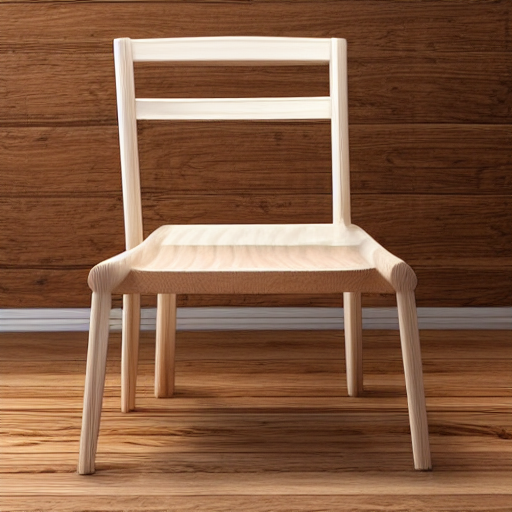

In [18]:
import os
from PIL import Image

CONTROLNET_OUTPUT = (
    f"{BASE_DIR}/outputs/chair_controlnet_generated.png"
)

print("Image exists:", os.path.exists(CONTROLNET_OUTPUT))

if os.path.exists(CONTROLNET_OUTPUT):
    img = Image.open(CONTROLNET_OUTPUT)
    print("Image size:", img.size)
    print("Image mode:", img.mode)
    display(img)

  0%|                                               | 0.00/176M [00:00<?, ?B/s]

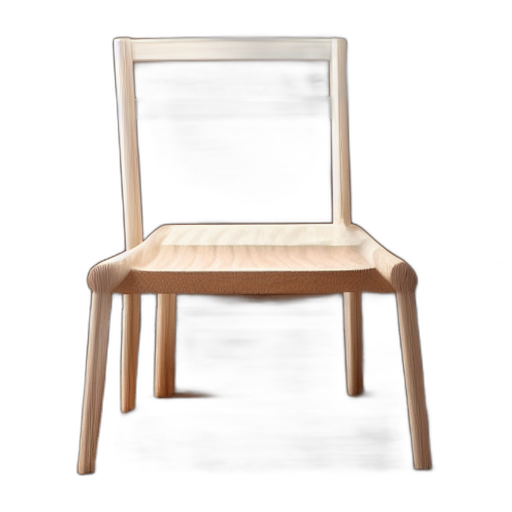

Background removal completed.
Image size: (512, 512)
Image mode: RGBA
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/chair_background_removed.png


In [19]:
import onnxruntime as ort
from rembg import remove, new_session
from PIL import Image
import os

# Limit ONNX CPU threads
options = ort.SessionOptions()
options.intra_op_num_threads = 2
options.inter_op_num_threads = 1

# Force CPU execution
session = new_session(
    "u2net",
    providers=["CPUExecutionProvider"],
    sess_options=options
)

# Load generated chair
input_image = Image.open(CONTROLNET_OUTPUT).convert("RGB")

# Remove background
chair_rgba = remove(
    input_image,
    session=session
).convert("RGBA")

# Save result
BACKGROUND_REMOVED_PATH = (
    f"{OUTPUT_DIR}/chair_background_removed.png"
)

chair_rgba.save(BACKGROUND_REMOVED_PATH)

display(chair_rgba)

print("Background removal completed.")
print("Image size:", chair_rgba.size)
print("Image mode:", chair_rgba.mode)
print("Saved:", BACKGROUND_REMOVED_PATH)

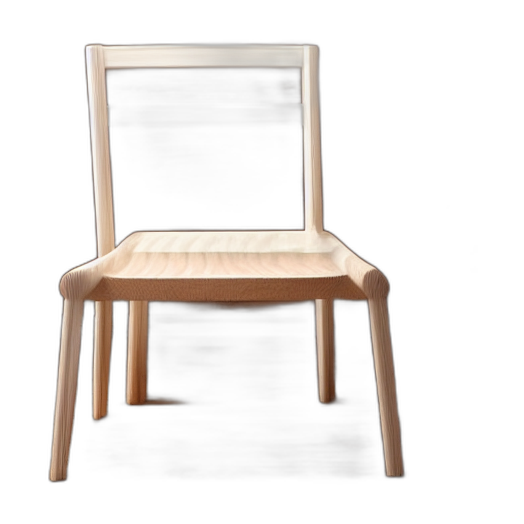

Prepared successfully.
Size: (524, 524)
Mode: RGBA
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/chair_zero123_input.png


In [20]:
import os
from PIL import Image
from src.utils.infer_util import resize_foreground

BACKGROUND_REMOVED_PATH = (
    f"{OUTPUT_DIR}/chair_background_removed.png"
)

# Verify previous step completed
assert os.path.exists(BACKGROUND_REMOVED_PATH), (
    "Background-removed image not found. Run Step 16 first."
)

# Load transparent chair
chair_rgba = Image.open(BACKGROUND_REMOVED_PATH).convert("RGBA")

# Center and resize foreground
chair_prepared = resize_foreground(chair_rgba, 0.85)

# Save Zero123++ input
ZERO123_INPUT = f"{OUTPUT_DIR}/chair_zero123_input.png"

chair_prepared.save(ZERO123_INPUT)

display(chair_prepared)

print("Prepared successfully.")
print("Size:", chair_prepared.size)
print("Mode:", chair_prepared.mode)
print("Saved:", ZERO123_INPUT)

In [22]:
import torch
from diffusers import (
    DiffusionPipeline,
    EulerAncestralDiscreteScheduler
)

pipeline = DiffusionPipeline.from_pretrained(
    SNAPSHOT_DIR,
    custom_pipeline=f"{REPO_DIR}/zero123plus",
    torch_dtype=torch.float16,
    local_files_only=True,
    trust_remote_code=True
)

pipeline.scheduler = EulerAncestralDiscreteScheduler.from_config(
    pipeline.scheduler.config,
    timestep_spacing="trailing"
)

pipeline = pipeline.to("cuda")

print("Zero123++ loaded successfully!")

print(
    "GPU allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

print(
    "GPU free:",
    round(torch.cuda.mem_get_info()[0] / 1024**3, 2),
    "GB"
)

Loading pipeline components...:   0%|          | 0/8 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/520 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:04<?, ?it/s]

Zero123++ loaded successfully!
GPU allocated: 3.6 GB
GPU free: 10.7 GB


  0%|          | 0/75 [00:00<?, ?it/s]

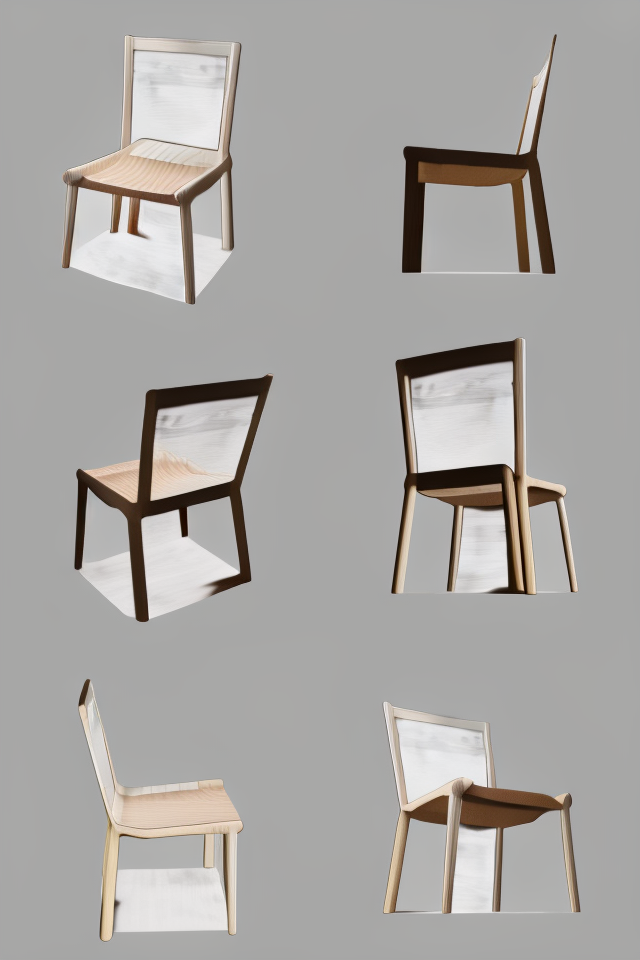

Generated views: Contact sheet
Contact sheet size: (640, 960)
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair_zero123_views.png


In [23]:
import torch
from PIL import Image
import os

# Load prepared chair
input_image = Image.open(ZERO123_INPUT).convert("RGBA")

# Generate six views
with torch.inference_mode():
    result = pipeline(
        input_image,
        num_inference_steps=75,
        generator=torch.Generator(device="cuda").manual_seed(42)
    )

# Contact sheet
views = result.images[0]

VIEWS_OUTPUT = f"{VIEWS_DIR}/chair_zero123_views.png"
views.save(VIEWS_OUTPUT)

display(views)

print("Generated views:", len(views) if isinstance(views, list) else "Contact sheet")
print("Contact sheet size:", views.size)
print("Saved:", VIEWS_OUTPUT)

In [24]:
from PIL import Image
import os

contact_sheet = Image.open(VIEWS_OUTPUT).convert("RGB")

width, height = contact_sheet.size

view_width = width // 2
view_height = height // 3

os.makedirs(VIEWS_DIR, exist_ok=True)

view_paths = []

for row in range(3):
    for col in range(2):

        left = col * view_width
        upper = row * view_height

        right = left + view_width
        lower = upper + view_height

        view = contact_sheet.crop(
            (left, upper, right, lower)
        )

        view_path = f"{VIEWS_DIR}/chair_view_{row*2+col+1}.png"
        view.save(view_path)

        view_paths.append(view_path)

        print(f"Saved: {view_path}")

print("\nTotal individual views:", len(view_paths))

Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair_view_1.png
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair_view_2.png
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair_view_3.png
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair_view_4.png
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair_view_5.png
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair_view_6.png

Total individual views: 6


In [25]:
import gc
import torch

# Release Zero123++ pipeline
del pipeline

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

allocated = torch.cuda.memory_allocated() / 1024**3
reserved = torch.cuda.memory_reserved() / 1024**3
free = torch.cuda.mem_get_info()[0] / 1024**3

print("Zero123++ released.")
print(f"GPU allocated: {allocated:.2f} GB")
print(f"GPU reserved: {reserved:.2f} GB")
print(f"GPU free: {free:.2f} GB")

Zero123++ released.
GPU allocated: 0.01 GB
GPU reserved: 0.06 GB
GPU free: 14.36 GB


In [28]:
import sys
import subprocess
import torch
import shutil

print("========== CUDA ENVIRONMENT ==========")
print("PyTorch:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

print("\n========== BUILD TOOLS ==========")
print("NVCC:", shutil.which("nvcc"))
print("GCC:", shutil.which("gcc"))
print("G++:", shutil.which("g++"))

print("\n========== NVIDIA COMPILER ==========")

if shutil.which("nvcc"):
    subprocess.run(["nvcc", "--version"])

print("\n========== INSTALLATION LOG ==========")

result = subprocess.run(
    [
        sys.executable, "-m", "pip",
        "install", "-v",
        "git+https://github.com/NVlabs/nvdiffrast.git"
    ],
    capture_output=True,
    text=True
)

print("Exit code:", result.returncode)

print("\nLast 60 lines of error/output:")

output = (result.stdout + "\n" + result.stderr).splitlines()

for line in output[-60:]:
    print(line)

========== CUDA ENVIRONMENT ==========
PyTorch: 2.11.0+cu130
CUDA version: 13.0
CUDA available: True

========== BUILD TOOLS ==========
NVCC: /usr/local/cuda/bin/nvcc
GCC: /usr/bin/gcc
G++: /usr/bin/g++

========== NVIDIA COMPILER ==========

========== INSTALLATION LOG ==========
Exit code: 1

Last 60 lines of error/output:
  365000000 > 31
  Using cached setuptools-84.2.1-py3-none-any.whl (876 kB)
  Looking up "https://files.pythonhosted.org/packages/2e/29/69cfbb602cd91690c55d38ba9fe53e6a7e76a6fa647bf38f19c138d25449/wheel-0.48.0-py3-none-any.whl" in the cache
  Current age based on date: 31
  Ignoring unknown cache-control directive: immutable
  Freshness lifetime from max-age: 365000000
  The response is "fresh", returning cached response
  365000000 > 31
  Using cached wheel-0.48.0-py3-none-any.whl (33 kB)
  Looking up "https://files.pythonhosted.org/packages/6e/53/ebfed7b689c338dd8ebeec9c0730c8d56821292f14e2536e5f3ef1a05744/ninja-1.13.2-py3-none-manylinux2014_x86_64.manylinux_2_17

In [29]:
import sys
import subprocess

result = subprocess.run(
    [
        sys.executable, "-m", "pip",
        "install", "setuptools==81.0.0"
    ],
    text=True
)

print("Exit code:", result.returncode)

Exit code: 0


In [30]:
import sys
import subprocess

result = subprocess.run(
    [
        sys.executable, "-m", "pip",
        "install",
        "--no-build-isolation",
        "git+https://github.com/NVlabs/nvdiffrast.git"
    ],
    text=True
)

print("Installation exit code:", result.returncode)

Installation exit code: 0


In [32]:
import torch
import nvdiffrast.torch as dr

print("nvdiffrast imported successfully!")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print(
    "Free VRAM:",
    round(torch.cuda.mem_get_info()[0] / 1024**3, 2),
    "GB"
)

nvdiffrast imported successfully!
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Free VRAM: 14.36 GB


In [34]:
import sys
import subprocess

result = subprocess.run(
    [
        sys.executable, "-m", "pip",
        "install", "xatlas"
    ],
    text=True
)

print("Installation exit code:", result.returncode)

Installation exit code: 0


In [35]:
import xatlas
import trimesh
import nvdiffrast.torch as dr

print("xatlas:", xatlas.__version__ if hasattr(xatlas, "__version__") else "Imported")
print("trimesh:", trimesh.__version__)
print("nvdiffrast: Imported successfully")

xatlas: 0.0.11
trimesh: 5.2.0
nvdiffrast: Imported successfully


In [36]:
import torch
from omegaconf import OmegaConf
from src.utils.train_util import instantiate_from_config

# Load configuration
config = OmegaConf.load(CONFIG_PATH)

# Reduce grid resolution for T4
config.model_config.params.grid_res = 64

# Initialize model
model = instantiate_from_config(config.model_config)

# Load checkpoint
checkpoint = torch.load(
    MODEL_CKPT,
    map_location="cpu",
    weights_only=True
)

missing, unexpected = model.load_state_dict(
    checkpoint,
    strict=True
)

# Move to GPU
model = model.to("cuda", dtype=torch.float16)
model.eval()

print("InstantMesh loaded successfully!")
print("Missing keys:", missing)
print("Unexpected keys:", unexpected)

print(
    "GPU allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)
print(
    "GPU free:",
    round(torch.cuda.mem_get_info()[0] / 1024**3, 2),
    "GB"
)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  343MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: facebook/dino-vitb16
Key                                              | Status  | 
-------------------------------------------------+---------+-
encoder.layer.{0...11}.adaLN_modulation.1.bias   | MISSING | 
encoder.layer.{0...11}.adaLN_modulation.1.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

preprocessor_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

RuntimeError: Error(s) in loading state_dict for InstantMesh:
	Missing key(s) in state_dict: "encoder.model.embeddings.cls_token", "encoder.model.embeddings.position_embeddings", "encoder.model.embeddings.patch_embeddings.projection.weight", "encoder.model.embeddings.patch_embeddings.projection.bias", "encoder.model.encoder.layer.0.attention.attention.query.weight", "encoder.model.encoder.layer.0.attention.attention.query.bias", "encoder.model.encoder.layer.0.attention.attention.key.weight", "encoder.model.encoder.layer.0.attention.attention.key.bias", "encoder.model.encoder.layer.0.attention.attention.value.weight", "encoder.model.encoder.layer.0.attention.attention.value.bias", "encoder.model.encoder.layer.0.attention.output.dense.weight", "encoder.model.encoder.layer.0.attention.output.dense.bias", "encoder.model.encoder.layer.0.intermediate.dense.weight", "encoder.model.encoder.layer.0.intermediate.dense.bias", "encoder.model.encoder.layer.0.output.dense.weight", "encoder.model.enc

In [37]:
import torch

checkpoint = torch.load(
    MODEL_CKPT,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))
print("Top-level keys:", checkpoint.keys())

state_dict = checkpoint["state_dict"]

print("\nState dict type:", type(state_dict))
print("Number of parameters:", len(state_dict))

print("\nFirst 10 parameter names:")

for i, key in enumerate(state_dict.keys()):
    if i == 10:
        break
    print(key)

Checkpoint type: <class 'dict'>
Top-level keys: dict_keys(['state_dict'])

State dict type: <class 'dict'>
Number of parameters: 519

First 10 parameter names:
lrm_generator.encoder.model.embeddings.cls_token
lrm_generator.encoder.model.embeddings.position_embeddings
lrm_generator.encoder.model.embeddings.patch_embeddings.projection.weight
lrm_generator.encoder.model.embeddings.patch_embeddings.projection.bias
lrm_generator.encoder.model.encoder.layer.0.attention.attention.query.weight
lrm_generator.encoder.model.encoder.layer.0.attention.attention.query.bias
lrm_generator.encoder.model.encoder.layer.0.attention.attention.key.weight
lrm_generator.encoder.model.encoder.layer.0.attention.attention.key.bias
lrm_generator.encoder.model.encoder.layer.0.attention.attention.value.weight
lrm_generator.encoder.model.encoder.layer.0.attention.attention.value.bias


In [39]:
from collections import OrderedDict

state_dict = checkpoint["state_dict"]

clean_state_dict = OrderedDict(
    (key.removeprefix("lrm_generator."), value)
    for key, value in state_dict.items()
)

missing, unexpected = model.load_state_dict(
    clean_state_dict,
    strict=True
)

print("InstantMesh checkpoint loaded successfully!")
print("Missing keys:", missing)
print("Unexpected keys:", unexpected)

InstantMesh checkpoint loaded successfully!
Missing keys: []
Unexpected keys: []


In [41]:
model = model.to("cuda")
model.eval()

print("Model moved to:", next(model.parameters()).device)
print("Model is in evaluation mode:", not model.training)

print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

Model moved to: cuda:0
Model is in evaluation mode: True
GPU memory allocated: 1.42 GB


In [42]:
from PIL import Image
import os

view_paths = [
    f"{VIEWS_DIR}/chair_view_{i}.png"
    for i in range(1, 7)
]

views = [Image.open(path).convert("RGB") for path in view_paths]

for i, view in enumerate(views, 1):
    print(f"View {i}: {view.size}")

print("Total views:", len(views))

View 1: (320, 320)
View 2: (320, 320)
View 3: (320, 320)
View 4: (320, 320)
View 5: (320, 320)
View 6: (320, 320)
Total views: 6


In [43]:
import torchvision.transforms as T
import torch

transform = T.Compose([
    T.ToTensor(),
    T.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

input_views = torch.stack([
    transform(view) for view in views
])

input_views = input_views.unsqueeze(0).to(
    device="cuda",
    dtype=torch.float16
)

print("Input tensor shape:", input_views.shape)
print("Input tensor device:", input_views.device)
print("Input tensor dtype:", input_views.dtype)

Input tensor shape: torch.Size([1, 6, 3, 320, 320])
Input tensor device: cuda:0
Input tensor dtype: torch.float16


In [45]:
import src.utils.infer_util as infer_util

print([
    name for name in dir(infer_util)
    if not name.startswith("_")
])

['Any', 'Image', 'PIL', 'imageio', 'images_to_video', 'np', 'os', 'rembg', 'remove_background', 'resize_foreground', 'save_video', 'torch']


In [46]:
import src.utils.camera_util as camera_util

print([
    name for name in dir(camera_util)
    if not name.startswith("_")
])

['F', 'FOV_to_intrinsics', 'center_looking_at_camera_pose', 'get_circular_camera_poses', 'get_zero123plus_input_cameras', 'np', 'pad_camera_extrinsics_4x4', 'spherical_camera_pose', 'torch']


In [47]:
import inspect

print(inspect.signature(camera_util.get_zero123plus_input_cameras))
print(inspect.getsource(camera_util.get_zero123plus_input_cameras))


(batch_size=1, radius=4.0, fov=30.0)
def get_zero123plus_input_cameras(batch_size=1, radius=4.0, fov=30.0):
    """
    Get the input camera parameters.
    """
    azimuths = np.array([30, 90, 150, 210, 270, 330]).astype(float)
    elevations = np.array([20, -10, 20, -10, 20, -10]).astype(float)
    
    c2ws = spherical_camera_pose(azimuths, elevations, radius)
    c2ws = c2ws.float().flatten(-2)

    Ks = FOV_to_intrinsics(fov).unsqueeze(0).repeat(6, 1, 1).float().flatten(-2)

    extrinsics = c2ws[:, :12]
    intrinsics = torch.stack([Ks[:, 0], Ks[:, 4], Ks[:, 2], Ks[:, 5]], dim=-1)
    cameras = torch.cat([extrinsics, intrinsics], dim=-1)

    return cameras.unsqueeze(0).repeat(batch_size, 1, 1)



In [48]:
camera_params = camera_util.get_zero123plus_input_cameras(
    batch_size=1,
    radius=4.0,
    fov=30.0
)

camera_params = camera_params.to(
    device="cuda",
    dtype=torch.float16
)

print("Camera parameters shape:", camera_params.shape)
print("Camera device:", camera_params.device)
print("Camera dtype:", camera_params.dtype)

Camera parameters shape: torch.Size([1, 6, 16])
Camera device: cuda:0
Camera dtype: torch.float16


In [49]:
import inspect

print("Forward signature:")
print(inspect.signature(model.forward))

print("\nForward source:")
print(inspect.getsource(model.forward))

Forward signature:
(images, cameras, render_cameras, render_size: int)

Forward source:
    def forward(self, images, cameras, render_cameras, render_size: int):
        # images: [B, V, C_img, H_img, W_img]
        # cameras: [B, V, 16]
        # render_cameras: [B, M, D_cam_render]
        # render_size: int
        B, M = render_cameras.shape[:2]

        planes = self.forward_planes(images, cameras)
        out = self.forward_geometry(planes, render_cameras, render_size=render_size)

        return {
            'planes': planes,
            **out
        }



In [50]:
print(inspect.signature(camera_util.get_circular_camera_poses))
print(inspect.getsource(camera_util.get_circular_camera_poses))


(M=120, radius=2.5, elevation=30.0)
def get_circular_camera_poses(M=120, radius=2.5, elevation=30.0):
    # M: number of circular views
    # radius: camera dist to center
    # elevation: elevation degrees of the camera
    # return: (M, 4, 4)
    assert M > 0 and radius > 0

    elevation = np.deg2rad(elevation)

    camera_positions = []
    for i in range(M):
        azimuth = 2 * np.pi * i / M
        x = radius * np.cos(elevation) * np.cos(azimuth)
        y = radius * np.cos(elevation) * np.sin(azimuth)
        z = radius * np.sin(elevation)
        camera_positions.append([x, y, z])
    camera_positions = np.array(camera_positions)
    camera_positions = torch.from_numpy(camera_positions).float()
    extrinsics = center_looking_at_camera_pose(camera_positions)
    return extrinsics



In [51]:
render_cameras = camera_util.get_circular_camera_poses(
    M=60,
    radius=2.5,
    elevation=30.0
)

render_cameras = render_cameras.unsqueeze(0).to(
    device="cuda",
    dtype=torch.float16
)

print("Render cameras shape:", render_cameras.shape)
print("Device:", render_cameras.device)
print("Dtype:", render_cameras.dtype)

Render cameras shape: torch.Size([1, 60, 4, 4])
Device: cuda:0
Dtype: torch.float16


In [53]:
camera_params = camera_params.float()

print("Model camera layer dtype:",
      next(model.encoder.camera_embedder.parameters()).dtype)

print("Camera parameters dtype:", camera_params.dtype)

Model camera layer dtype: torch.float32
Camera parameters dtype: torch.float32


In [54]:
with torch.inference_mode():
    planes = model.forward_planes(
        input_views,
        camera_params
    )

print("Triplane shape:", planes.shape)
print("Triplane dtype:", planes.dtype)

[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


Triplane shape: torch.Size([1, 3, 80, 64, 64])
Triplane dtype: torch.float32


In [55]:
import inspect

print("Geometry method:")
print(inspect.signature(model.forward_geometry))

print("\nGeometry source:")
print(inspect.getsource(model.forward_geometry))

Geometry method:
(planes, render_cameras, render_size=256)

Geometry source:
    def forward_geometry(self, planes, render_cameras, render_size=256):
        '''
        Main function of our Generator. It first generate 3D mesh, then render it into 2D image
        with given `render_cameras`.
        :param planes: triplane features
        :param render_cameras: cameras to render generated 3D shape
        '''
        B, NV = render_cameras.shape[:2]

        # Generate 3D mesh first
        mesh_v, mesh_f, sdf, deformation, v_deformed, sdf_reg_loss = self.get_geometry_prediction(planes)

        # Render the mesh into 2D image (get 3d position of each image plane)
        cam_mv = render_cameras
        run_n_view = cam_mv.shape[1]
        antilias_mask, hard_mask, tex_pos, depth, normal = self.render_mesh(mesh_v, mesh_f, cam_mv, render_size=render_size)

        tex_hard_mask = hard_mask
        tex_pos = [torch.cat([pos[i_view:i_view + 1] for i_view in range(run_n_view)], dim=2) f

In [56]:
import inspect

print(inspect.signature(model.get_geometry_prediction))
print(inspect.getsource(model.get_geometry_prediction))

(planes=None)
    def get_geometry_prediction(self, planes=None):
        '''
        Function to generate mesh with give triplanes
        :param planes: triplane features
        '''
        # Step 1: first get the sdf and deformation value for each vertices in the tetrahedon grid.
        sdf, deformation, sdf_reg_loss, weight = self.get_sdf_deformation_prediction(planes)
        v_deformed = self.geometry.verts.unsqueeze(dim=0).expand(sdf.shape[0], -1, -1) + deformation
        tets = self.geometry.indices
        n_batch = planes.shape[0]
        v_list = []
        f_list = []
        flexicubes_surface_reg_list = []
        
        # Step 2: Using marching tet to obtain the mesh
        for i_batch in range(n_batch):
            verts, faces, flexicubes_surface_reg = self.geometry.get_mesh(
                v_deformed[i_batch], 
                sdf[i_batch].squeeze(dim=-1),
                with_uv=False, 
                indices=tets, 
                weight_n=weight[i_batch].sq

In [59]:
print("Model configuration:")
print(config.model_config)

print("\nGeometry-related model attributes:")
print([
    name for name in dir(model)
    if "geometry" in name.lower()
])

Model configuration:
{'target': 'src.models.lrm_mesh.InstantMesh', 'params': {'encoder_feat_dim': 768, 'encoder_freeze': False, 'encoder_model_name': 'facebook/dino-vitb16', 'transformer_dim': 1024, 'transformer_layers': 16, 'transformer_heads': 16, 'triplane_low_res': 32, 'triplane_high_res': 64, 'triplane_dim': 80, 'rendering_samples_per_ray': 128, 'grid_res': 64, 'grid_scale': 2.1}}

Geometry-related model attributes:
['forward_geometry', 'get_geometry_prediction', 'init_flexicubes_geometry']


In [60]:
import inspect

print(inspect.signature(model.init_flexicubes_geometry))
print(inspect.getsource(model.init_flexicubes_geometry))

(device, fovy=50.0)
    def init_flexicubes_geometry(self, device, fovy=50.0):
        camera = PerspectiveCamera(fovy=fovy, device=device)
        renderer = NeuralRender(device, camera_model=camera)
        self.geometry = FlexiCubesGeometry(
            grid_res=self.grid_res, 
            scale=self.grid_scale, 
            renderer=renderer, 
            render_type='neural_render',
            device=device,
        )



In [61]:
model.init_flexicubes_geometry(
    device="cuda",
    fovy=50.0
)

print("Geometry initialized:", hasattr(model, "geometry"))
print("Grid resolution:", model.geometry.grid_res)
print("Grid scale:", model.geometry.scale)
print("Grid vertices:", model.geometry.verts.shape)
print("Grid indices:", model.geometry.indices.shape)

Geometry initialized: True
Grid resolution: 64


AttributeError: 'FlexiCubesGeometry' object has no attribute 'scale'

In [62]:
print("Geometry initialized:", hasattr(model, "geometry"))
print("Grid vertices:", model.geometry.verts.shape)
print("Grid indices:", model.geometry.indices.shape)
print("Grid resolution:", model.grid_res)
print("Grid scale:", model.grid_scale)


Geometry initialized: True
Grid vertices: torch.Size([274625, 3])
Grid indices: torch.Size([262144, 8])
Grid resolution: 64
Grid scale: 2.1


In [63]:
with torch.inference_mode():
    mesh_vertices, mesh_faces, sdf, deformation, v_deformed, reg_loss = (
        model.get_geometry_prediction(planes)
    )

vertices = mesh_vertices[0]
faces = mesh_faces[0]

print("Vertices:", vertices.shape)
print("Faces:", faces.shape)
print("Finite vertices:", torch.isfinite(vertices).all().item())
print("Number of vertices:", len(vertices))
print("Number of faces:", len(faces))

Vertices: torch.Size([43882, 3])
Faces: torch.Size([87560, 3])
Finite vertices: True
Number of vertices: 43882
Number of faces: 87560


In [64]:
import trimesh
import numpy as np

vertices_np = vertices.detach().cpu().numpy()
faces_np = faces.detach().cpu().numpy()

chair_mesh = trimesh.Trimesh(
    vertices=vertices_np,
    faces=faces_np,
    process=True
)

print("Mesh created successfully")
print("Vertices:", len(chair_mesh.vertices))
print("Faces:", len(chair_mesh.faces))
print("Watertight:", chair_mesh.is_watertight)
print("Winding consistent:", chair_mesh.is_winding_consistent)
print("Surface area:", chair_mesh.area)
print("Volume:", chair_mesh.volume)

Mesh created successfully
Vertices: 43882
Faces: 87560
Watertight: True
Winding consistent: True
Surface area: 34.59329472879449
Volume: 6.0001161718873375


In [65]:
GLB_PATH = f"{OUTPUT_DIR}/chair.glb"

chair_mesh.export(GLB_PATH, file_type="glb")

print("GLB exported successfully!")
print("File:", GLB_PATH)
print("File size:",
      round(os.path.getsize(GLB_PATH) / (1024 * 1024), 2),
      "MB")

GLB exported successfully!
File: /content/drive/MyDrive/Sketch2Shape_AI/outputs/chair.glb
File size: 1.5 MB


In [66]:
loaded_scene = trimesh.load(GLB_PATH, force="scene")

print("GLB loaded successfully!")
print("Scene geometry count:", len(loaded_scene.geometry))
print("Geometry types:", [
    type(g).__name__ for g in loaded_scene.geometry.values()
])
print("Scene bounds:", loaded_scene.bounds)

GLB loaded successfully!
Scene geometry count: 1
Geometry types: ['Trimesh']
Scene bounds: [[-0.98471546 -0.98248589 -0.98913634]
 [ 0.98601121  0.98363394  0.98802805]]


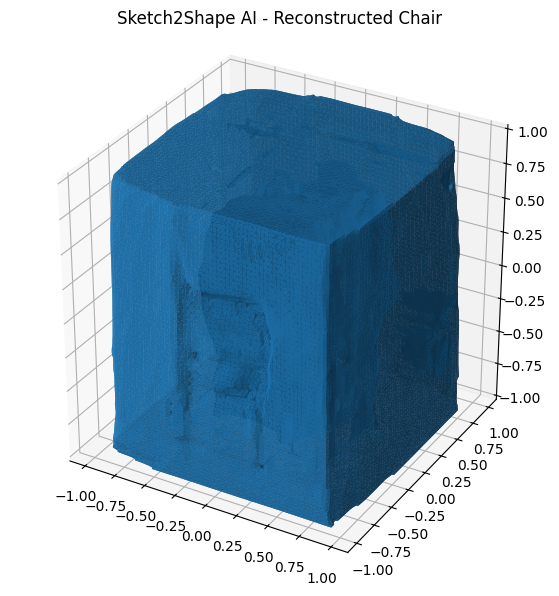

In [67]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot_trisurf(
    chair_mesh.vertices[:, 0],
    chair_mesh.vertices[:, 1],
    chair_mesh.vertices[:, 2],
    triangles=chair_mesh.faces,
    linewidth=0.05,
    alpha=0.95
)

ax.set_title("Sketch2Shape AI - Reconstructed Chair")
ax.set_box_aspect([1, 1, 1])

plt.show()

In [68]:
print("SDF statistics:")
print("Min:", sdf.min().item())
print("Max:", sdf.max().item())
print("Mean:", sdf.mean().item())

print("\nDeformation statistics:")
print("Min:", deformation.min().item())
print("Max:", deformation.max().item())
print("Mean:", deformation.mean().item())

print("\nMesh dimensions:")
print("Bounds:", chair_mesh.bounds)
print("Extents:", chair_mesh.extents)

print("\nMesh components:", len(chair_mesh.split(only_watertight=False)))

SDF statistics:
Min: -2.371255874633789
Max: 14.655454635620117
Mean: 1.4301257133483887

Deformation statistics:
Min: -0.003904408309608698
Max: 0.003905419260263443
Mean: -0.0002812660823110491

Mesh dimensions:
Bounds: [[-0.98471546 -0.98248589 -0.98913634]
 [ 0.98601121  0.98363394  0.98802805]]
Extents: [1.97072667 1.96611983 1.97716439]

Mesh components: 109


In [69]:
components = sorted(
    chair_mesh.split(only_watertight=False),
    key=lambda mesh: len(mesh.faces),
    reverse=True
)

print("Total components:", len(components))

print("\nLargest 10 components:")

for i, component in enumerate(components[:10]):
    print(
        f"Component {i+1}: "
        f"Vertices={len(component.vertices)}, "
        f"Faces={len(component.faces)}, "
        f"Watertight={component.is_watertight}, "
        f"Bounds={component.extents.round(3)}"
    )

Total components: 109

Largest 10 components:
Component 1: Vertices=41324, Faces=82856, Watertight=True, Bounds=[1.971 1.966 1.977]
Component 2: Vertices=422, Faces=856, Watertight=True, Bounds=[0.422 0.209 0.26 ]
Component 3: Vertices=198, Faces=396, Watertight=True, Bounds=[0.25  0.066 0.28 ]
Component 4: Vertices=180, Faces=356, Watertight=True, Bounds=[0.609 0.117 0.038]
Component 5: Vertices=128, Faces=252, Watertight=True, Bounds=[0.466 0.013 0.143]
Component 6: Vertices=88, Faces=172, Watertight=True, Bounds=[0.076 0.409 0.04 ]
Component 7: Vertices=80, Faces=156, Watertight=True, Bounds=[0.307 0.115 0.025]
Component 8: Vertices=68, Faces=132, Watertight=True, Bounds=[0.253 0.101 0.012]
Component 9: Vertices=58, Faces=112, Watertight=True, Bounds=[0.08  0.208 0.039]
Component 10: Vertices=56, Faces=108, Watertight=True, Bounds=[0.083 0.238 0.019]


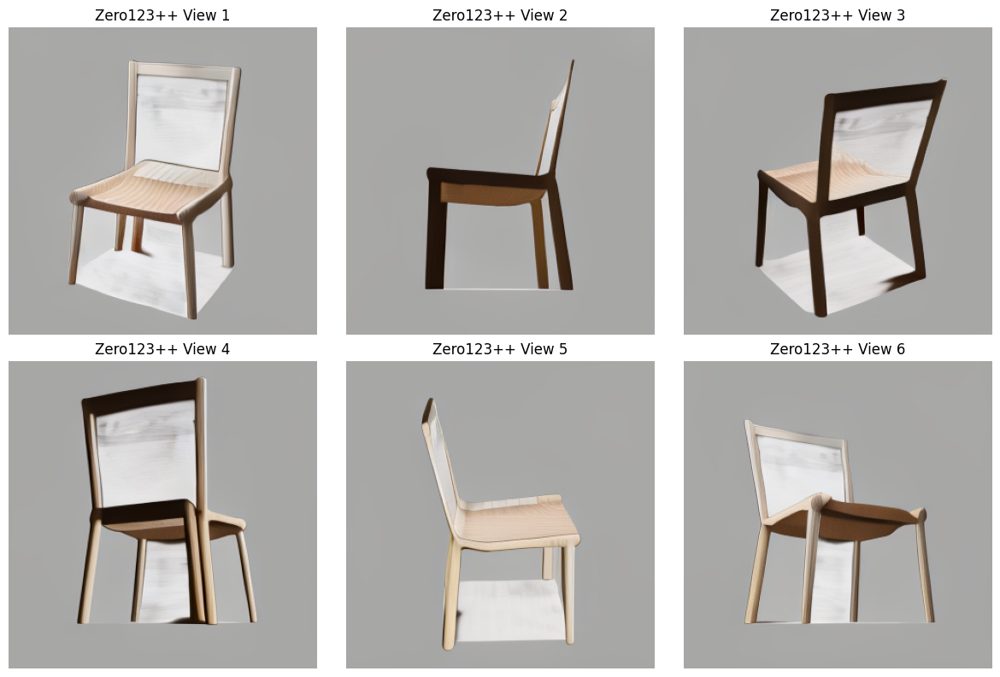

In [70]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(views[i])
    ax.set_title(f"Zero123++ View {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

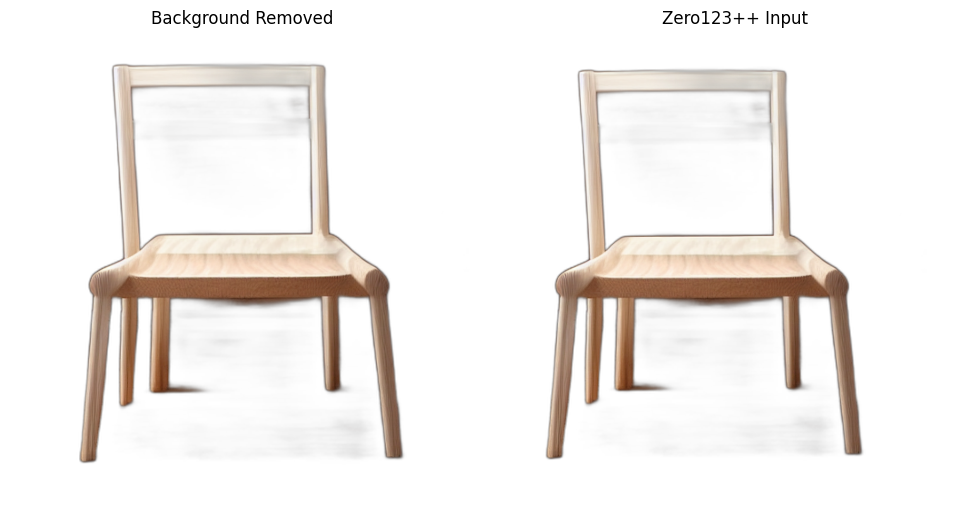

In [71]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(
    Image.open(BACKGROUND_REMOVED_PATH)
)
axes[0].set_title("Background Removed")

axes[1].imshow(
    Image.open(ZERO123_INPUT)
)
axes[1].set_title("Zero123++ Input")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

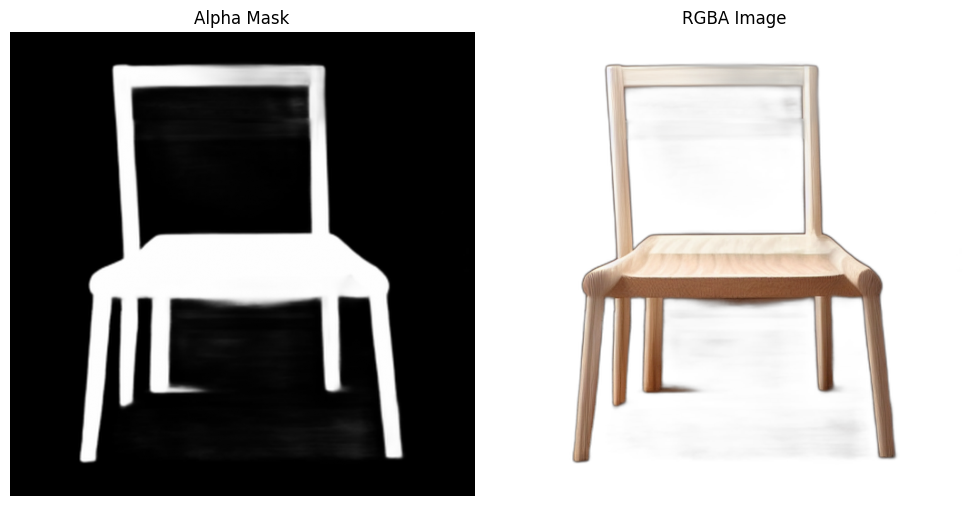

Transparent pixels: 145110
Opaque pixels: 1715
Semi-transparent pixels: 115319


In [72]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

rgba = Image.open(BACKGROUND_REMOVED_PATH).convert("RGBA")
alpha = np.array(rgba)[:, :, 3]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(alpha, cmap="gray")
axes[0].set_title("Alpha Mask")

axes[1].imshow(rgba)
axes[1].set_title("RGBA Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Transparent pixels:", np.sum(alpha == 0))
print("Opaque pixels:", np.sum(alpha == 255))
print("Semi-transparent pixels:", np.sum((alpha > 0) & (alpha < 255)))

Original contact sheet: (640, 960)


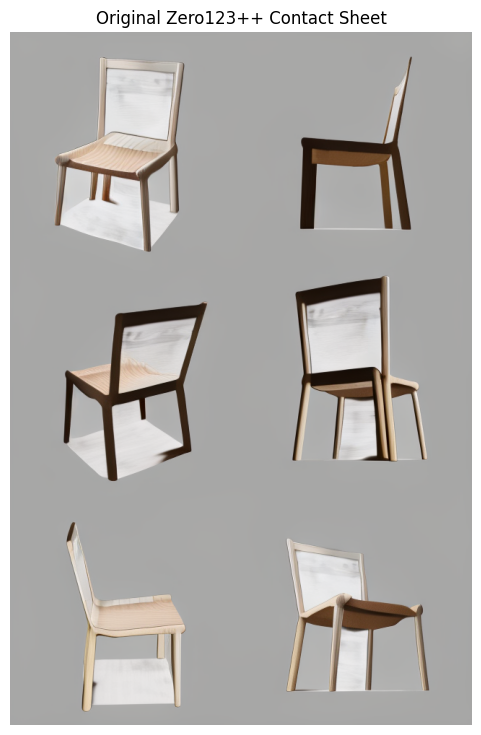

In [73]:
from PIL import Image
import matplotlib.pyplot as plt

original_sheet = Image.open(VIEWS_OUTPUT)

print("Original contact sheet:", original_sheet.size)

plt.figure(figsize=(6, 9))
plt.imshow(original_sheet)
plt.title("Original Zero123++ Contact Sheet")
plt.axis("off")
plt.show()

In [74]:
from PIL import Image, ImageChops

sheet = Image.open(VIEWS_OUTPUT).convert("RGB")

for i in range(6):
    row = i // 2
    col = i % 2

    crop = sheet.crop((
        col * 320,
        row * 320,
        (col + 1) * 320,
        (row + 1) * 320
    ))

    difference = ImageChops.difference(crop, views[i])
    print(f"View {i+1} matches original crop:", difference.getbbox() is None)

View 1 matches original crop: True
View 2 matches original crop: True
View 3 matches original crop: True
View 4 matches original crop: True
View 5 matches original crop: True
View 6 matches original crop: True


In [75]:
camera_numpy = camera_params[0].detach().cpu().numpy()

for i, camera in enumerate(camera_numpy):
    print(f"\nCamera {i+1}")
    print("Extrinsics:", camera[:12].round(3))
    print("Intrinsics:", camera[12:].round(3))


Camera 1
Extrinsics: [-0.5   -0.296  0.814  3.256  0.866 -0.171  0.47   1.879  0.     0.939
  0.342  1.368]
Intrinsics: [1.866 1.866 0.5   0.5  ]

Camera 2
Extrinsics: [-1.     0.     0.     0.     0.     0.174  0.985  3.939  0.     0.985
 -0.174 -0.695]
Intrinsics: [1.866 1.866 0.5   0.5  ]

Camera 3
Extrinsics: [-0.5    0.296 -0.814 -3.256 -0.866 -0.171  0.47   1.879  0.     0.939
  0.342  1.368]
Intrinsics: [1.866 1.866 0.5   0.5  ]

Camera 4
Extrinsics: [ 0.5   -0.15  -0.853 -3.412 -0.866 -0.087 -0.492 -1.97   0.     0.985
 -0.174 -0.695]
Intrinsics: [1.866 1.866 0.5   0.5  ]

Camera 5
Extrinsics: [ 1.     0.    -0.    -0.    -0.     0.342 -0.939 -3.758  0.     0.939
  0.342  1.368]
Intrinsics: [1.866 1.866 0.5   0.5  ]

Camera 6
Extrinsics: [ 0.5    0.15   0.853  3.412  0.866 -0.087 -0.492 -1.97  -0.     0.985
 -0.174 -0.695]
Intrinsics: [1.866 1.866 0.5   0.5  ]


In [76]:
import inspect

print(inspect.getsource(camera_util.spherical_camera_pose))

def spherical_camera_pose(azimuths: np.ndarray, elevations: np.ndarray, radius=2.5):
    azimuths = np.deg2rad(azimuths)
    elevations = np.deg2rad(elevations)

    xs = radius * np.cos(elevations) * np.cos(azimuths)
    ys = radius * np.cos(elevations) * np.sin(azimuths)
    zs = radius * np.sin(elevations)

    cam_locations = np.stack([xs, ys, zs], axis=-1)
    cam_locations = torch.from_numpy(cam_locations).float()

    c2ws = center_looking_at_camera_pose(cam_locations)
    return c2ws



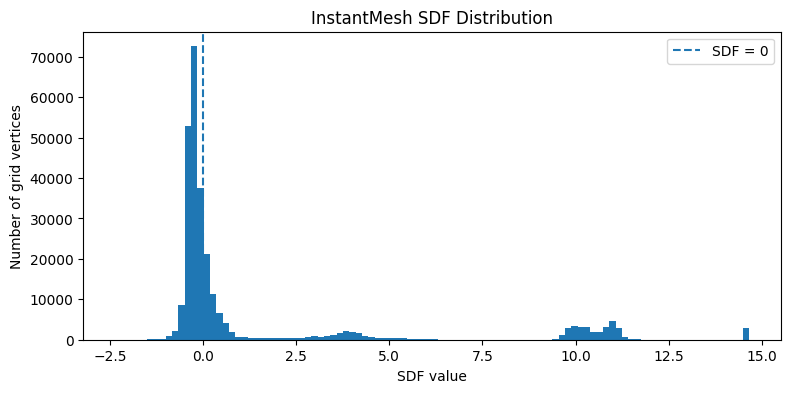

Negative values: 173071
Positive values: 101554
Near-zero values: 16719


In [77]:
import matplotlib.pyplot as plt

sdf_np = sdf.detach().float().cpu().numpy().flatten()

plt.figure(figsize=(9, 4))
plt.hist(sdf_np, bins=100)
plt.axvline(0, linestyle="--", label="SDF = 0")
plt.title("InstantMesh SDF Distribution")
plt.xlabel("SDF value")
plt.ylabel("Number of grid vertices")
plt.legend()
plt.show()

print("Negative values:", (sdf_np < 0).sum())
print("Positive values:", (sdf_np > 0).sum())
print("Near-zero values:", (abs(sdf_np) < 0.05).sum())

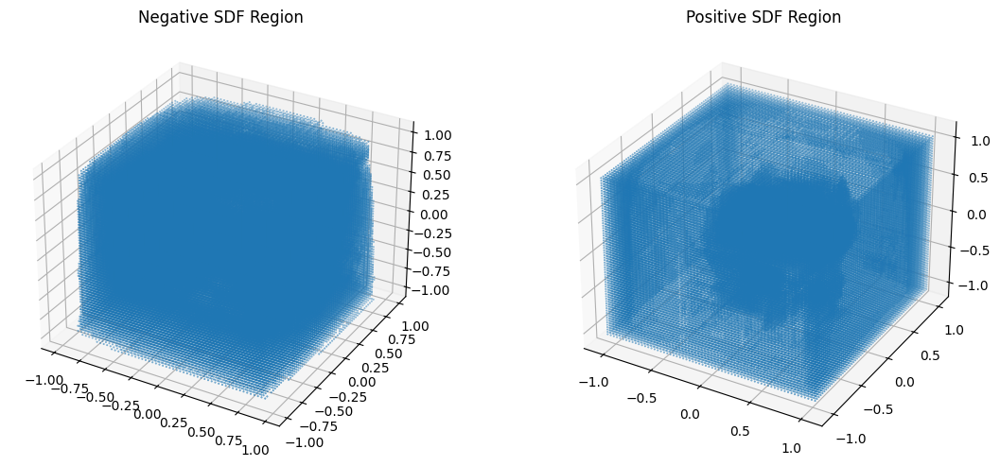

In [78]:
import matplotlib.pyplot as plt

grid_vertices = model.geometry.verts.detach().cpu().numpy()
sdf_values = sdf[0].detach().float().cpu().numpy().reshape(-1)

fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(121, projection="3d")
negative = sdf_values < 0

ax1.scatter(
    grid_vertices[negative, 0],
    grid_vertices[negative, 1],
    grid_vertices[negative, 2],
    s=0.2
)
ax1.set_title("Negative SDF Region")

ax2 = fig.add_subplot(122, projection="3d")
positive = sdf_values > 0

ax2.scatter(
    grid_vertices[positive, 0],
    grid_vertices[positive, 1],
    grid_vertices[positive, 2],
    s=0.2
)
ax2.set_title("Positive SDF Region")

plt.tight_layout()
plt.show()

In [79]:
import inspect

print(inspect.getsource(model.get_sdf_deformation_prediction))

    def get_sdf_deformation_prediction(self, planes):
        '''
        Predict SDF and deformation for tetrahedron vertices
        :param planes: triplane feature map for the geometry
        '''
        init_position = self.geometry.verts.unsqueeze(0).expand(planes.shape[0], -1, -1)
        
        # Step 1: predict the SDF and deformation
        sdf, deformation, weight = torch.utils.checkpoint.checkpoint(
            self.synthesizer.get_geometry_prediction,
            planes, 
            init_position, 
            self.geometry.indices,
            use_reentrant=False,
        )

        # Step 2: Normalize the deformation to avoid the flipped triangles.
        deformation = 1.0 / (self.grid_res * self.deformation_multiplier) * torch.tanh(deformation)
        sdf_reg_loss = torch.zeros(sdf.shape[0], device=sdf.device, dtype=torch.float32)

        ####
        # Step 3: Fix some sdf if we observe empty shape (full positive or full negative)
        sdf_bxnxnxn = sdf.resha

In [80]:
sdf_flat = sdf[0].detach().float()

boundary_idx = model.geometry.boundary_indices
center_idx = model.geometry.center_indices

print("Boundary SDF:")
print("Min:", sdf_flat[boundary_idx].min().item())
print("Max:", sdf_flat[boundary_idx].max().item())
print("Mean:", sdf_flat[boundary_idx].mean().item())

print("\nCenter SDF:")
print("Min:", sdf_flat[center_idx].min().item())
print("Max:", sdf_flat[center_idx].max().item())
print("Mean:", sdf_flat[center_idx].mean().item())

print("\nNegative boundary values:",
      (sdf_flat[boundary_idx] < 0).sum().item())

print("Positive boundary values:",
      (sdf_flat[boundary_idx] > 0).sum().item())

Boundary SDF:
Min: 1.5420398712158203
Max: 14.655454635620117
Mean: 8.638958930969238

Center SDF:
Min: 0.4920692443847656
Max: 0.4920692443847656
Mean: 0.4920692443847656

Negative boundary values: 0
Positive boundary values: 47644


In [81]:
print("Synthesizer geometry prediction signature:")

import inspect

print(inspect.signature(model.synthesizer.get_geometry_prediction))
print(inspect.getsource(model.synthesizer.get_geometry_prediction))

Synthesizer geometry prediction signature:
(planes, sample_coordinates, flexicubes_indices)
    def get_geometry_prediction(self, planes, sample_coordinates, flexicubes_indices):
        plane_axes = self.plane_axes.to(planes.device)
        sampled_features = sample_from_planes(
            plane_axes, planes, sample_coordinates, padding_mode='zeros', box_warp=self.rendering_kwargs['box_warp'])

        sdf, deformation, weight = self.decoder.get_geometry_prediction(sampled_features, flexicubes_indices)
        return sdf, deformation, weight



In [82]:
import inspect

print(inspect.signature(
    model.synthesizer.decoder.get_geometry_prediction
))

print(inspect.getsource(
    model.synthesizer.decoder.get_geometry_prediction
))

(sampled_features, flexicubes_indices)
    def get_geometry_prediction(self, sampled_features, flexicubes_indices):
        _N, n_planes, _M, _C = sampled_features.shape
        sampled_features = sampled_features.permute(0, 2, 1, 3).reshape(_N, _M, n_planes*_C)

        sdf = self.net_sdf(sampled_features)
        deformation = self.net_deformation(sampled_features)

        grid_features = torch.index_select(input=sampled_features, index=flexicubes_indices.reshape(-1), dim=1)
        grid_features = grid_features.reshape(
            sampled_features.shape[0], flexicubes_indices.shape[0], flexicubes_indices.shape[1] * sampled_features.shape[-1])
        weight = self.net_weight(grid_features) * 0.1

        return sdf, deformation, weight



In [83]:
for name, parameter in model.synthesizer.decoder.named_parameters():
    if name.startswith("net_sdf"):
        print(
            name,
            "shape:", tuple(parameter.shape),
            "mean:", round(parameter.detach().float().mean().item(), 6),
            "std:", round(parameter.detach().float().std().item(), 6)
        )

net_sdf.0.weight shape: (64, 240) mean: 2e-06 std: 0.062459
net_sdf.0.bias shape: (64,) mean: 0.034504 std: 0.171985
net_sdf.2.weight shape: (64, 64) mean: -0.007053 std: 0.146393
net_sdf.2.bias shape: (64,) mean: 0.049466 std: 0.223243
net_sdf.4.weight shape: (64, 64) mean: -0.026161 std: 0.308554
net_sdf.4.bias shape: (64,) mean: 0.09604 std: 0.182788
net_sdf.6.weight shape: (1, 64) mean: -0.938562 std: 2.23701
net_sdf.6.bias shape: (1,) mean: 15.72958 std: nan


/tmp/ipykernel_3778/469782045.py:7: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1858.)
  "std:", round(parameter.detach().float().std().item(), 6)


In [84]:
final_layer = model.synthesizer.decoder.net_sdf[6]

print("Final SDF layer bias:", final_layer.bias.detach().cpu())
print("Bias is finite:", torch.isfinite(final_layer.bias).all().item())

print("Final layer weight finite:",
      torch.isfinite(final_layer.weight).all().item())

print("Checkpoint bias:", clean_state_dict[
    "synthesizer.decoder.net_sdf.6.bias"
][:])

Final SDF layer bias: tensor([15.7296])
Bias is finite: True
Final layer weight finite: True
Checkpoint bias: tensor([15.7296])


In [85]:
model_state = model.state_dict()

matched = 0
mismatched = []

for key, value in clean_state_dict.items():
    if key not in model_state:
        mismatched.append((key, "missing"))
    elif not torch.equal(value.cpu(), model_state[key].cpu()):
        mismatched.append((key, "different"))
    else:
        matched += 1

print("Matched parameters:", matched)
print("Mismatches:", len(mismatched))
print("First mismatches:", mismatched[:10])

Matched parameters: 519
Mismatches: 0
First mismatches: []


In [86]:
from pathlib import Path

run_file = Path(REPO_DIR) / "run.py"

print("run.py exists:", run_file.exists())

if run_file.exists():
    lines = run_file.read_text().splitlines()

    keywords = [
        "process_image",
        "preprocess",
        "get_zero123plus_input_cameras",
        "forward_planes",
        "forward_geometry",
        "get_geometry_prediction",
        "init_flexicubes_geometry",
        "load_state_dict",
    ]

    for keyword in keywords:
        matches = [
            i for i, line in enumerate(lines)
            if keyword in line
        ]

        for i in matches:
            print(f"\n--- {keyword} (line {i+1}) ---")
            start = max(0, i - 5)
            end = min(len(lines), i + 9)
            print("\n".join(
                f"{j+1}: {lines[j]}"
                for j in range(start, end)
            ))

run.py exists: True

--- get_zero123plus_input_cameras (line 18) ---
13: from diffusers import DiffusionPipeline, EulerAncestralDiscreteScheduler
14: 
15: from src.utils.train_util import instantiate_from_config
16: from src.utils.camera_util import (
17:     FOV_to_intrinsics, 
18:     get_zero123plus_input_cameras,
19:     get_circular_camera_poses,
20: )
21: from src.utils.mesh_util import save_obj, save_obj_with_mtl
22: from src.utils.infer_util import remove_background, resize_foreground, save_video
23: 
24: 
25: def get_render_cameras(batch_size=1, M=120, radius=4.0, elevation=20.0, is_flexicubes=False):
26:     """

--- get_zero123plus_input_cameras (line 194) ---
189: 
190: ###############################################################################
191: # Stage 2: Reconstruction.
192: ###############################################################################
193: 
194: input_cameras = get_zero123plus_input_cameras(batch_size=1, radius=4.0*args.scale).to(device)
195: ch

In [87]:
for i in range(185, 220):
    print(f"{i+1}: {lines[i]}")

186: 
187: # delete pipeline to save memory
188: del pipeline
189: 
190: ###############################################################################
191: # Stage 2: Reconstruction.
192: ###############################################################################
193: 
194: input_cameras = get_zero123plus_input_cameras(batch_size=1, radius=4.0*args.scale).to(device)
195: chunk_size = 20 if IS_FLEXICUBES else 1
196: 
197: for idx, sample in enumerate(outputs):
198:     name = sample['name']
199:     print(f'[{idx+1}/{len(outputs)}] Creating {name} ...')
200: 
201:     images = sample['images'].unsqueeze(0).to(device)
202:     images = v2.functional.resize(images, 320, interpolation=3, antialias=True).clamp(0, 1)
203: 
204:     if args.view == 4:
205:         indices = torch.tensor([0, 2, 4, 5]).long().to(device)
206:         images = images[:, indices]
207:         input_cameras = input_cameras[:, indices]
208: 
209:     with torch.no_grad():
210:         # get triplane
211:      

In [88]:
import torchvision.transforms as T
import torch

transform = T.ToTensor()

input_views = torch.stack([
    transform(view.resize((320, 320)))
    for view in views
]).unsqueeze(0).to(device="cuda", dtype=torch.float16)

print("Shape:", input_views.shape)
print("Minimum:", input_views.min().item())
print("Maximum:", input_views.max().item())
print("Dtype:", input_views.dtype)

Shape: torch.Size([1, 6, 3, 320, 320])
Minimum: 0.0
Maximum: 1.0
Dtype: torch.float16


In [89]:
with torch.inference_mode():
    planes = model.forward_planes(input_views, camera_params)

print("Triplane shape:", planes.shape)
print("Dtype:", planes.dtype)
print("Finite values:", torch.isfinite(planes).all().item())
print("Min:", planes.min().item())
print("Max:", planes.max().item())

Triplane shape: torch.Size([1, 3, 80, 64, 64])
Dtype: torch.float32
Finite values: True
Min: -7.131762504577637
Max: 7.644623279571533


In [91]:
camera = model.geometry.renderer.camera

print("Camera type:", type(camera))
print("Camera attributes:")
print([
    attr for attr in dir(camera)
    if not attr.startswith("_")
])

Camera type: <class 'src.models.geometry.camera.perspective_camera.PerspectiveCamera'>
Camera attributes:
['T_destination', 'add_module', 'apply', 'bfloat16', 'buffers', 'call_super_init', 'children', 'compile', 'cpu', 'cuda', 'device', 'double', 'dump_patches', 'eval', 'extra_repr', 'float', 'forward', 'get_buffer', 'get_extra_state', 'get_parameter', 'get_submodule', 'half', 'ipu', 'load_state_dict', 'modules', 'mtia', 'named_buffers', 'named_children', 'named_modules', 'named_parameters', 'parameters', 'proj_mtx', 'project', 'register_backward_hook', 'register_buffer', 'register_forward_hook', 'register_forward_pre_hook', 'register_full_backward_hook', 'register_full_backward_pre_hook', 'register_load_state_dict_post_hook', 'register_load_state_dict_pre_hook', 'register_module', 'register_parameter', 'register_state_dict_post_hook', 'register_state_dict_pre_hook', 'requires_grad_', 'set_extra_state', 'set_submodule', 'share_memory', 'smart_apply', 'state_dict', 'to', 'to_empty', 'tr

In [92]:
with torch.inference_mode():
    mesh_vertices, mesh_faces, sdf, deformation, v_deformed, reg_loss = (
        model.get_geometry_prediction(planes)
    )

vertices = mesh_vertices[0]
faces = mesh_faces[0]

print("Vertices:", vertices.shape)
print("Faces:", faces.shape)
print("Finite vertices:", torch.isfinite(vertices).all().item())
print("Finite faces:", torch.isfinite(faces).all().item())

Vertices: torch.Size([46940, 3])
Faces: torch.Size([93856, 3])
Finite vertices: True
Finite faces: True


Watertight: True
Volume: 3.89734205397787
Components: 15


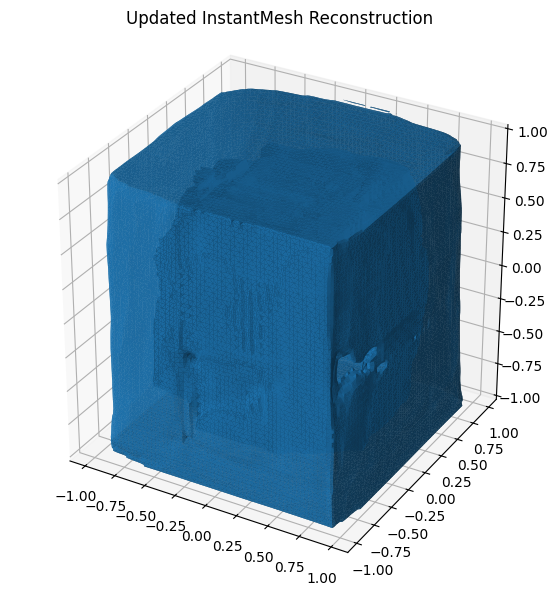

In [93]:
import trimesh
import matplotlib.pyplot as plt

vertices_np = vertices.detach().cpu().numpy()
faces_np = faces.detach().cpu().numpy()

chair_mesh_new = trimesh.Trimesh(
    vertices=vertices_np,
    faces=faces_np,
    process=True
)

print("Watertight:", chair_mesh_new.is_watertight)
print("Volume:", chair_mesh_new.volume)
print("Components:", len(chair_mesh_new.split(only_watertight=False)))

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot_trisurf(
    chair_mesh_new.vertices[:, 0],
    chair_mesh_new.vertices[:, 1],
    chair_mesh_new.vertices[:, 2],
    triangles=chair_mesh_new.faces,
    linewidth=0.05,
    alpha=0.95
)

ax.set_box_aspect([1, 1, 1])
ax.set_title("Updated InstantMesh Reconstruction")
plt.show()

In [94]:
for i in range(6):
    print(f"\nVIEW {i+1}")
    print("Image:", view_paths[i])
    print("Camera matrix:")
    print(camera_params[0, i].detach().cpu().numpy())


VIEW 1
Image: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair_view_1.png
Camera matrix:
[-0.5        -0.29614258  0.81396484  3.2558594   0.86621094 -0.17102051
  0.46972656  1.8789062   0.          0.9394531   0.34204102  1.3681641
  1.8662109   1.8662109   0.5         0.5       ]

VIEW 2
Image: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair_view_2.png
Camera matrix:
[-1.          0.          0.          0.          0.          0.17370605
  0.9848633   3.9394531   0.          0.9848633  -0.17370605 -0.6948242
  1.8662109   1.8662109   0.5         0.5       ]

VIEW 3
Image: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair_view_3.png
Camera matrix:
[-0.5         0.29614258 -0.81396484 -3.2558594  -0.86621094 -0.17102051
  0.46972656  1.8789062   0.          0.9394531   0.34204102  1.3681641
  1.8662109   1.8662109   0.5         0.5       ]

VIEW 4
Image: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair_view_4.pn

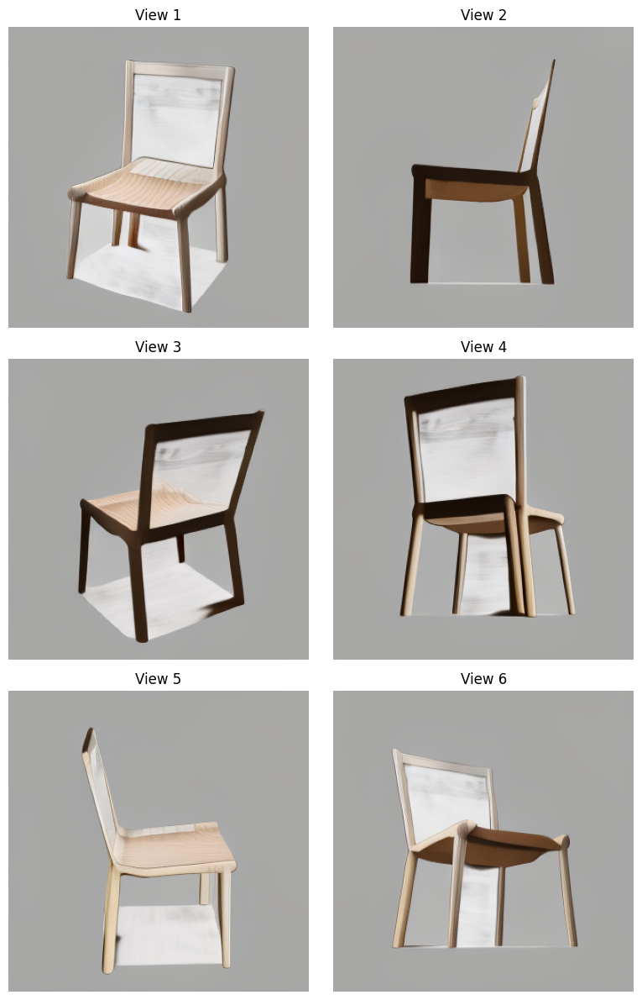

In [95]:
fig, axes = plt.subplots(3, 2, figsize=(8, 12))

for i, ax in enumerate(axes.flat):
    ax.imshow(views[i])
    ax.set_title(f"View {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

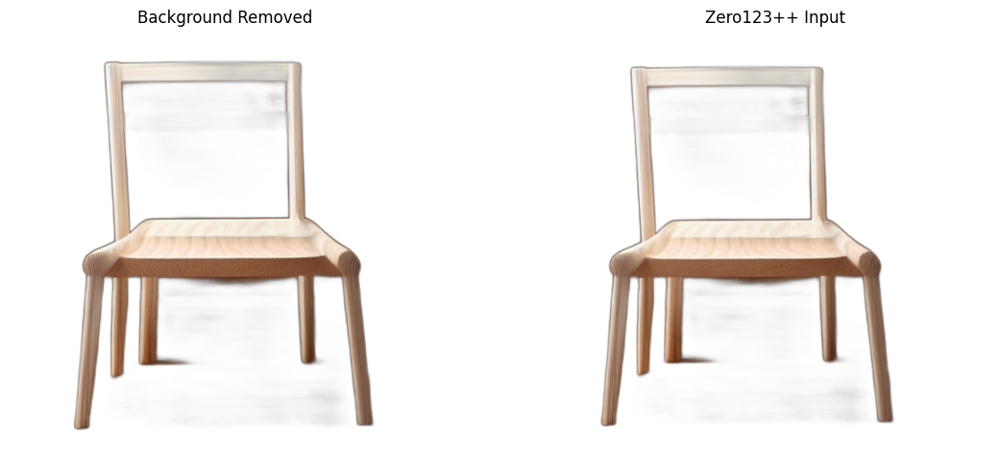

In [96]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(Image.open(BACKGROUND_REMOVED_PATH))
axes[0].set_title("Background Removed")

axes[1].imshow(Image.open(ZERO123_INPUT))
axes[1].set_title("Zero123++ Input")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

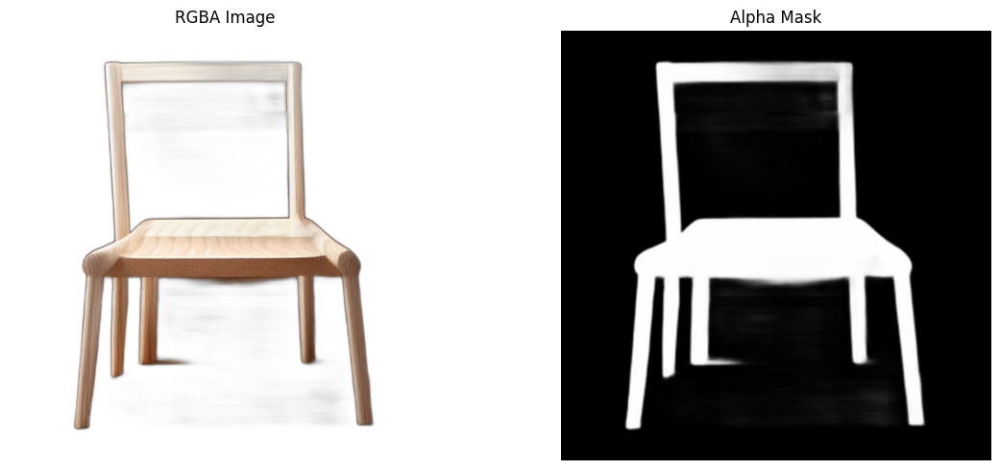

Transparent pixels: 145110
Opaque pixels: 1715
Semi-transparent pixels: 115319


In [97]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

img = Image.open(BACKGROUND_REMOVED_PATH).convert("RGBA")
alpha = np.array(img)[:, :, 3]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(img)
axes[0].set_title("RGBA Image")

axes[1].imshow(alpha, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Alpha Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Transparent pixels:", np.sum(alpha == 0))
print("Opaque pixels:", np.sum(alpha == 255))
print("Semi-transparent pixels:", np.sum((alpha > 0) & (alpha < 255)))

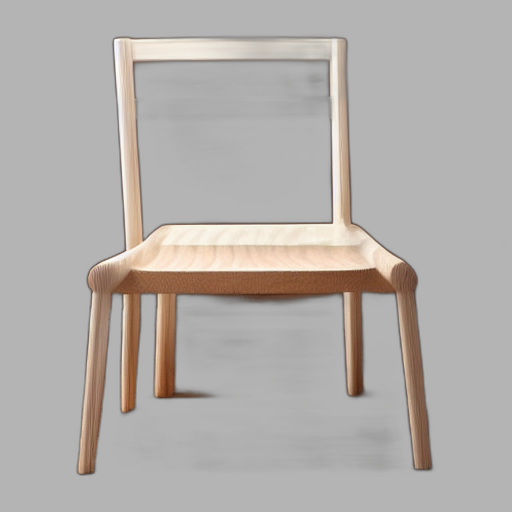

In [98]:
from PIL import Image

chair_rgba = Image.open(BACKGROUND_REMOVED_PATH).convert("RGBA")

background = Image.new(
    "RGBA",
    chair_rgba.size,
    (180, 180, 180, 255)
)

clean_image = Image.alpha_composite(background, chair_rgba)

CLEAN_INPUT = f"{OUTPUT_DIR}/chair_clean_input.png"
clean_image.convert("RGB").save(CLEAN_INPUT)

display(clean_image.convert("RGB"))

In [99]:
from diffusers import DiffusionPipeline, EulerAncestralDiscreteScheduler
import torch

pipeline = DiffusionPipeline.from_pretrained(
    SNAPSHOT_DIR,
    custom_pipeline=f"{REPO_DIR}/zero123plus",
    torch_dtype=torch.float16,
    local_files_only=True,
    trust_remote_code=True
)

pipeline.scheduler = EulerAncestralDiscreteScheduler.from_config(
    pipeline.scheduler.config,
    timestep_spacing="trailing"
)

pipeline = pipeline.to("cuda")

print("Zero123++ loaded successfully!")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/8 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/520 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

Zero123++ loaded successfully!


  0%|          | 0/75 [00:00<?, ?it/s]

Generated image size: (640, 960)


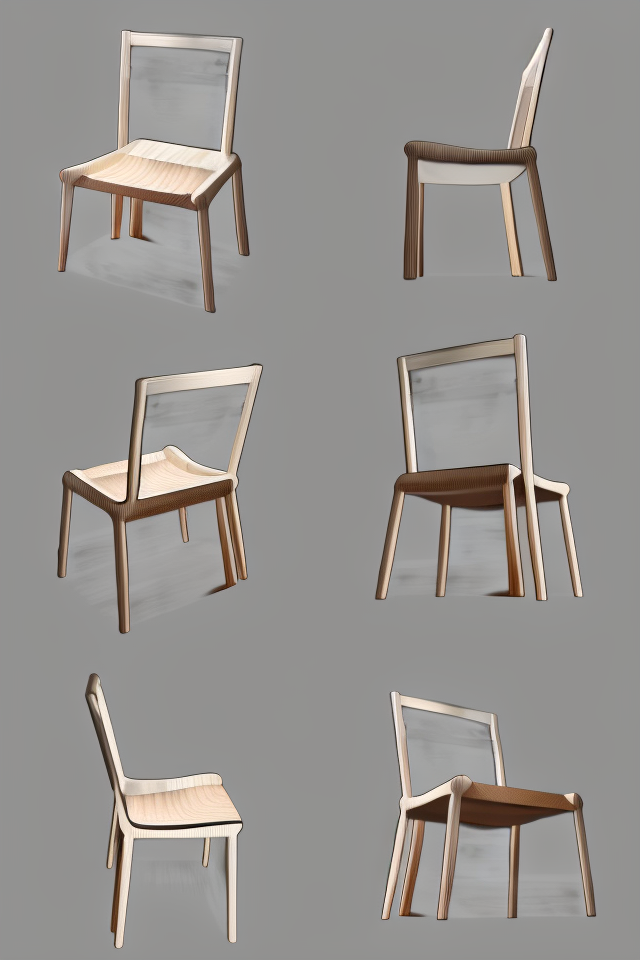

In [100]:
from PIL import Image

input_image = Image.open(CLEAN_INPUT).convert("RGB")

with torch.inference_mode():
    result = pipeline(
        input_image,
        num_inference_steps=75,
        generator=torch.Generator(device="cuda").manual_seed(42)
    )

new_views = result.images[0]

NEW_VIEWS_OUTPUT = f"{VIEWS_DIR}/chair_zero123_views_v2.png"
new_views.save(NEW_VIEWS_OUTPUT)

print("Generated image size:", new_views.size)
display(new_views)

In [101]:
from PIL import Image

width, height = new_views.size
tile_w = width // 2
tile_h = height // 3

new_view_paths = []

for i in range(6):
    row = i // 2
    col = i % 2

    view = new_views.crop((
        col * tile_w,
        row * tile_h,
        (col + 1) * tile_w,
        (row + 1) * tile_h
    ))

    path = f"{VIEWS_DIR}/chair_v2_view_{i+1}.png"
    view.save(path)
    new_view_paths.append(path)

print("Saved views:", len(new_view_paths))

Saved views: 6


In [102]:
import torchvision.transforms as T
from PIL import Image
import torch

transform = T.ToTensor()

new_images = [
    Image.open(path).convert("RGB")
    for path in new_view_paths
]

new_input_views = torch.stack([
    transform(img.resize((320, 320)))
    for img in new_images
]).unsqueeze(0).to(device="cuda", dtype=torch.float16)

print("Input shape:", new_input_views.shape)
print("Pixel range:", new_input_views.min().item(),
      new_input_views.max().item())

with torch.inference_mode():
    new_planes = model.forward_planes(
        new_input_views,
        camera_params
    )

print("New triplanes:", new_planes.shape)
print("Finite:", torch.isfinite(new_planes).all().item())

Input shape: torch.Size([1, 6, 3, 320, 320])
Pixel range: 0.0 1.0
New triplanes: torch.Size([1, 3, 80, 64, 64])
Finite: True


In [103]:
with torch.inference_mode():
    new_vertices, new_faces, new_sdf, new_deformation, new_v_deformed, new_reg_loss = (
        model.get_geometry_prediction(new_planes)
    )

vertices_v2 = new_vertices[0]
faces_v2 = new_faces[0]

print("Vertices:", vertices_v2.shape)
print("Faces:", faces_v2.shape)
print("Finite vertices:", torch.isfinite(vertices_v2).all().item())
print("Finite faces:", torch.isfinite(faces_v2).all().item())

Vertices: torch.Size([38264, 3])
Faces: torch.Size([76440, 3])
Finite vertices: True
Finite faces: True


Watertight: True
Volume: 5.691559355505556
Components: 41
Bounds: [[-0.9844743  -0.98127848 -0.9880318 ]
 [ 0.9854328   0.98123807  0.98811722]]


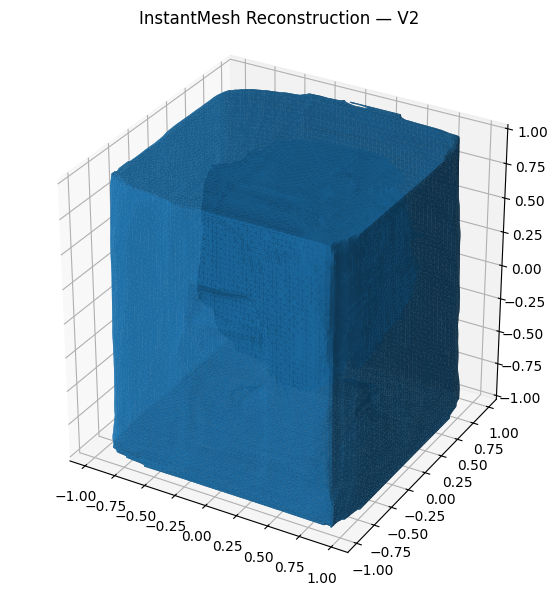

In [104]:
import trimesh
import matplotlib.pyplot as plt

vertices_np = vertices_v2.detach().cpu().numpy()
faces_np = faces_v2.detach().cpu().numpy()

chair_mesh_v2 = trimesh.Trimesh(
    vertices=vertices_np,
    faces=faces_np,
    process=True
)

print("Watertight:", chair_mesh_v2.is_watertight)
print("Volume:", chair_mesh_v2.volume)
print("Components:", len(chair_mesh_v2.split(only_watertight=False)))
print("Bounds:", chair_mesh_v2.bounds)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot_trisurf(
    chair_mesh_v2.vertices[:, 0],
    chair_mesh_v2.vertices[:, 1],
    chair_mesh_v2.vertices[:, 2],
    triangles=chair_mesh_v2.faces,
    linewidth=0.05,
    alpha=0.95
)

ax.set_box_aspect([1, 1, 1])
ax.set_title("InstantMesh Reconstruction — V2")
plt.show()

In [105]:
import inspect

print("========== OFFICIAL RUN.PY ==========")

for i in range(216, min(235, len(lines))):
    print(f"{i+1}: {lines[i]}")

print("\n========== MODEL EXTRACT_MESH ==========")

print(inspect.getsource(model.extract_mesh))

========== OFFICIAL RUN.PY ==========
217:             planes,
218:             use_texture_map=args.export_texmap,
219:             **infer_config,
220:         )
221:         if args.export_texmap:
222:             vertices, faces, uvs, mesh_tex_idx, tex_map = mesh_out
223:             save_obj_with_mtl(
224:                 vertices.data.cpu().numpy(),
225:                 uvs.data.cpu().numpy(),
226:                 faces.data.cpu().numpy(),
227:                 mesh_tex_idx.data.cpu().numpy(),
228:                 tex_map.permute(1, 2, 0).data.cpu().numpy(),
229:                 mesh_path_idx,
230:             )
231:         else:
232:             vertices, faces, vertex_colors = mesh_out
233:             save_obj(vertices, faces, vertex_colors, mesh_path_idx)
234:         print(f"Mesh saved to {mesh_path_idx}")
235: 

========== MODEL EXTRACT_MESH ==========
    def extract_mesh(
        self, 
        planes: torch.Tensor, 
        use_texture_map: bool = False,
        texture_

In [106]:
print("========== OFFICIAL MODEL SETUP ==========")

for i in range(65, 135):
    print(f"{i+1}: {lines[i]}")

print("\n========== INFERENCE CONFIG ==========")
print(infer_config)

print("\n========== MODEL CONFIG ==========")
print(config.model_config)


========== OFFICIAL MODEL SETUP ==========
66: # Arguments.
67: ###############################################################################
68: 
69: parser = argparse.ArgumentParser()
70: parser.add_argument('config', type=str, help='Path to config file.')
71: parser.add_argument('input_path', type=str, help='Path to input image or directory.')
72: parser.add_argument('--output_path', type=str, default='outputs/', help='Output directory.')
73: parser.add_argument('--diffusion_steps', type=int, default=75, help='Denoising Sampling steps.')
74: parser.add_argument('--seed', type=int, default=42, help='Random seed for sampling.')
75: parser.add_argument('--scale', type=float, default=1.0, help='Scale of generated object.')
76: parser.add_argument('--distance', type=float, default=4.5, help='Render distance.')
77: parser.add_argument('--view', type=int, default=6, choices=[4, 6], help='Number of input views.')
78: parser.add_argument('--no_rembg', action='store_true', help='Do not remo

In [108]:
print("Pipeline UNet:", type(pipeline.unet))
print("Inner UNet:", type(pipeline.unet.unet))

checkpoint_keys = set(unet_state.keys())
inner_keys = set(pipeline.unet.unet.state_dict().keys())

print("\nCheckpoint parameters:", len(checkpoint_keys))
print("Inner UNet parameters:", len(inner_keys))

print("Missing from checkpoint:", len(inner_keys - checkpoint_keys))
print("Extra in checkpoint:", len(checkpoint_keys - inner_keys))

print("\nFirst checkpoint keys:", list(unet_state.keys())[:5])
print("First inner UNet keys:", list(pipeline.unet.unet.state_dict().keys())[:5])

Pipeline UNet: <class 'diffusers_modules.local.pipeline.RefOnlyNoisedUNet'>
Inner UNet: <class 'diffusers.models.unets.unet_2d_condition.UNet2DConditionModel'>

Checkpoint parameters: 686
Inner UNet parameters: 686
Missing from checkpoint: 0
Extra in checkpoint: 0

First checkpoint keys: ['conv_in.weight', 'conv_in.bias', 'time_embedding.linear_1.weight', 'time_embedding.linear_1.bias', 'time_embedding.linear_2.weight']
First inner UNet keys: ['conv_in.weight', 'conv_in.bias', 'time_embedding.linear_1.weight', 'time_embedding.linear_1.bias', 'time_embedding.linear_2.weight']


In [109]:
load_result = pipeline.unet.unet.load_state_dict(
    unet_state,
    strict=True
)

print("InstantMesh custom UNet loaded!")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

InstantMesh custom UNet loaded!
Missing keys: []
Unexpected keys: []


  0%|          | 0/75 [00:00<?, ?it/s]

Generated: (640, 960)


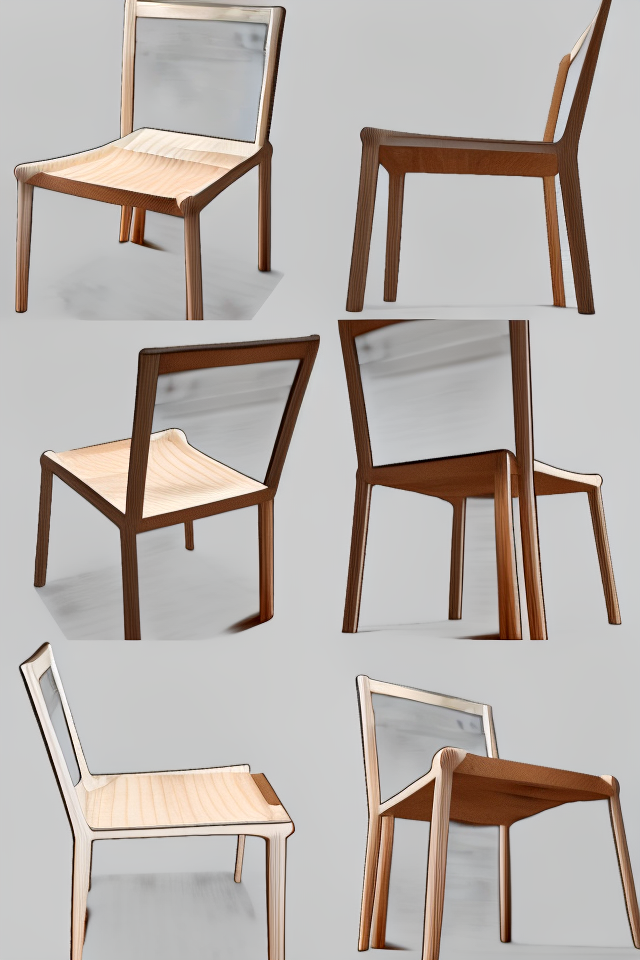

In [110]:
FINAL_VIEWS_RESULT = f"{VIEWS_DIR}/chair_instantmesh_views.png"

input_image = Image.open(CLEAN_INPUT).convert("RGB")

with torch.inference_mode():
    result = pipeline(
        input_image,
        num_inference_steps=75,
        generator=torch.Generator(device="cuda").manual_seed(42)
    )

final_views = result.images[0]
final_views.save(FINAL_VIEWS_RESULT)

print("Generated:", final_views.size)
display(final_views)

In [111]:
from PIL import Image

w, h = final_views.size
tile_w = w // 2
tile_h = h // 3

for i in range(6):
    row = i // 2
    col = i % 2

    view = final_views.crop((
        col * tile_w,
        row * tile_h,
        (col + 1) * tile_w,
        (row + 1) * tile_h
    ))

    view_path = f"{VIEWS_DIR}/chair_final_view_{i+1}.png"
    view.save(view_path)

    print(f"Saved: {view_path}")

Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair_final_view_1.png
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair_final_view_2.png
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair_final_view_3.png
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair_final_view_4.png
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair_final_view_5.png
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair_final_view_6.png


In [112]:
from torchvision.transforms import ToTensor
from src.utils import camera_util
import torch

view_paths = [
    f"{VIEWS_DIR}/chair_final_view_{i}.png"
    for i in range(1, 7)
]

views = [
    Image.open(path).convert("RGB")
    for path in view_paths
]

transform = ToTensor()

input_views = torch.stack([
    transform(view) for view in views
]).unsqueeze(0).to(device="cuda", dtype=torch.float16)

camera_params = camera_util.get_zero123plus_input_cameras(
    batch_size=1,
    radius=4.0,
    fov=30.0
).to(device="cuda", dtype=torch.float32)

print("Input views:", input_views.shape)
print("Camera parameters:", camera_params.shape)

with torch.inference_mode():
    planes = model.forward_planes(input_views, camera_params)

print("Triplane generated:", planes.shape)

Input views: torch.Size([1, 6, 3, 320, 320])
Camera parameters: torch.Size([1, 6, 16])
Triplane generated: torch.Size([1, 3, 80, 64, 64])


In [114]:
print("Vertices type:", type(mesh_vertices))
print("Faces type:", type(mesh_faces))

print("Vertices count:", len(mesh_vertices))
print("Faces count:", len(mesh_faces))

print("First vertices shape:", mesh_vertices[0].shape)
print("First faces shape:", mesh_faces[0].shape)

print("SDF type:", type(sdf))
print("Deformation type:", type(deformation))

Vertices type: <class 'list'>
Faces type: <class 'list'>
Vertices count: 1
Faces count: 1
First vertices shape: torch.Size([38352, 3])
First faces shape: torch.Size([76796, 3])
SDF type: <class 'torch.Tensor'>
Deformation type: <class 'torch.Tensor'>


In [117]:
import trimesh
import numpy as np

vertices = mesh_vertices[0].detach().cpu().numpy()
faces = mesh_faces[0].detach().cpu().numpy()

chair_mesh = trimesh.Trimesh(
    vertices=vertices,
    faces=faces,
    process=True
)

print("Mesh validation")
print("----------------")
print("Vertices:", len(chair_mesh.vertices))
print("Faces:", len(chair_mesh.faces))
print("Watertight:", chair_mesh.is_watertight)
print("Valid:", chair_mesh.process(validate=True).is_winding_consistent)
print("Volume:", chair_mesh.volume)
print("Components:", len(chair_mesh.split(only_watertight=False)))
print("Bounds:\n", chair_mesh.bounds)

Mesh validation
----------------
Vertices: 38352
Faces: 76796
Watertight: True
Valid: True
Volume: 1.3031029959891633
Components: 22
Bounds:
 [[-0.962565   -0.98748773 -0.99122232]
 [ 0.95700437  0.98823529  0.98994678]]


In [118]:
import plotly.graph_objects as go

fig = go.Figure(data=[
    go.Mesh3d(
        x=vertices[:, 0],
        y=vertices[:, 1],
        z=vertices[:, 2],
        i=faces[:, 0],
        j=faces[:, 1],
        k=faces[:, 2],
        color="lightblue",
        opacity=1.0
    )
])

fig.update_layout(
    title="Sketch2Shape AI - Reconstructed 3D Chair",
    scene=dict(
        aspectmode="data",
        xaxis_title="X",
        yaxis_title="Y",
        zaxis_title="Z"
    ),
    width=850,
    height=700
)

fig.show()

In [119]:
print("Vertices finite:", np.isfinite(vertices).all())
print("Faces valid:", faces.min() >= 0 and faces.max() < len(vertices))

print("Vertex range:")
print("X:", vertices[:, 0].min(), vertices[:, 0].max())
print("Y:", vertices[:, 1].min(), vertices[:, 1].max())
print("Z:", vertices[:, 2].min(), vertices[:, 2].max())

print("First 5 vertices:\n", vertices[:5])


Vertices finite: True
Faces valid: True
Vertex range:
X: -0.962565 0.95700437
Y: -0.98748773 0.9882353
Z: -0.9912223 0.9899468
First 5 vertices:
 [[-0.954963   -0.8840304  -0.9296944 ]
 [-0.95723885 -0.88525426 -0.9054723 ]
 [-0.95615    -0.8845095  -0.871961  ]
 [-0.9540281  -0.8831656  -0.8384649 ]
 [-0.95329976 -0.882801   -0.8129911 ]]


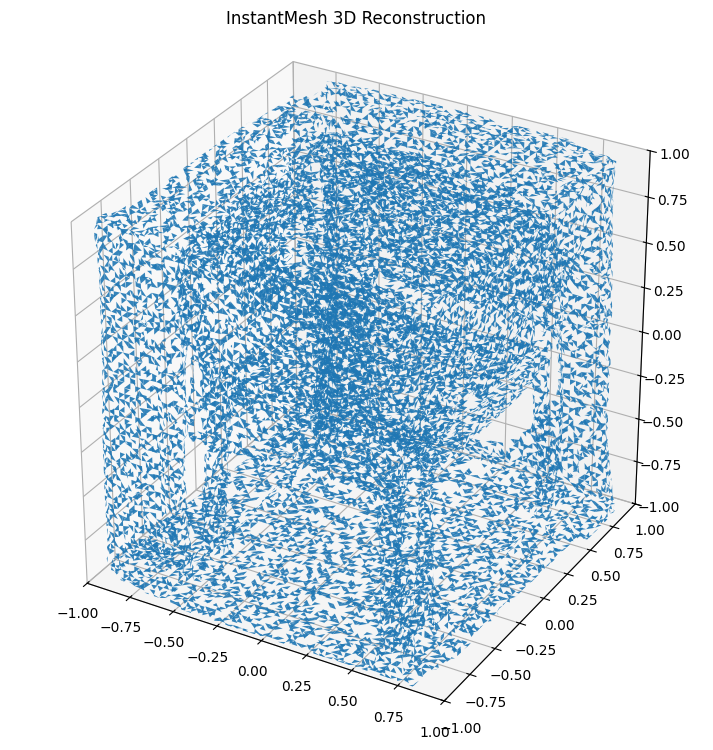

In [120]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(111, projection="3d")

sample_faces = faces[::5]
mesh_triangles = vertices[sample_faces]

collection = Poly3DCollection(
    mesh_triangles,
    alpha=0.9,
    edgecolor="none"
)

ax.add_collection3d(collection)

ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)
ax.set_zlim(-1, 1)

ax.set_box_aspect([1, 1, 1])
ax.set_title("InstantMesh 3D Reconstruction")

plt.show()

Base directory: /content/drive/MyDrive/Sketch2Shape_AI
Input image: /content/drive/MyDrive/Sketch2Shape_AI/examples/img 2.jpg
Image size: (1400, 1400)


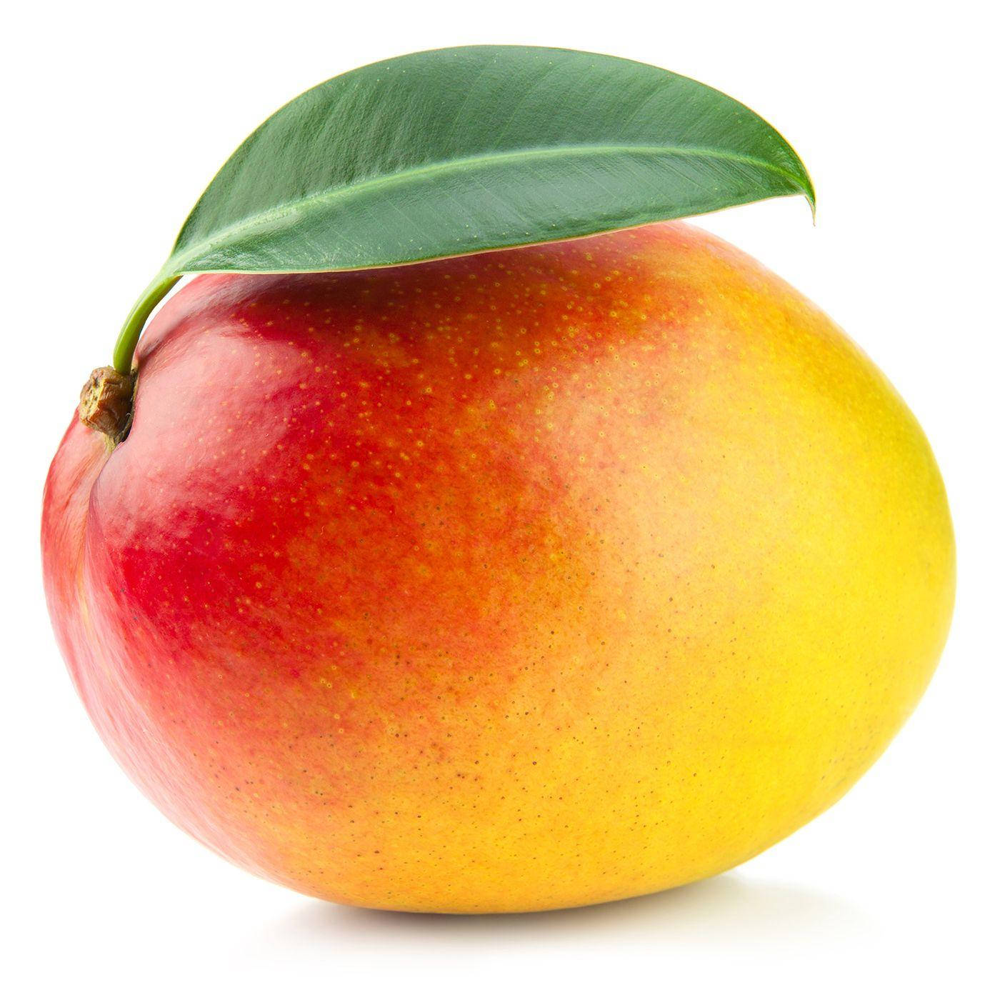

In [125]:
from PIL import Image

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"

MANGO_INPUT = f"{BASE_DIR}/examples/img 2.jpg"

mango_image = Image.open(MANGO_INPUT).convert("RGB")

print("Base directory:", BASE_DIR)
print("Input image:", MANGO_INPUT)
print("Image size:", mango_image.size)

display(mango_image)

Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/mango_scribble.png


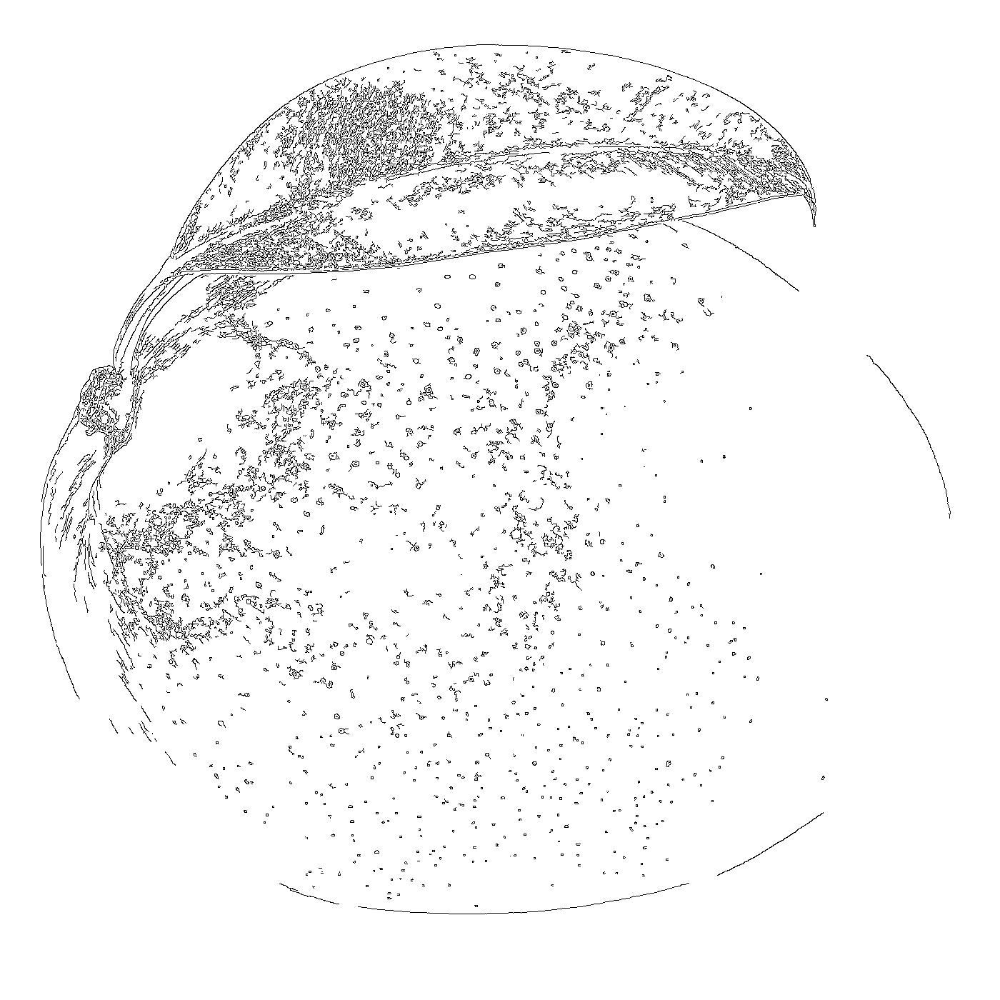

In [126]:
import cv2
import numpy as np
from PIL import Image

# Convert mango image to grayscale
image_np = np.array(mango_image)
gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

# Detect object edges
edges = cv2.Canny(gray, 60, 150)

# White background, black edges
scribble = 255 - edges

# Convert to PIL
mango_scribble = Image.fromarray(scribble).convert("RGB")

# Save
MANGO_SCRIBBLE_PATH = f"{BASE_DIR}/outputs/mango_scribble.png"
mango_scribble.save(MANGO_SCRIBBLE_PATH)

print("Saved:", MANGO_SCRIBBLE_PATH)
display(mango_scribble)

Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/mango_scribble_clean.png


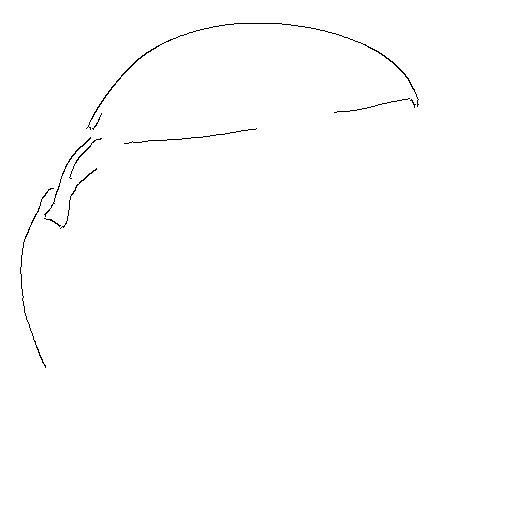

In [127]:
import cv2
import numpy as np
from PIL import Image

image_np = np.array(mango_image.resize((512, 512)))

gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

# Suppress texture and small details
blurred = cv2.GaussianBlur(gray, (9, 9), 2.5)

# Detect major edges
edges = cv2.Canny(blurred, 70, 150)

# White background, black edges
clean_scribble = 255 - edges

mango_scribble_clean = Image.fromarray(clean_scribble).convert("RGB")

MANGO_SCRIBBLE_PATH = f"{BASE_DIR}/outputs/mango_scribble_clean.png"
mango_scribble_clean.save(MANGO_SCRIBBLE_PATH)

print("Saved:", MANGO_SCRIBBLE_PATH)
display(mango_scribble_clean)

Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/mango_scribble_final.png


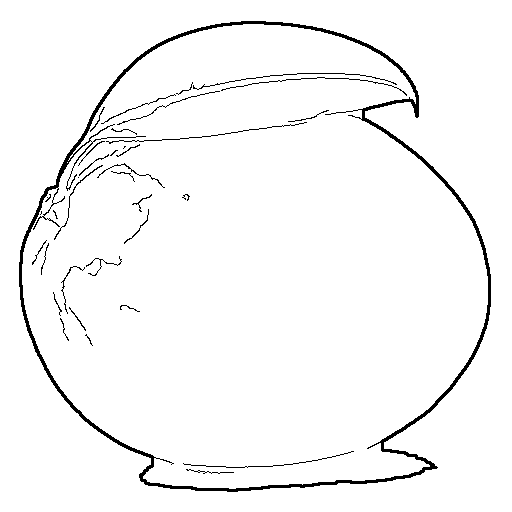

In [128]:
import cv2
import numpy as np
from PIL import Image

image_np = np.array(mango_image.resize((512, 512)))

# Separate the object from the nearly white background
gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)
mask = cv2.threshold(gray, 248, 255, cv2.THRESH_BINARY_INV)[1]

# Clean small gaps and noise
kernel = np.ones((5, 5), np.uint8)
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)

# Find the largest object contour
contours, _ = cv2.findContours(
    mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

largest = max(contours, key=cv2.contourArea)

# Draw the main silhouette
sketch = np.ones((512, 512), dtype=np.uint8) * 255
cv2.drawContours(sketch, [largest], -1, 0, 2)

# Add selected internal details from the leaf and stem
blurred = cv2.GaussianBlur(gray, (7, 7), 1.5)
edges = cv2.Canny(blurred, 45, 100)

# Keep internal details inside the object
inner_edges = cv2.bitwise_and(edges, mask)
sketch[inner_edges > 0] = 0

MANGO_SCRIBBLE_PATH = f"{BASE_DIR}/outputs/mango_scribble_final.png"

Image.fromarray(sketch).convert("RGB").save(MANGO_SCRIBBLE_PATH)

print("Saved:", MANGO_SCRIBBLE_PATH)
display(Image.open(MANGO_SCRIBBLE_PATH))

Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/mango_scribble_final.png


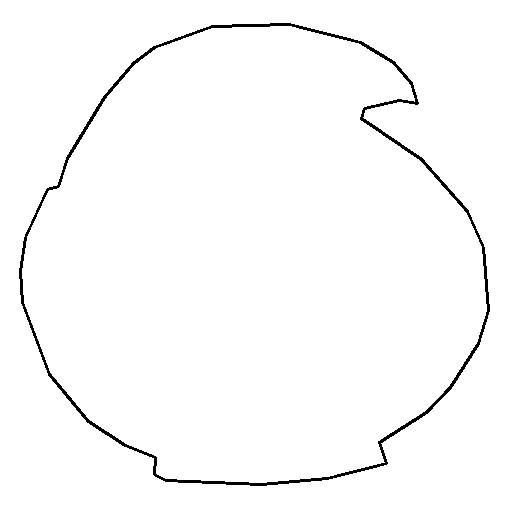

In [129]:
import cv2
import numpy as np
from PIL import Image

image_np = np.array(mango_image.resize((512, 512)))
gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

# Exclude faint shadows
mask = cv2.threshold(gray, 235, 255, cv2.THRESH_BINARY_INV)[1]

# Clean the silhouette
kernel = np.ones((5, 5), np.uint8)
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

contours, _ = cv2.findContours(
    mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

largest = max(contours, key=cv2.contourArea)

# Smooth the outer contour
epsilon = 0.002 * cv2.arcLength(largest, True)
smooth_contour = cv2.approxPolyDP(largest, epsilon, True)

sketch = np.full((512, 512), 255, dtype=np.uint8)
cv2.drawContours(sketch, [smooth_contour], -1, 0, 2)

# Save
MANGO_SCRIBBLE_PATH = f"{BASE_DIR}/outputs/mango_scribble_final.png"

Image.fromarray(sketch).convert("RGB").save(MANGO_SCRIBBLE_PATH)

print("Saved:", MANGO_SCRIBBLE_PATH)
display(Image.open(MANGO_SCRIBBLE_PATH))

In [130]:
from PIL import Image

control_image = Image.open(
    f"{BASE_DIR}/outputs/mango_scribble_final.png"
).convert("RGB")

controlnet_image = controlnet_pipeline(
    prompt=(
        "A photorealistic ripe Alphonso mango, "
        "natural red and golden yellow gradient, "
        "green leaf attached to the stem, "
        "single whole mango, realistic organic shape, "
        "studio product photography, neutral light background"
    ),
    negative_prompt=(
        "multiple fruits, sliced fruit, distorted shape, "
        "extra leaves, text, watermark, cartoon"
    ),
    image=control_image,
    num_inference_steps=30,
    guidance_scale=7.5,
    controlnet_conditioning_scale=0.8,
    generator=torch.Generator(device="cuda").manual_seed(42)
).images[0]

MANGO_GENERATED_PATH = f"{BASE_DIR}/outputs/mango_controlnet_generated.png"
controlnet_image.save(MANGO_GENERATED_PATH)

print("Generated:", MANGO_GENERATED_PATH)
display(controlnet_image)

NameError: name 'controlnet_pipeline' is not defined

In [131]:
print("ControlNet pipeline exists:", "controlnet_pipeline" in globals())
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Free VRAM:", round(
        torch.cuda.mem_get_info()[0] / 1024**3, 2
    ), "GB")

ControlNet pipeline exists: False
CUDA available: True
GPU: Tesla T4
Free VRAM: 3.94 GB


In [1]:
import gc
import torch

# Release InstantMesh and reconstruction intermediates
for name in [
    "model",
    "planes",
    "input_views",
    "camera_params",
    "sdf",
    "deformation",
    "mesh_vertices",
    "mesh_faces"
]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

free_vram, total_vram = torch.cuda.mem_get_info()

print("GPU:", torch.cuda.get_device_name(0))
print("Total VRAM:", round(total_vram / 1024**3, 2), "GB")
print("Free VRAM:", round(free_vram / 1024**3, 2), "GB")

GPU: Tesla T4
Total VRAM: 14.56 GB
Free VRAM: 8.73 GB


In [2]:
import torch
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler

CONTROLNET_MODEL = "lllyasviel/sd-controlnet-scribble"
SD_MODEL = "runwayml/stable-diffusion-v1-5"

controlnet = ControlNetModel.from_pretrained(
    CONTROLNET_MODEL,
    torch_dtype=torch.float16
)

controlnet_pipeline = StableDiffusionControlNetPipeline.from_pretrained(
    SD_MODEL,
    controlnet=controlnet,
    torch_dtype=torch.float16,
    safety_checker=None
)

controlnet_pipeline.scheduler = UniPCMultistepScheduler.from_config(
    controlnet_pipeline.scheduler.config
)

controlnet_pipeline.enable_attention_slicing()
controlnet_pipeline = controlnet_pipeline.to("cuda")

print("Scribble ControlNet loaded successfully!")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

... (2 outputs left out)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Scribble ControlNet loaded successfully!


In [6]:
import os
import sys

REPO_DIR = "/content/InstantMesh"

if not os.path.exists(REPO_DIR):
    !git clone https://github.com/TencentARC/InstantMesh.git {REPO_DIR}

os.chdir(REPO_DIR)

if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

print("Working directory:", os.getcwd())
print("Source directory exists:", os.path.exists(f"{REPO_DIR}/src"))

from src.utils.infer_util import resize_foreground

print("InstantMesh utilities imported successfully!")

Working directory: /content/InstantMesh
Source directory exists: True
InstantMesh utilities imported successfully!


Original image: (1400, 1400)
Processed image: (1538, 1538)
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/mango_processed.png


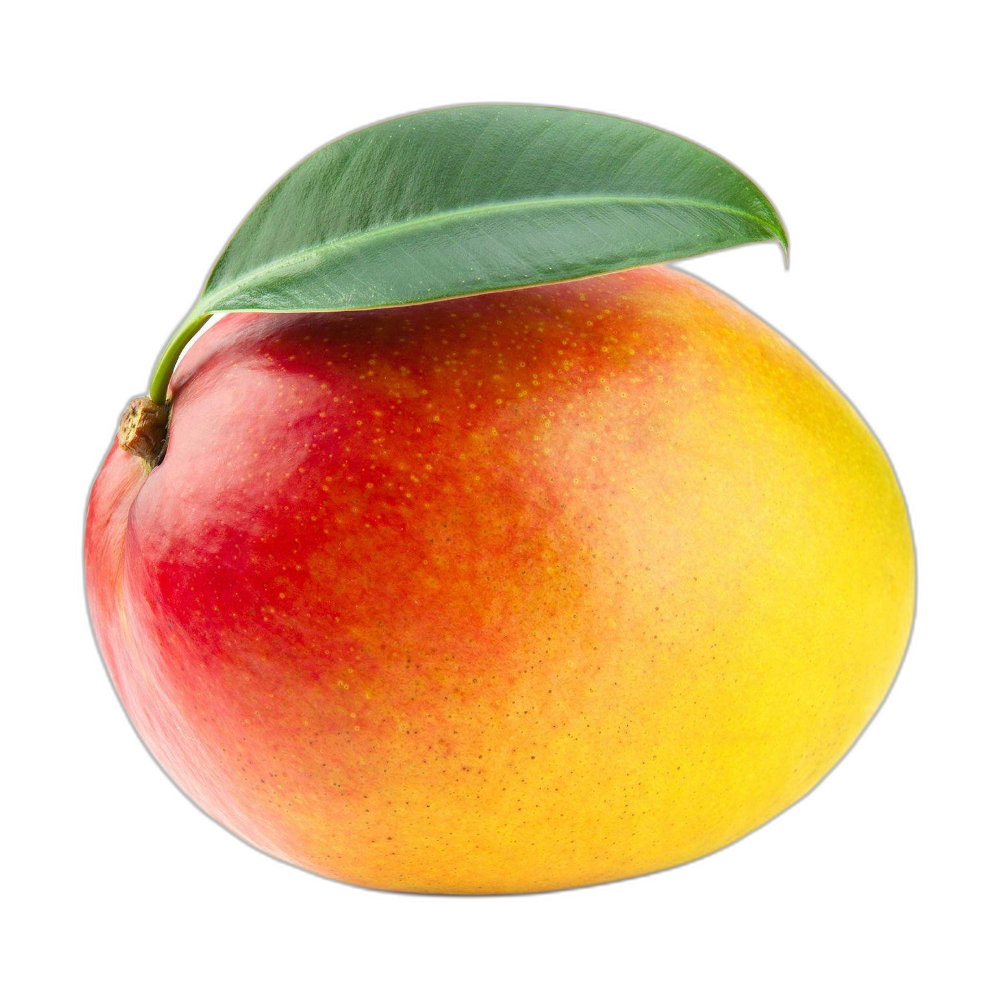

In [7]:
import os
import gc
import torch
import rembg

from PIL import Image
from src.utils.infer_util import resize_foreground

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"
OUTPUT_DIR = f"{BASE_DIR}/outputs"

MANGO_INPUT = f"{BASE_DIR}/examples/img 2.jpg"
MANGO_PROCESSED = f"{OUTPUT_DIR}/mango_processed.png"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load original photograph
image = Image.open(MANGO_INPUT).convert("RGB")

# Background removal
session = rembg.new_session(
    "u2net",
    providers=["CPUExecutionProvider"]
)

result = rembg.remove(
    image,
    session=session
).convert("RGBA")

# Prepare foreground for Zero123++
processed_image = resize_foreground(result, 0.85)

# Save processed image
processed_image.save(MANGO_PROCESSED)

print("Original image:", image.size)
print("Processed image:", processed_image.size)
print("Saved:", MANGO_PROCESSED)

display(processed_image)

In [8]:
import torch

print("Zero123++ pipeline loaded:", "pipeline" in globals())
print("Custom ControlNet loaded:", "controlnet_pipeline" in globals())
print("Processed mango:", processed_image.size)

free, total = torch.cuda.mem_get_info()

print("Free VRAM:", round(free / 1024**3, 2), "GB")
print("Total VRAM:", round(total / 1024**3, 2), "GB")

Zero123++ pipeline loaded: False
Custom ControlNet loaded: True
Processed mango: (1538, 1538)
Free VRAM: 5.08 GB
Total VRAM: 14.56 GB


In [9]:
import gc
import torch

del controlnet_pipeline
del controlnet

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

free, total = torch.cuda.mem_get_info()

print("Free VRAM:", round(free / 1024**3, 2), "GB")
print("Total VRAM:", round(total / 1024**3, 2), "GB")
print("Processed mango retained:", processed_image.size)

Free VRAM: 8.67 GB
Total VRAM: 14.56 GB
Processed mango retained: (1538, 1538)


In [11]:
print("UNet type:", type(pipeline.unet))
print("UNet class:", pipeline.unet.__class__.__name__)

print("\nCheckpoint keys:")
state_dict = torch.load(
    UNET_CKPT,
    map_location="cpu",
    weights_only=True
)

print("First 5 checkpoint keys:")
print(list(state_dict.keys())[:5])

print("\nFirst 5 model keys:")
print(list(pipeline.unet.state_dict().keys())[:5])

print("\nCheckpoint parameters:", len(state_dict))
print("Model parameters:", len(pipeline.unet.state_dict()))

UNet type: <class 'diffusers.models.unets.unet_2d_condition.UNet2DConditionModel'>
UNet class: UNet2DConditionModel

Checkpoint keys:
First 5 checkpoint keys:
['conv_in.weight', 'conv_in.bias', 'time_embedding.linear_1.weight', 'time_embedding.linear_1.bias', 'time_embedding.linear_2.weight']

First 5 model keys:
['conv_in.weight', 'conv_in.bias', 'time_embedding.linear_1.weight', 'time_embedding.linear_1.bias', 'time_embedding.linear_2.weight']

Checkpoint parameters: 686
Model parameters: 686


In [12]:
load_result = pipeline.unet.load_state_dict(
    state_dict,
    strict=True
)

print("InstantMesh custom UNet loaded!")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

del state_dict
gc.collect()

InstantMesh custom UNet loaded!
Missing keys: []
Unexpected keys: []


53

In [13]:
import gc
import torch
from diffusers import EulerAncestralDiscreteScheduler

pipeline.scheduler = EulerAncestralDiscreteScheduler.from_config(
    pipeline.scheduler.config,
    timestep_spacing="trailing"
)

gc.collect()
torch.cuda.empty_cache()

pipeline = pipeline.to(
    device="cuda",
    dtype=torch.float16
)

print("===== ZERO123++ STATUS =====")
print("Scheduler:", type(pipeline.scheduler).__name__)
print("UNet dtype:", next(pipeline.unet.parameters()).dtype)
print("VAE dtype:", next(pipeline.vae.parameters()).dtype)
print("Vision encoder dtype:", next(pipeline.vision_encoder.parameters()).dtype)

free, total = torch.cuda.mem_get_info()

print("\nFree VRAM:", round(free / 1024**3, 2), "GB")
print("Total VRAM:", round(total / 1024**3, 2), "GB")

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


===== ZERO123++ STATUS =====
Scheduler: EulerAncestralDiscreteScheduler
UNet dtype: torch.float16
VAE dtype: torch.float16
Vision encoder dtype: torch.float16

Free VRAM: 10.65 GB
Total VRAM: 14.56 GB


  0%|          | 0/75 [00:00<?, ?it/s]

Number of generated images: 1
Contact sheet size: (640, 960)


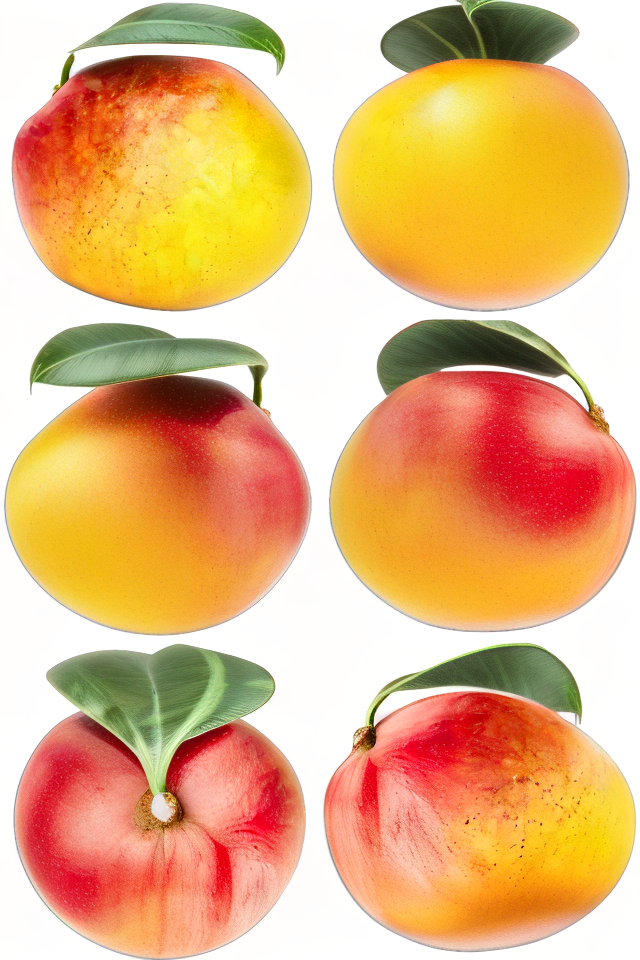

In [14]:
import torch

with torch.inference_mode():
    result = pipeline(
        processed_image,
        num_inference_steps=75,
        generator=torch.Generator(device="cuda").manual_seed(42)
    )

generated_images = result.images

print("Number of generated images:", len(generated_images))
print("Contact sheet size:", generated_images[0].size)

display(generated_images[0])

In [15]:
import os
from PIL import Image

OUTPUT_DIR = f"{BASE_DIR}/outputs"
VIEWS_DIR = f"{OUTPUT_DIR}/zero123_views"

os.makedirs(VIEWS_DIR, exist_ok=True)

# Save contact sheet
CONTACT_SHEET_PATH = f"{VIEWS_DIR}/mango_contact_sheet.png"
generated_images[0].save(CONTACT_SHEET_PATH)

# Split into six views
sheet = generated_images[0]

w, h = sheet.size
view_w = w // 2
view_h = h // 3

for i in range(6):
    row = i // 2
    col = i % 2

    view = sheet.crop((
        col * view_w,
        row * view_h,
        (col + 1) * view_w,
        (row + 1) * view_h
    ))

    view.save(f"{VIEWS_DIR}/mango_view_{i+1}.png")

print("Contact sheet:", CONTACT_SHEET_PATH)
print("Generated views:")

for i in range(1, 7):
    print(f"mango_view_{i}.png")

Contact sheet: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/mango_contact_sheet.png
Generated views:
mango_view_1.png
mango_view_2.png
mango_view_3.png
mango_view_4.png
mango_view_5.png
mango_view_6.png


In [16]:
import gc
import torch

# Release Zero123++
del pipeline
del generated_images
del result

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

free, total = torch.cuda.mem_get_info()

print("===== GPU MEMORY AFTER ZERO123++ =====")
print("Free VRAM:", round(free / 1024**3, 2), "GB")
print("Total VRAM:", round(total / 1024**3, 2), "GB")
print("Allocated:", round(
    torch.cuda.memory_allocated() / 1024**3, 2
), "GB")

print("\nSaved mango views:", len([
    f for f in os.listdir(VIEWS_DIR)
    if f.startswith("mango_view_") and f.endswith(".png")
]))

===== GPU MEMORY AFTER ZERO123++ =====
Free VRAM: 12.58 GB
Total VRAM: 14.56 GB
Allocated: 1.63 GB

Saved mango views: 6


In [18]:
import torch
import transformers.pytorch_utils as pytorch_utils

def find_pruneable_heads_and_indices(
    heads,
    n_heads,
    head_size,
    already_pruned_heads
):
    mask = torch.ones(n_heads, head_size)

    heads = set(heads) - already_pruned_heads

    for head in heads:
        head -= sum(1 for h in already_pruned_heads if h < head)
        mask[head] = 0

    index = torch.arange(mask.numel())[mask.view(-1).bool()]

    return heads, index.long()


pytorch_utils.find_pruneable_heads_and_indices = (
    find_pruneable_heads_and_indices
)

print("Transformers compatibility patch restored!")

from src.models.encoder.dino import ViTModel

def compatible_get_head_mask(self, head_mask, num_hidden_layers):
    if head_mask is None:
        return [None] * num_hidden_layers

    return self._convert_head_mask_to_5d(
        head_mask,
        num_hidden_layers
    )

ViTModel.get_head_mask = compatible_get_head_mask

print("InstantMesh DINO compatibility restored!")

Transformers compatibility patch restored!
InstantMesh DINO compatibility restored!


In [19]:
import torch
import gc

from omegaconf import OmegaConf
from src.utils.train_util import instantiate_from_config

# Load configuration
CONFIG_PATH = f"{REPO_DIR}/configs/instant-mesh-large.yaml"
MODEL_CKPT = f"{BASE_DIR}/models/instantmesh/instant_mesh_large.ckpt"

config = OmegaConf.load(CONFIG_PATH)

model_config = config.model_config
infer_config = config.infer_config

print("Configuration loaded!")
print("Grid resolution:", model_config.params.grid_res)

# Instantiate model
model = instantiate_from_config(model_config)

# Load checkpoint
checkpoint = torch.load(
    MODEL_CKPT,
    map_location="cpu",
    weights_only=False
)

state_dict = {
    k[14:]: v
    for k, v in checkpoint["state_dict"].items()
    if k.startswith("lrm_generator.")
    and "source_camera" not in k
}

load_result = model.load_state_dict(state_dict, strict=True)

print("InstantMesh checkpoint loaded!")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

del checkpoint, state_dict
gc.collect()

Configuration loaded!
Grid resolution: 128


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: facebook/dino-vitb16
Key                                              | Status  | 
-------------------------------------------------+---------+-
encoder.layer.{0...11}.adaLN_modulation.1.weight | MISSING | 
encoder.layer.{0...11}.adaLN_modulation.1.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


InstantMesh checkpoint loaded!
Missing keys: []
Unexpected keys: []


11872

In [20]:
device = torch.device("cuda")

model = model.to(device)
model.eval()

model.grid_res = 64

model.init_flexicubes_geometry(
    device,
    fovy=30.0
)

print("===== INSTANTMESH INITIALIZED =====")
print("Device:", device)
print("Grid resolution:", model.grid_res)
print("Geometry vertices:", model.geometry.verts.shape)
print("Grid cells:", model.geometry.indices.shape)

free, total = torch.cuda.mem_get_info()

print("\nFree VRAM:", round(free / 1024**3, 2), "GB")
print("Allocated:", round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

===== INSTANTMESH INITIALIZED =====
Device: cuda
Grid resolution: 64
Geometry vertices: torch.Size([274625, 3])
Grid cells: torch.Size([262144, 8])

Free VRAM: 12.58 GB
Allocated: 1.46 GB


In [22]:
import numpy as np
import torch
from PIL import Image
from einops import rearrange
from torchvision.transforms import v2
from src.utils.camera_util import get_zero123plus_input_cameras

VIEWS_DIR = f"{BASE_DIR}/outputs/zero123_views"

# Load saved contact sheet
sheet = Image.open(
    f"{VIEWS_DIR}/mango_contact_sheet.png"
).convert("RGB")

# Convert to tensor
images = np.asarray(sheet, dtype=np.float32) / 255.0

images = torch.from_numpy(images).permute(
    2, 0, 1
).contiguous().float()

# Split into 6 views (3 rows x 2 columns)
images = rearrange(
    images,
    'c (n h) (m w) -> (n m) c h w',
    n=3,
    m=2
)

# Prepare batch
input_images = images.unsqueeze(0).to(device)

input_images = v2.functional.resize(
    input_images,
    (320, 320),
    interpolation=3,
    antialias=True
).clamp(0, 1)

# Prepare camera parameters
input_cameras = get_zero123plus_input_cameras(
    batch_size=1,
    radius=4.0
).to(device)

print("Input images:", input_images.shape)
print("Input cameras:", input_cameras.shape)
print("Image range:", input_images.min().item(), input_images.max().item())

Input images: torch.Size([1, 6, 3, 320, 320])
Input cameras: torch.Size([1, 6, 16])
Image range: 0.0 1.0


In [23]:
torch.cuda.empty_cache()

with torch.inference_mode():
    planes = model.forward_planes(
        input_images,
        input_cameras
    )

print("Triplane generation successful!")
print("Planes shape:", planes.shape)

print(
    "GPU allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)


[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


Triplane generation successful!
Planes shape: torch.Size([1, 3, 80, 64, 64])
GPU allocated: 1.47 GB


In [24]:
import torch

torch.cuda.empty_cache()

with torch.inference_mode():
    mesh_out = model.extract_mesh(
        planes,
        use_texture_map=False,
        **infer_config
    )

vertices, faces, vertex_colors = mesh_out

print("===== MANGO MESH EXTRACTION =====")
print("Vertices:", vertices.shape)
print("Faces:", faces.shape)
print("Vertex colors:", vertex_colors.shape)

print("\nVertex dtype:", vertices.dtype)
print("Face dtype:", faces.dtype)
print("Color dtype:", vertex_colors.dtype)

print("\nGPU allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

===== MANGO MESH EXTRACTION =====
Vertices: (20518, 3)
Faces: (40836, 3)
Vertex colors: (20518, 3)

Vertex dtype: float32
Face dtype: int64
Color dtype: uint8

GPU allocated: 1.47 GB


In [25]:
import numpy as np
import trimesh

mesh = trimesh.Trimesh(
    vertices=vertices,
    faces=faces,
    vertex_colors=vertex_colors,
    process=False
)

print("===== MANGO MESH VALIDATION =====")
print("Watertight:", mesh.is_watertight)
print("Winding consistent:", mesh.is_winding_consistent)
print("Vertices:", len(mesh.vertices))
print("Faces:", len(mesh.faces))
print("Surface area:", mesh.area)
print("Volume:", mesh.volume)
print("Bounding box:\n", mesh.bounds)
print("Connected components:", len(mesh.split()))

print("\nFinite vertices:", np.isfinite(vertices).all())
print("Valid face indices:", faces.min() >= 0 and faces.max() < len(vertices))
print("Vertex colors:", mesh.visual.kind)

===== MANGO MESH VALIDATION =====
Watertight: True
Winding consistent: True
Vertices: 20518
Faces: 40836
Surface area: 14.105205977484273
Volume: 3.030942236001076
Bounding box:
 [[-0.95147055 -0.97196549 -0.88990116]
 [ 0.93188024  0.93392044  0.98083675]]
Connected components: 60

Finite vertices: True
Valid face indices: True
Vertex colors: vertex


In [28]:
import os
import trimesh

OUTPUT_DIR = f"{BASE_DIR}/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

GLB_PATH = f"{OUTPUT_DIR}/mango_3d.glb"
OBJ_PATH = f"{OUTPUT_DIR}/mango_3d.obj"

mesh.export(GLB_PATH)
mesh.export(OBJ_PATH)

print("===== EXPORT SUCCESSFUL =====")
print("GLB:", GLB_PATH)
print("OBJ:", OBJ_PATH)

print("GLB size:", round(os.path.getsize(GLB_PATH) / (1024**2), 2), "MB")
print("OBJ size:", round(os.path.getsize(OBJ_PATH) / (1024**2), 2), "MB")

===== EXPORT SUCCESSFUL =====
GLB: /content/drive/MyDrive/Sketch2Shape_AI/outputs/mango_3d.glb
OBJ: /content/drive/MyDrive/Sketch2Shape_AI/outputs/mango_3d.obj
GLB size: 0.78 MB
OBJ size: 2.07 MB


In [29]:
loaded_mesh = trimesh.load(
    GLB_PATH,
    force="mesh"
)

print("===== EXPORTED GLB VALIDATION =====")
print("Vertices:", len(loaded_mesh.vertices))
print("Faces:", len(loaded_mesh.faces))
print("Watertight:", loaded_mesh.is_watertight)
print("Winding consistent:", loaded_mesh.is_winding_consistent)
print("Has vertex colors:", loaded_mesh.visual.kind)
print("File exists:", os.path.exists(GLB_PATH))

===== EXPORTED GLB VALIDATION =====
Vertices: 20518
Faces: 40836
Watertight: True
Winding consistent: True
Has vertex colors: vertex
File exists: True


In [30]:
loaded_mesh.show()

In [31]:
import numpy as np

components = sorted(
    mesh.split(only_watertight=False),
    key=lambda x: len(x.faces),
    reverse=True
)

print("===== COMPONENT ANALYSIS =====")
print("Total components:", len(components))

for i, component in enumerate(components[:10]):
    print(
        f"Component {i+1}: "
        f"Vertices={len(component.vertices)}, "
        f"Faces={len(component.faces)}, "
        f"Area={component.area:.4f}, "
        f"Volume={component.volume:.4f}"
    )

total_faces = sum(len(c.faces) for c in components)

print("\nLargest component face percentage:",
      round(len(components[0].faces) / total_faces * 100, 2), "%")

===== COMPONENT ANALYSIS =====
Total components: 60
Component 1: Vertices=19854, Faces=39744, Area=13.9930, Volume=3.0312
Component 2: Vertices=62, Faces=120, Area=0.0355, Volume=-0.0005
Component 3: Vertices=62, Faces=120, Area=0.0281, Volume=0.0001
Component 4: Vertices=44, Faces=84, Area=0.0166, Volume=0.0001
Component 5: Vertices=20, Faces=36, Area=0.0041, Volume=0.0000
Component 6: Vertices=16, Faces=28, Area=0.0034, Volume=0.0000
Component 7: Vertices=12, Faces=20, Area=0.0009, Volume=-0.0000
Component 8: Vertices=12, Faces=20, Area=0.0003, Volume=-0.0000
Component 9: Vertices=12, Faces=20, Area=0.0006, Volume=-0.0000
Component 10: Vertices=12, Faces=20, Area=0.0014, Volume=-0.0000

Largest component face percentage: 97.33 %


In [32]:
import trimesh
import os

# Sort connected components by face count
components = sorted(
    mesh.split(only_watertight=False),
    key=lambda x: len(x.faces),
    reverse=True
)

# Retain the largest component
clean_mesh = components[0]

print("===== CLEANED MESH =====")
print("Original components:", len(components))
print("Retained components: 1")
print("Vertices:", len(clean_mesh.vertices))
print("Faces:", len(clean_mesh.faces))
print("Watertight:", clean_mesh.is_watertight)
print("Volume:", clean_mesh.volume)
print("Surface area:", clean_mesh.area)

# Export separately to preserve the original
CLEAN_GLB_PATH = f"{OUTPUT_DIR}/mango_3d_clean.glb"

clean_mesh.export(CLEAN_GLB_PATH)

print("\nCleaned GLB saved:", CLEAN_GLB_PATH)
print("File size:", round(
    os.path.getsize(CLEAN_GLB_PATH) / (1024**2), 2
), "MB")

===== CLEANED MESH =====
Original components: 60
Retained components: 1
Vertices: 19854
Faces: 39744
Watertight: True
Volume: 3.0312199955459413
Surface area: 13.993024651921015

Cleaned GLB saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/mango_3d_clean.glb
File size: 0.76 MB


In [33]:
clean_mesh_loaded = trimesh.load(
    CLEAN_GLB_PATH,
    force="mesh"
)

print("Loaded cleaned GLB")
print("Vertices:", len(clean_mesh_loaded.vertices))
print("Faces:", len(clean_mesh_loaded.faces))
print("Watertight:", clean_mesh_loaded.is_watertight)
print("Components:", len(clean_mesh_loaded.split()))

clean_mesh_loaded.show()

Loaded cleaned GLB
Vertices: 19854
Faces: 39744
Watertight: True
Components: 1


In [34]:
import trimesh
import os

# Create a separate copy
smoothed_mesh = clean_mesh_loaded.copy()

# Apply conservative smoothing
smoothed_mesh = trimesh.smoothing.filter_laplacian(
    smoothed_mesh,
    lamb=0.3,
    iterations=5
)

print("===== SMOOTHED MESH =====")
print("Vertices:", len(smoothed_mesh.vertices))
print("Faces:", len(smoothed_mesh.faces))
print("Watertight:", smoothed_mesh.is_watertight)
print("Volume:", smoothed_mesh.volume)
print("Components:", len(smoothed_mesh.split()))

SMOOTHED_GLB_PATH = f"{OUTPUT_DIR}/mango_3d_smoothed.glb"

smoothed_mesh.export(SMOOTHED_GLB_PATH)

print("Saved:", SMOOTHED_GLB_PATH)

smoothed_mesh.show()

===== SMOOTHED MESH =====
Vertices: 19854
Faces: 39744
Watertight: True
Volume: 3.0312199955459413
Components: 1
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/mango_3d_smoothed.glb


In [35]:
from PIL import Image

view_paths = [
    f"{VIEWS_DIR}/mango_view_{i}.png"
    for i in range(1, 7)
]

views = [Image.open(path).convert("RGB") for path in view_paths]

print("Individual view sizes:")
for i, view in enumerate(views, 1):
    print(f"View {i}: {view.size}")

display(generated_images[0])

Individual view sizes:
View 1: (320, 320)
View 2: (320, 320)
View 3: (320, 320)
View 4: (320, 320)
View 5: (320, 320)
View 6: (320, 320)


NameError: name 'generated_images' is not defined

Contact sheet size: (640, 960)


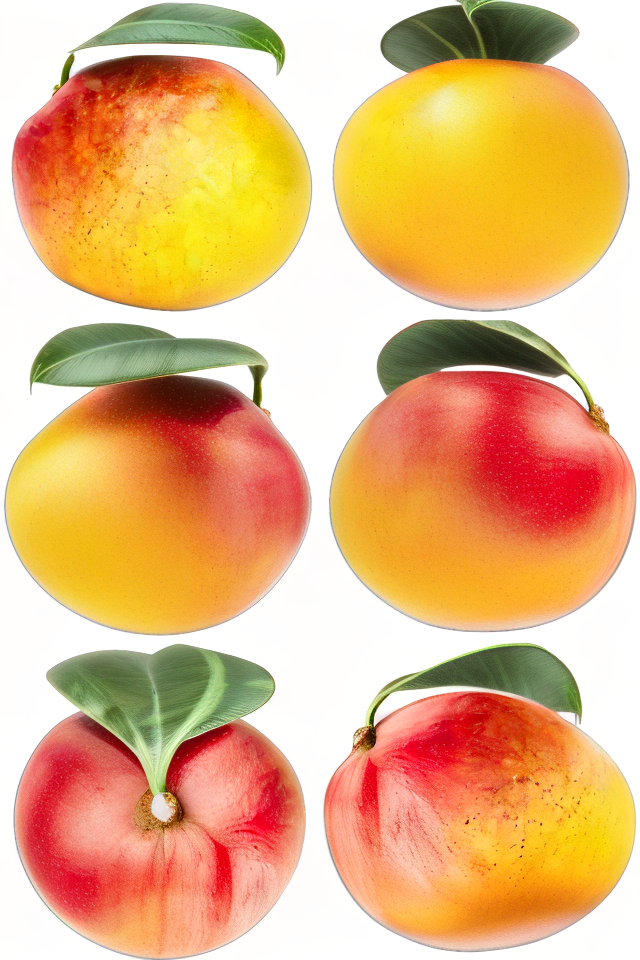

In [36]:
from PIL import Image

CONTACT_SHEET_PATH = f"{VIEWS_DIR}/mango_contact_sheet.png"

sheet = Image.open(CONTACT_SHEET_PATH).convert("RGB")

print("Contact sheet size:", sheet.size)
display(sheet)

In [37]:
print(OmegaConf.to_yaml(infer_config))

unet_path: ckpts/diffusion_pytorch_model.bin
model_path: ckpts/instant_mesh_large.ckpt
texture_resolution: 1024
render_resolution: 512



In [38]:
print("===== MODEL CONFIGURATION =====")
print(OmegaConf.to_yaml(model_config))

print("\n===== MODEL GEOMETRY =====")
print("Grid resolution:", model.grid_res)
print("Geometry vertices:", model.geometry.verts.shape)

print("\n===== INFERENCE CONFIGURATION =====")
print(OmegaConf.to_yaml(infer_config))

===== MODEL CONFIGURATION =====
target: src.models.lrm_mesh.InstantMesh
params:
  encoder_feat_dim: 768
  encoder_freeze: false
  encoder_model_name: facebook/dino-vitb16
  transformer_dim: 1024
  transformer_layers: 16
  transformer_heads: 16
  triplane_low_res: 32
  triplane_high_res: 64
  triplane_dim: 80
  rendering_samples_per_ray: 128
  grid_res: 128
  grid_scale: 2.1


===== MODEL GEOMETRY =====
Grid resolution: 64
Geometry vertices: torch.Size([274625, 3])

===== INFERENCE CONFIGURATION =====
unet_path: ckpts/diffusion_pytorch_model.bin
model_path: ckpts/instant_mesh_large.ckpt
texture_resolution: 1024
render_resolution: 512



In [39]:
print("===== DINO ENCODER INSPECTION =====")

print("Encoder:", type(model.encoder).__name__)

for name, param in model.encoder.named_parameters():
    if "adaLN_modulation" in name:
        print(
            name,
            "| Shape:", tuple(param.shape),
            "| Mean:", round(param.data.mean().item(), 6),
            "| Std:", round(param.data.std().item(), 6)
        )

===== DINO ENCODER INSPECTION =====
Encoder: DinoWrapper
model.encoder.layer.0.adaLN_modulation.1.weight | Shape: (3072, 768) | Mean: -0.000569 | Std: 0.061523
model.encoder.layer.0.adaLN_modulation.1.bias | Shape: (3072,) | Mean: -0.058476 | Std: 0.301945
model.encoder.layer.1.adaLN_modulation.1.weight | Shape: (3072, 768) | Mean: -0.000309 | Std: 0.067394
model.encoder.layer.1.adaLN_modulation.1.bias | Shape: (3072,) | Mean: -0.073236 | Std: 0.308217
model.encoder.layer.2.adaLN_modulation.1.weight | Shape: (3072, 768) | Mean: -0.001368 | Std: 0.07176
model.encoder.layer.2.adaLN_modulation.1.bias | Shape: (3072,) | Mean: 0.049048 | Std: 0.212652
model.encoder.layer.3.adaLN_modulation.1.weight | Shape: (3072, 768) | Mean: -0.001409 | Std: 0.079743
model.encoder.layer.3.adaLN_modulation.1.bias | Shape: (3072,) | Mean: 0.053298 | Std: 0.188867
model.encoder.layer.4.adaLN_modulation.1.weight | Shape: (3072, 768) | Mean: -0.000999 | Std: 0.078202
model.encoder.layer.4.adaLN_modulation.1.bi

In [41]:
checkpoint = torch.load(
    MODEL_CKPT,
    map_location="cpu",
    weights_only=False
)

original_state = checkpoint["state_dict"]

adaln_keys = [
    key for key in original_state
    if "adaLN_modulation" in key
]

print("Total adaLN parameters in checkpoint:", len(adaln_keys))

for key in adaln_keys[:10]:
    print(key)

Total adaLN parameters in checkpoint: 24
lrm_generator.encoder.model.encoder.layer.0.adaLN_modulation.1.weight
lrm_generator.encoder.model.encoder.layer.0.adaLN_modulation.1.bias
lrm_generator.encoder.model.encoder.layer.1.adaLN_modulation.1.weight
lrm_generator.encoder.model.encoder.layer.1.adaLN_modulation.1.bias
lrm_generator.encoder.model.encoder.layer.2.adaLN_modulation.1.weight
lrm_generator.encoder.model.encoder.layer.2.adaLN_modulation.1.bias
lrm_generator.encoder.model.encoder.layer.3.adaLN_modulation.1.weight
lrm_generator.encoder.model.encoder.layer.3.adaLN_modulation.1.bias
lrm_generator.encoder.model.encoder.layer.4.adaLN_modulation.1.weight
lrm_generator.encoder.model.encoder.layer.4.adaLN_modulation.1.bias


In [42]:
model_state = model.state_dict()

matched = 0
mismatched = []

for key in adaln_keys:
    model_key = key[len("lrm_generator."):]

    if model_key not in model_state:
        mismatched.append((key, "Missing from model"))
        continue

    if not torch.equal(
        original_state[key],
        model_state[model_key].cpu()
    ):
        mismatched.append((key, "Values differ"))
    else:
        matched += 1

print("===== ADALN CHECKPOINT VERIFICATION =====")
print("Total checkpoint parameters:", len(adaln_keys))
print("Exact matches:", matched)
print("Mismatches:", len(mismatched))
print("Mismatch details:", mismatched[:5])

===== ADALN CHECKPOINT VERIFICATION =====
Total checkpoint parameters: 24
Exact matches: 24
Mismatches: 0
Mismatch details: []


In [43]:
print("===== FLEXICUBES CONFIGURATION =====")

print("Model grid resolution:", model.grid_res)
print("Configured grid resolution:", model_config.params.grid_res)
print("Geometry vertex grid:", model.geometry.verts.shape)
print("Geometry cell grid:", model.geometry.indices.shape)

print("\n===== MESH EXTRACTION =====")
print("Texture resolution:", infer_config.texture_resolution)
print("Render resolution:", infer_config.render_resolution)

===== FLEXICUBES CONFIGURATION =====
Model grid resolution: 64
Configured grid resolution: 128
Geometry vertex grid: torch.Size([274625, 3])
Geometry cell grid: torch.Size([262144, 8])

===== MESH EXTRACTION =====
Texture resolution: 1024
Render resolution: 512


In [44]:
import gc
import torch

# Release previous geometry
del planes
gc.collect()
torch.cuda.empty_cache()

# Restore original resolution
model.grid_res = 128

# Reinitialize geometry
model.init_flexicubes_geometry(
    device,
    fovy=30.0
)

print("===== FLEXICUBES REINITIALIZED =====")
print("Grid resolution:", model.grid_res)
print("Geometry vertices:", model.geometry.verts.shape)
print("Geometry cells:", model.geometry.indices.shape)

free, total = torch.cuda.mem_get_info()

print("Free VRAM:", round(free / 1024**3, 2), "GB")

===== FLEXICUBES REINITIALIZED =====
Grid resolution: 128
Geometry vertices: torch.Size([2146689, 3])
Geometry cells: torch.Size([2097152, 8])
Free VRAM: 11.2 GB


In [45]:
with torch.inference_mode():
    planes_128 = model.forward_planes(
        input_images,
        input_cameras
    )

print("Triplane shape:", planes_128.shape)
print("Free VRAM:", round(
    torch.cuda.mem_get_info()[0] / 1024**3, 2
), "GB")


Triplane shape: torch.Size([1, 3, 80, 64, 64])
Free VRAM: 9.19 GB


In [47]:
import gc
import torch

# Clear memory left by the failed extraction
gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

# Use an intermediate grid resolution
model.grid_res = 80

model.init_flexicubes_geometry(
    device,
    fovy=30.0
)

print("Grid resolution:", model.grid_res)
print("Geometry vertices:", model.geometry.verts.shape)
print("Geometry cells:", model.geometry.indices.shape)

free, total = torch.cuda.mem_get_info()
print("Free VRAM:", round(free / 1024**3, 2), "GB")

Grid resolution: 80
Geometry vertices: torch.Size([531441, 3])
Geometry cells: torch.Size([512000, 8])
Free VRAM: 10.37 GB


In [48]:
with torch.inference_mode():
    mesh_out_80 = model.extract_mesh(
        planes_128,
        use_texture_map=False,
        **infer_config
    )

vertices_80, faces_80, colors_80 = mesh_out_80

print("===== RESOLUTION 80 MESH =====")
print("Vertices:", vertices_80.shape)
print("Faces:", faces_80.shape)
print("Colors:", colors_80.shape)
print("Free VRAM:", round(
    torch.cuda.mem_get_info()[0] / 1024**3, 2
), "GB")

===== RESOLUTION 80 MESH =====
Vertices: (33496, 3)
Faces: (66560, 3)
Colors: (33496, 3)
Free VRAM: 5.96 GB


In [49]:
import trimesh
import numpy as np
import os

mesh_80 = trimesh.Trimesh(
    vertices=vertices_80,
    faces=faces_80,
    vertex_colors=colors_80,
    process=False
)

print("===== MESH VALIDATION =====")
print("Watertight:", mesh_80.is_watertight)
print("Winding consistent:", mesh_80.is_winding_consistent)
print("Vertices:", len(mesh_80.vertices))
print("Faces:", len(mesh_80.faces))
print("Volume:", mesh_80.volume)
print("Surface area:", mesh_80.area)
print("Finite vertices:", np.isfinite(mesh_80.vertices).all())

GLB_80_PATH = f"{BASE_DIR}/outputs/mango_3d_res80.glb"
OBJ_80_PATH = f"{BASE_DIR}/outputs/mango_3d_res80.obj"

mesh_80.export(GLB_80_PATH)
mesh_80.export(OBJ_80_PATH)

print("\nGLB exported:", os.path.exists(GLB_80_PATH))
print("OBJ exported:", os.path.exists(OBJ_80_PATH))

===== MESH VALIDATION =====
Watertight: True
Winding consistent: True
Vertices: 33496
Faces: 66560
Volume: 3.0465563755757272
Surface area: 14.60875823087445
Finite vertices: True

GLB exported: True
OBJ exported: True


In [50]:
loaded_mesh_80 = trimesh.load(
    GLB_80_PATH,
    force="mesh"
)

loaded_mesh_80.show()

In [51]:
loaded_mesh_80 = trimesh.load(GLB_80_PATH, force="mesh")
loaded_mesh_80.show()

In [52]:
import os
from PIL import Image

EXAMPLES_DIR = f"{BASE_DIR}/examples"

print("===== AVAILABLE INPUT IMAGES =====")

for filename in os.listdir(EXAMPLES_DIR):
    path = os.path.join(EXAMPLES_DIR, filename)

    if filename.lower().endswith((".png", ".jpg", ".jpeg")):
        try:
            img = Image.open(path)
            print(f"{filename} | Size: {img.size} | Mode: {img.mode}")
        except Exception:
            pass

===== AVAILABLE INPUT IMAGES =====
processed_chair.png | Size: (851, 851) | Mode: RGBA
img 1.jpg | Size: (2048, 2048) | Mode: L
chair.png | Size: (512, 512) | Mode: RGB
img 2.jpg | Size: (1400, 1400) | Mode: RGB


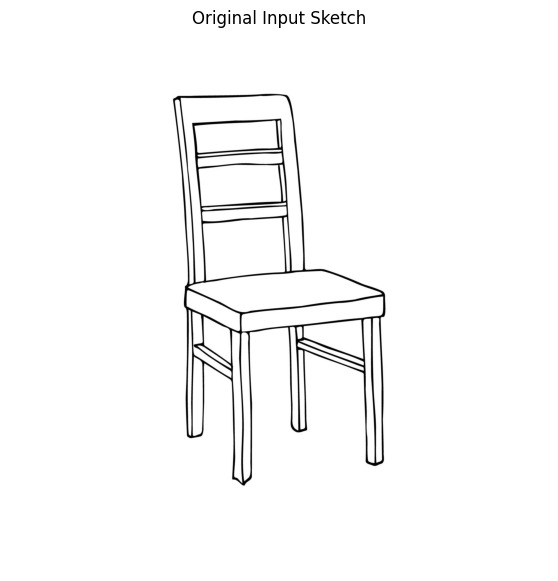

Image size: (2048, 2048)
Image mode: L


In [53]:
from PIL import Image
import matplotlib.pyplot as plt

SKETCH_INPUT = f"{BASE_DIR}/examples/img 1.jpg"

sketch = Image.open(SKETCH_INPUT).convert("L")

plt.figure(figsize=(7, 7))
plt.imshow(sketch, cmap="gray")
plt.title("Original Input Sketch")
plt.axis("off")
plt.show()

print("Image size:", sketch.size)
print("Image mode:", sketch.mode)

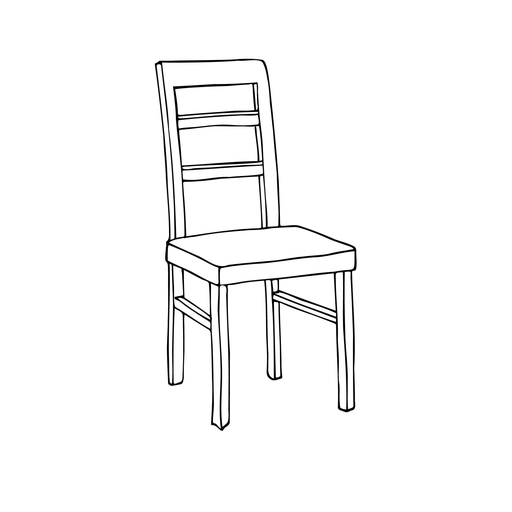

Processed size: (512, 512)
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/chair_sketch_controlnet.png


In [54]:
from PIL import Image

SKETCH_INPUT = f"{BASE_DIR}/examples/img 1.jpg"
SKETCH_PROCESSED = f"{BASE_DIR}/outputs/chair_sketch_controlnet.png"

# Load original sketch
sketch = Image.open(SKETCH_INPUT).convert("L")

# Resize while preserving the square aspect ratio
sketch = sketch.resize((512, 512), Image.Resampling.LANCZOS)

# Convert to RGB for Stable Diffusion ControlNet
sketch_rgb = sketch.convert("RGB")

# Save processed sketch
sketch_rgb.save(SKETCH_PROCESSED)

display(sketch_rgb)

print("Processed size:", sketch_rgb.size)
print("Saved:", SKETCH_PROCESSED)

In [55]:
import gc
import torch

# Move InstantMesh to CPU temporarily
model = model.to("cpu")

# Release GPU-only intermediate tensors
del planes_128
del input_images
del input_cameras

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

free, total = torch.cuda.mem_get_info()

print("InstantMesh preserved on CPU")
print("Free GPU memory:", round(free / 1024**3, 2), "GB")

InstantMesh preserved on CPU
Free GPU memory: 10.53 GB


In [56]:
import torch
from diffusers import (
    ControlNetModel,
    StableDiffusionControlNetPipeline
)

CONTROLNET_ID = "lllyasviel/sd-controlnet-scribble"
SD_MODEL_ID = "runwayml/stable-diffusion-v1-5"

# Load Scribble ControlNet
controlnet = ControlNetModel.from_pretrained(
    CONTROLNET_ID,
    torch_dtype=torch.float16
)

# Load Stable Diffusion with ControlNet
controlnet_pipeline = StableDiffusionControlNetPipeline.from_pretrained(
    SD_MODEL_ID,
    controlnet=controlnet,
    torch_dtype=torch.float16,
    safety_checker=None
)

# Memory optimizations
controlnet_pipeline.enable_attention_slicing()
controlnet_pipeline.enable_vae_slicing()

controlnet_pipeline = controlnet_pipeline.to("cuda")

print("Scribble ControlNet loaded successfully!")

free, total = torch.cuda.mem_get_info()
print("Free VRAM:", round(free / 1024**3, 2), "GB")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning:

The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning:

`torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.



Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


AttributeError: 'StableDiffusionControlNetPipeline' object has no attribute 'enable_vae_slicing'

In [57]:
# Keep attention slicing
controlnet_pipeline.enable_attention_slicing()

# Enable VAE slicing only if supported
if hasattr(controlnet_pipeline, "enable_vae_slicing"):
    controlnet_pipeline.enable_vae_slicing()
    print("VAE slicing enabled")
else:
    print("VAE slicing unavailable; skipping")

# Move pipeline to GPU
controlnet_pipeline = controlnet_pipeline.to("cuda")

print("Scribble ControlNet loaded successfully!")

free, total = torch.cuda.mem_get_info()
print("Free VRAM:", round(free / 1024**3, 2), "GB")

VAE slicing unavailable; skipping
Scribble ControlNet loaded successfully!
Free VRAM: 8.05 GB


In [58]:
!pip install -q -U huggingface_hub

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [59]:
import huggingface_hub
import diffusers
import transformers
import torch

print("Hugging Face Hub:", huggingface_hub.__version__)
print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)

Hugging Face Hub: 1.33.0
Diffusers: 0.42.1
Transformers: 5.21.0
PyTorch: 2.11.0+cu130


In [60]:
import torch
import diffusers
import transformers
import huggingface_hub
from huggingface_hub import InferenceClient

print("===== ENVIRONMENT CHECK =====")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)
print("HuggingFace Hub:", huggingface_hub.__version__)
print("InferenceClient:", InferenceClient)

print("\nControlNet pipeline exists:",
      "controlnet_pipeline" in globals())

print("InstantMesh model exists:",
      "model" in globals())

===== ENVIRONMENT CHECK =====
PyTorch: 2.11.0+cu130
CUDA available: True
Diffusers: 0.42.1
Transformers: 5.21.0
HuggingFace Hub: 1.33.0
InferenceClient: <class 'huggingface_hub.inference._client.InferenceClient'>

ControlNet pipeline exists: True
InstantMesh model exists: True


In [61]:
from huggingface_hub import InferenceClient
from getpass import getpass
import os

HF_TOKEN = getpass("Enter your Hugging Face token: ")

client = InferenceClient(
    provider="auto",
    api_key=HF_TOKEN
)

print("InferenceClient initialized successfully")
print("Chat completion available:",
      hasattr(client, "chat_completion"))

InferenceClient initialized successfully
Chat completion available: True


In [63]:
from huggingface_hub import HfApi

api = HfApi(token=HF_TOKEN)

models = api.list_models(
    pipeline_tag="image-text-to-text",
    inference_provider="all",
    limit=30
)

for m in models:
    print(m.id)

deepseek-ai/DeepSeek-V4.1-Flash-1017
mistralai/Mistral-Large-4-1T-A52B
Qwen/Qwen3.8-27B
MiniMaxAI/MiniMax-M3.1-Flash
Qwen/Qwen3.8-Flash-Next
deepseek-ai/DeepSeek-V4.1-Flash
moonshotai/Kimi-K3
zai-org/GLM-5.3-Flash
Qwen/Qwen3.5-4B
huihui-ai/Huihui-Qwen3.8-27B-abliterated
google/gemma-4-31B-it
Qwen/Qwen3.5-9B
meta-models/Muse-Spark-Open-816B-A42B
Qwen/Qwen3.6-35B-A3B
meta-models/Muse-Glimmer-30B
nvidia/NVIDIA-Nemotron-3.5-Super-VL-120B-A12B-NVFP4
google/gemma-4-26B-A4B-it
prism-ml/Ternary-Bonsai-2-9B-gguf
Qwen/Qwen3-VL-8B-Instruct
Qwen/Qwen3.5-2B
Qwen/Qwen3.8-Flash-Next-FP8
meta-models/Muse-Spark-Open-816B-A42B-NVFP4
Qwen/Qwen2.5-VL-7B-Instruct
Qwen/Qwen3-VL-4B-Instruct
Qwen/Qwen3-VL-2B-Instruct
huihui-ai/Huihui-Qwen3.5-9B-abliterated
endless-frontier/BigBang-v1
DavidAU/Qwen3.8-27B-TURBO-Fable-Cold-Fusion-735-882-Heretic-Uncensored-NM-DAU
google/gemma-3-4b-it
google/gemma-3-12b-it


In [64]:
response = client.chat_completion(
    model="Qwen/Qwen3-VL-4B-Instruct",
    messages=[
        {
            "role": "user",
            "content": [
                {
                    "type": "text",
                    "text": """
                    Analyse this chair sketch.

                    Identify:
                    1. Object name
                    2. Visible structural components
                    3. Shape and proportions
                    4. Important details to preserve

                    Do not invent materials, colors or hidden geometry.
                    Return a concise structured description.
                    """
                },
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:image/png;base64,{image_base64}"
                    }
                }
            ]
        }
    ],
    max_tokens=400
)

sketch_analysis = response.choices[0].message.content
print(sketch_analysis)

BadRequestError: (Request ID: Root=1-6ae62ef7-495c53a745798d8d2af61dac;d616e755-2a9a-4435-a605-fa50d0b131bf)

Bad request:
{'message': "The requested model 'Qwen/Qwen3-VL-4B-Instruct' is not supported by any provider you have enabled.", 'type': 'invalid_request_error', 'param': 'model', 'code': 'model_not_supported'}

In [66]:
from huggingface_hub import HfApi

api = HfApi(token=HF_TOKEN)

models = api.list_models(
    pipeline_tag="image-text-to-text",
    inference_provider="all",
    limit=100
)

print("===== AVAILABLE VISION MODELS =====")

for m in models:
    print(m.id, "|", getattr(m, "inference_provider", None))

===== AVAILABLE VISION MODELS =====
deepseek-ai/DeepSeek-V4.1-Flash-1017 | None
mistralai/Mistral-Large-4-1T-A52B | None
Qwen/Qwen3.8-27B | None
MiniMaxAI/MiniMax-M3.1-Flash | None
Qwen/Qwen3.8-Flash-Next | None
deepseek-ai/DeepSeek-V4.1-Flash | None
moonshotai/Kimi-K3 | None
zai-org/GLM-5.3-Flash | None
Qwen/Qwen3.5-4B | None
huihui-ai/Huihui-Qwen3.8-27B-abliterated | None
google/gemma-4-31B-it | None
Qwen/Qwen3.5-9B | None
meta-models/Muse-Spark-Open-816B-A42B | None
Qwen/Qwen3.6-35B-A3B | None
meta-models/Muse-Glimmer-30B | None
nvidia/NVIDIA-Nemotron-3.5-Super-VL-120B-A12B-NVFP4 | None
google/gemma-4-26B-A4B-it | None
prism-ml/Ternary-Bonsai-2-9B-gguf | None
Qwen/Qwen3-VL-8B-Instruct | None
Qwen/Qwen3.5-2B | None
Qwen/Qwen3.8-Flash-Next-FP8 | None
meta-models/Muse-Spark-Open-816B-A42B-NVFP4 | None
Qwen/Qwen2.5-VL-7B-Instruct | None
Qwen/Qwen3-VL-4B-Instruct | None
Qwen/Qwen3-VL-2B-Instruct | None
huihui-ai/Huihui-Qwen3.5-9B-abliterated | None
endless-frontier/BigBang-v1 | None
Davi

In [67]:
from huggingface_hub import HfApi

api = HfApi(token=HF_TOKEN)

candidates = [
    "Qwen/Qwen3-VL-4B-Instruct",
    "Qwen/Qwen3-VL-2B-Instruct",
    "Qwen/Qwen2.5-VL-7B-Instruct",
    "google/gemma-3-4b-it",
    "Qwen/Qwen3.5-2B"
]

for model_id in candidates:
    print(f"\n===== {model_id} =====")

    try:
        info = api.model_info(
            model_id,
            expand=["inferenceProviderMapping"]
        )

        mapping = info.inference_provider_mapping

        if mapping:
            for provider, details in mapping.items():
                print(
                    provider,
                    "| Status:", details.status,
                    "| Task:", details.task,
                    "| Provider ID:", details.provider_id
                )
        else:
            print("No provider mapping found.")

    except Exception as e:
        print("Error:", str(e)[:250])


===== Qwen/Qwen3-VL-4B-Instruct =====
Error: 'list' object has no attribute 'items'

===== Qwen/Qwen3-VL-2B-Instruct =====
Error: 'list' object has no attribute 'items'

===== Qwen/Qwen2.5-VL-7B-Instruct =====
Error: 'list' object has no attribute 'items'

===== google/gemma-3-4b-it =====
Error: 'list' object has no attribute 'items'

===== Qwen/Qwen3.5-2B =====
Error: 'list' object has no attribute 'items'


In [68]:
from huggingface_hub import HfApi

api = HfApi(token=HF_TOKEN)

candidates = [
    "Qwen/Qwen3-VL-4B-Instruct",
    "Qwen/Qwen3-VL-2B-Instruct",
    "Qwen/Qwen2.5-VL-7B-Instruct",
    "google/gemma-3-4b-it",
    "Qwen/Qwen3.5-2B"
]

for model_id in candidates:
    print(f"\n===== {model_id} =====")

    try:
        info = api.model_info(
            model_id,
            expand=["inferenceProviderMapping"]
        )

        mapping = info.inference_provider_mapping

        if not mapping:
            print("No provider mapping found.")
            continue

        for provider in mapping:
            print(
                "Provider:", provider.provider,
                "| Status:", provider.status,
                "| Task:", provider.task,
                "| Provider ID:", provider.provider_id
            )

    except Exception as e:
        print("Error:", str(e)[:300])


===== Qwen/Qwen3-VL-4B-Instruct =====
Provider: featherless-ai | Status: live | Task: conversational | Provider ID: Qwen/Qwen3-VL-4B-Instruct

===== Qwen/Qwen3-VL-2B-Instruct =====
Provider: featherless-ai | Status: live | Task: conversational | Provider ID: Qwen/Qwen3-VL-2B-Instruct

===== Qwen/Qwen2.5-VL-7B-Instruct =====
Provider: featherless-ai | Status: live | Task: conversational | Provider ID: Qwen/Qwen2.5-VL-7B-Instruct

===== google/gemma-3-4b-it =====
Provider: featherless-ai | Status: live | Task: conversational | Provider ID: google/gemma-3-4b-it
Provider: deepinfra | Status: live | Task: conversational | Provider ID: google/gemma-3-4b-it

===== Qwen/Qwen3.5-2B =====
Provider: featherless-ai | Status: live | Task: conversational | Provider ID: Qwen/Qwen3.5-2B


In [69]:
from huggingface_hub import InferenceClient

client = InferenceClient(
    provider="featherless-ai",
    api_key=HF_TOKEN
)

print("Connected to Featherless AI")


Connected to Featherless AI


In [70]:
response = client.chat_completion(
    model="Qwen/Qwen3-VL-4B-Instruct",
    messages=[
        {
            "role": "user",
            "content": [
                {
                    "type": "text",
                    "text": """
                    Analyse this chair sketch.

                    Identify:
                    1. Object name
                    2. Visible structural components
                    3. Shape and proportions
                    4. Details that must be preserved

                    Do not invent materials or hidden geometry.
                    Return a concise structured description.
                    """
                },
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:image/png;base64,{image_base64}"
                    }
                }
            ]
        }
    ],
    max_tokens=400
)

sketch_analysis = response.choices[0].message.content

print("===== CHAIR SKETCH ANALYSIS =====")
print(sketch_analysis)

HfHubHTTPError: Client error '402 Payment Required' for url 'https://router.huggingface.co/featherless-ai/v1/chat/completions' (Request ID: Root=1-6ae62f6c-7811bfc57b95a79663ea7c80;3100e00b-c022-4fce-8878-505c17fd8690)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/402

You have no remaining credits. Purchase pre-paid credits to continue using Inference Providers. Alternatively, subscribe to PRO to get monthly included credits.

In [71]:
import cv2

print("OpenCV version:", cv2.__version__)
print("Sketch pipeline preprocessing ready!")

OpenCV version: 4.14.0
Sketch pipeline preprocessing ready!


Contours detected: 1
Bounding box: (155, 59, 356, 430)
Image shape: (512, 512)


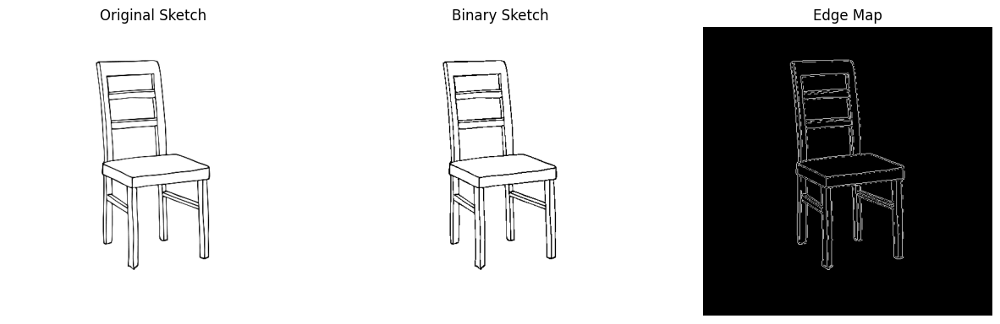

In [72]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load original sketch
SKETCH_INPUT = f"{BASE_DIR}/examples/img 1.jpg"

sketch = cv2.imread(SKETCH_INPUT, cv2.IMREAD_GRAYSCALE)

# Resize
sketch = cv2.resize(sketch, (512, 512))

# Binary threshold: black lines on white background
_, binary = cv2.threshold(
    sketch, 180, 255, cv2.THRESH_BINARY
)

# Edge detection
edges = cv2.Canny(binary, 50, 150)

# Find contours
contours, _ = cv2.findContours(
    255 - binary,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Foreground bounding box
ys, xs = np.where(binary < 255)

bbox = (
    int(xs.min()),
    int(ys.min()),
    int(xs.max()),
    int(ys.max())
)

print("Contours detected:", len(contours))
print("Bounding box:", bbox)
print("Image shape:", binary.shape)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(sketch, cmap="gray")
axes[0].set_title("Original Sketch")

axes[1].imshow(binary, cmap="gray")
axes[1].set_title("Binary Sketch")

axes[2].imshow(edges, cmap="gray")
axes[2].set_title("Edge Map")

for ax in axes:
    ax.axis("off")

plt.show()

In [73]:
def generate_controlnet_prompt(
    object_name,
    style="realistic",
    material="not specified",
    background="clean white background"
):
    prompt = f"""
    A {style} {object_name},
    based on the exact input sketch,
    preserve the original structure and proportions,
    preserve all visible components and connections,
    {material},
    realistic three-dimensional appearance,
    professional product photography,
    {background},
    single isolated object, centered composition.
    """

    negative_prompt = """
    extra parts, missing components, distorted proportions,
    duplicate objects, floating parts, disconnected components,
    unrealistic geometry, blurry, low quality,
    text, watermark.
    """

    return prompt.strip(), negative_prompt.strip()


chair_prompt, chair_negative_prompt = generate_controlnet_prompt(
    object_name="wooden dining chair",
    style="photorealistic",
    material="natural oak wood"
)

print("===== GENERATED PROMPT =====")
print(chair_prompt)

print("\n===== NEGATIVE PROMPT =====")
print(chair_negative_prompt)

===== GENERATED PROMPT =====
A photorealistic wooden dining chair,
    based on the exact input sketch,
    preserve the original structure and proportions,
    preserve all visible components and connections,
    natural oak wood,
    realistic three-dimensional appearance,
    professional product photography,
    clean white background,
    single isolated object, centered composition.

===== NEGATIVE PROMPT =====
extra parts, missing components, distorted proportions,
    duplicate objects, floating parts, disconnected components,
    unrealistic geometry, blurry, low quality,
    text, watermark.


  0%|          | 0/30 [00:00<?, ?it/s]

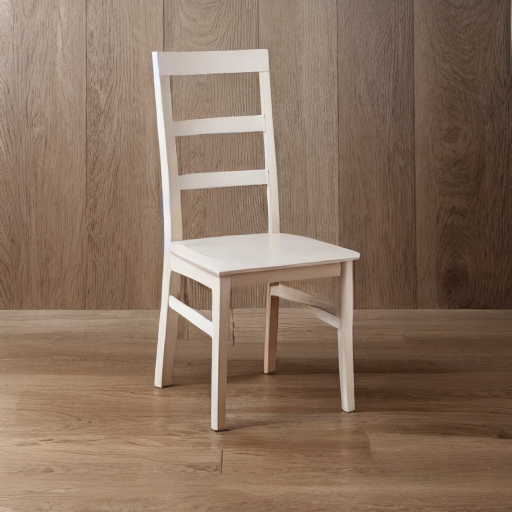

Generated image: /content/drive/MyDrive/Sketch2Shape_AI/outputs/chair_controlnet_generated.png


In [74]:
import torch
from PIL import Image

control_image = Image.open(SKETCH_PROCESSED).convert("RGB")

with torch.inference_mode():
    generated = controlnet_pipeline(
        prompt=chair_prompt,
        negative_prompt=chair_negative_prompt,
        image=control_image,
        num_inference_steps=30,
        guidance_scale=7.5,
        controlnet_conditioning_scale=1.0,
        generator=torch.Generator(device="cuda").manual_seed(42),
        height=512,
        width=512
    ).images[0]

# Save generated image
CHAIR_GENERATED_PATH = (
    f"{BASE_DIR}/outputs/chair_controlnet_generated.png"
)

generated.save(CHAIR_GENERATED_PATH)

display(generated)

print("Generated image:", CHAIR_GENERATED_PATH)

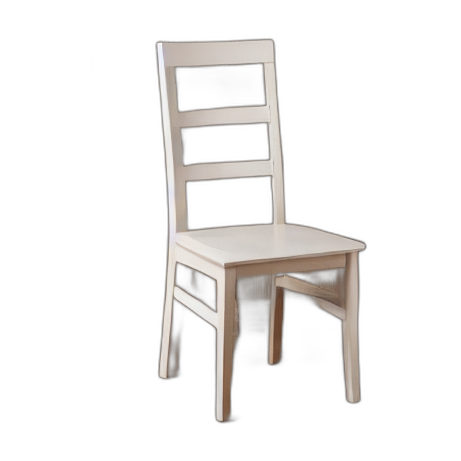

Processed size: (461, 461)
Saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/chair_controlnet_processed.png


In [75]:
from PIL import Image
import rembg

# Load generated chair
generated = Image.open(CHAIR_GENERATED_PATH).convert("RGB")

# Remove background
session = rembg.new_session(
    "u2net",
    providers=["CPUExecutionProvider"]
)

chair_rgba = rembg.remove(
    generated,
    session=session
).convert("RGBA")

# Resize foreground
from src.utils.infer_util import resize_foreground

chair_processed = resize_foreground(
    chair_rgba,
    0.85
)

# Save processed chair
CHAIR_PROCESSED_PATH = (
    f"{BASE_DIR}/outputs/chair_controlnet_processed.png"
)

chair_processed.save(CHAIR_PROCESSED_PATH)

display(chair_processed)

print("Processed size:", chair_processed.size)
print("Saved:", CHAIR_PROCESSED_PATH)

In [76]:
import gc
import torch

# Preserve ControlNet, temporarily move it to CPU
controlnet_pipeline = controlnet_pipeline.to("cpu")

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

free, total = torch.cuda.mem_get_info()

print("ControlNet preserved on CPU")
print("Free GPU memory:", round(free / 1024**3, 2), "GB")

Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `dtype=torch.float16` argument, or use another device for inference.
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `dtype=torch.float16` argument, or use another device for inference.
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lac

ControlNet preserved on CPU
Free GPU memory: 12.81 GB


In [77]:
import torch
from PIL import Image

print("CUDA available:", torch.cuda.is_available())
print("Free VRAM:", round(
    torch.cuda.mem_get_info()[0] / 1024**3, 2
), "GB")

chair_check = Image.open(
    CHAIR_PROCESSED_PATH
).convert("RGBA")

print("Chair image:", chair_check.size)
print("Chair mode:", chair_check.mode)
print("ControlNet remains in memory:",
      "controlnet_pipeline" in globals())

CUDA available: True
Free VRAM: 12.81 GB
Chair image: (461, 461)
Chair mode: RGBA
ControlNet remains in memory: True


In [78]:
import os

SNAPSHOT_DIR = (
    f"{BASE_DIR}/models/zero123plus/"
    "models--sudo-ai--zero123plus-v1.2/"
    "snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd"
)

UNET_CKPT = (
    f"{BASE_DIR}/models/instantmesh/"
    "diffusion_pytorch_model.bin"
)

print("Zero123++ snapshot exists:", os.path.isdir(SNAPSHOT_DIR))
print("Custom UNet checkpoint exists:", os.path.isfile(UNET_CKPT))

Zero123++ snapshot exists: True
Custom UNet checkpoint exists: True


In [79]:
import torch
import diffusers
import transformers

from diffusers import (
    DiffusionPipeline,
    EulerAncestralDiscreteScheduler
)

print("===== ZERO123++ ENVIRONMENT =====")
print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

print("DiffusionPipeline:", "Available")
print("EulerAncestralDiscreteScheduler:", "Available")
print("Zero123++ snapshot:", SNAPSHOT_DIR)
print("Custom UNet:", UNET_CKPT)

===== ZERO123++ ENVIRONMENT =====
Diffusers: 0.42.1
Transformers: 5.21.0
PyTorch: 2.11.0+cu130
CUDA: True
DiffusionPipeline: Available
EulerAncestralDiscreteScheduler: Available
Zero123++ snapshot: /content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd
Custom UNet: /content/drive/MyDrive/Sketch2Shape_AI/models/instantmesh/diffusion_pytorch_model.bin


In [80]:
import torch
from diffusers import DiffusionPipeline, EulerAncestralDiscreteScheduler

pipeline = DiffusionPipeline.from_pretrained(
    SNAPSHOT_DIR,
    custom_pipeline=f"{REPO_DIR}/zero123plus",
    torch_dtype=torch.float16,
    local_files_only=True,
    trust_remote_code=True
)

print("Zero123++ pipeline loaded successfully")
print("UNet type:", type(pipeline.unet).__name__)

Loading pipeline components...:   0%|          | 0/8 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/520 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

Zero123++ pipeline loaded successfully
UNet type: UNet2DConditionModel


In [81]:
state_dict = torch.load(
    UNET_CKPT,
    map_location="cpu",
    weights_only=True
)

load_result = pipeline.unet.load_state_dict(
    state_dict,
    strict=True
)

print("===== CUSTOM UNET VERIFICATION =====")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

: 

: 

: 

In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    free, total = torch.cuda.mem_get_info()
    print("Free VRAM:", round(free / 1024**3, 2), "GB")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Free VRAM: 14.46 GB


In [2]:
import os
import gc
import torch

print("===== RUNTIME CHECK =====")

for name in [
    "BASE_DIR",
    "REPO_DIR",
    "SNAPSHOT_DIR",
    "UNET_CKPT",
    "chair_processed",
    "controlnet_pipeline",
    "model",
    "pipeline"
]:
    print(f"{name}: {name in globals()}")

print("\n===== DRIVE CHECK =====")
print("Project folder exists:", os.path.exists(
    "/content/drive/MyDrive/Sketch2Shape_AI"
))

print("\n===== GPU CHECK =====")
print("CUDA:", torch.cuda.is_available())
print("Allocated:", round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

===== RUNTIME CHECK =====
BASE_DIR: False
REPO_DIR: False
SNAPSHOT_DIR: False
UNET_CKPT: False
chair_processed: False
controlnet_pipeline: False
model: False
pipeline: False

===== DRIVE CHECK =====
Project folder exists: True

===== GPU CHECK =====
CUDA: True
Allocated: 0.0 GB


In [4]:
import os
import torch
import gc

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"
REPO_DIR = "/content/InstantMesh"

SNAPSHOT_DIR = (
    f"{BASE_DIR}/models/zero123plus/"
    "models--sudo-ai--zero123plus-v1.2/"
    "snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd"
)

UNET_CKPT = f"{BASE_DIR}/models/instantmesh/diffusion_pytorch_model.bin"

MANGO_INPUT = f"{BASE_DIR}/examples/img 2.jpg"
SKETCH_INPUT = f"{BASE_DIR}/examples/img 1.jpg"

CHAIR_GENERATED_PATH = f"{BASE_DIR}/outputs/chair_controlnet_generated.png"
CHAIR_PROCESSED_PATH = f"{BASE_DIR}/outputs/chair_controlnet_processed.png"

print("===== FILE VERIFICATION =====")

paths = {
    "Project": BASE_DIR,
    "InstantMesh repository": REPO_DIR,
    "Zero123++ snapshot": SNAPSHOT_DIR,
    "Custom UNet checkpoint": UNET_CKPT,
    "Chair generated image": CHAIR_GENERATED_PATH,
    "Chair processed image": CHAIR_PROCESSED_PATH,
}

for name, path in paths.items():
    print(f"{name}: {'FOUND' if os.path.exists(path) else 'MISSING'}")

print("\nCUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

===== FILE VERIFICATION =====
Project: FOUND
InstantMesh repository: FOUND
Zero123++ snapshot: FOUND
Custom UNet checkpoint: FOUND
Chair generated image: FOUND
Chair processed image: FOUND

CUDA: True
GPU: Tesla T4


In [5]:
import sys
import gc
import torch
import numpy as np
import cv2

from PIL import Image
from pathlib import Path

from diffusers import (
    DiffusionPipeline,
    EulerAncestralDiscreteScheduler
)

sys.path.insert(0, REPO_DIR)

print("Imports successful")
print("PyTorch:", torch.__version__)
print("Diffusers:", __import__("diffusers").__version__)
print("CUDA:", torch.cuda.is_available())

Imports successful
PyTorch: 2.11.0+cu130
Diffusers: 0.42.1
CUDA: True


In [6]:
pipeline = DiffusionPipeline.from_pretrained(
    SNAPSHOT_DIR,
    custom_pipeline=f"{REPO_DIR}/zero123plus",
    torch_dtype=torch.float16,
    local_files_only=True,
    trust_remote_code=True,
    low_cpu_mem_usage=True
)

print("Zero123++ loaded successfully")
print("UNet type:", type(pipeline.unet).__name__)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/8 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/520 [00:00<?, ?it/s]

Zero123++ loaded successfully
UNet type: UNet2DConditionModel


In [7]:
import os

print("Checkpoint exists:", os.path.exists(UNET_CKPT))
print(
    "Checkpoint size:",
    round(os.path.getsize(UNET_CKPT) / (1024**3), 2),
    "GB"
)
print("UNet parameters:", sum(p.numel() for p in pipeline.unet.parameters()))

Checkpoint exists: True
Checkpoint size: 1.61 GB
UNet parameters: 865910724


In [8]:
import gc
import torch

state_dict = torch.load(
    UNET_CKPT,
    map_location="cpu",
    weights_only=True,
    mmap=True
)

load_result = pipeline.unet.load_state_dict(
    state_dict,
    strict=True
)

print("===== CUSTOM UNET VERIFICATION =====")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

del state_dict
gc.collect()

===== CUSTOM UNET VERIFICATION =====
Missing keys: []
Unexpected keys: []


37

In [9]:
pipeline.scheduler = EulerAncestralDiscreteScheduler.from_config(
    pipeline.scheduler.config,
    timestep_spacing="trailing"
)

pipeline = pipeline.to(
    device="cuda",
    dtype=torch.float16
)

print("Scheduler:", type(pipeline.scheduler).__name__)
print("Pipeline device:", next(pipeline.unet.parameters()).device)
print("Pipeline dtype:", next(pipeline.unet.parameters()).dtype)

free, total = torch.cuda.mem_get_info()
print("Free VRAM:", round(free / 1024**3, 2), "GB")

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Scheduler: EulerAncestralDiscreteScheduler
Pipeline device: cuda:0
Pipeline dtype: torch.float16
Free VRAM: 10.7 GB


In [10]:
from PIL import Image
import torch

chair_processed = Image.open(
    CHAIR_PROCESSED_PATH
).convert("RGBA")

print("Input image:", chair_processed.size)

with torch.inference_mode():
    result = pipeline(
        chair_processed,
        num_inference_steps=75,
        generator=torch.Generator(device="cuda").manual_seed(42)
    )

generated_images = result.images

print("Generated views:", len(generated_images))

Input image: (461, 461)


  0%|          | 0/75 [00:00<?, ?it/s]

Generated views: 1


Result type: <class 'diffusers.pipelines.pipeline_utils.ImagePipelineOutput'>
Images type: <class 'list'>
Number of images: 1
Image 1: size=(640, 960), mode=RGB


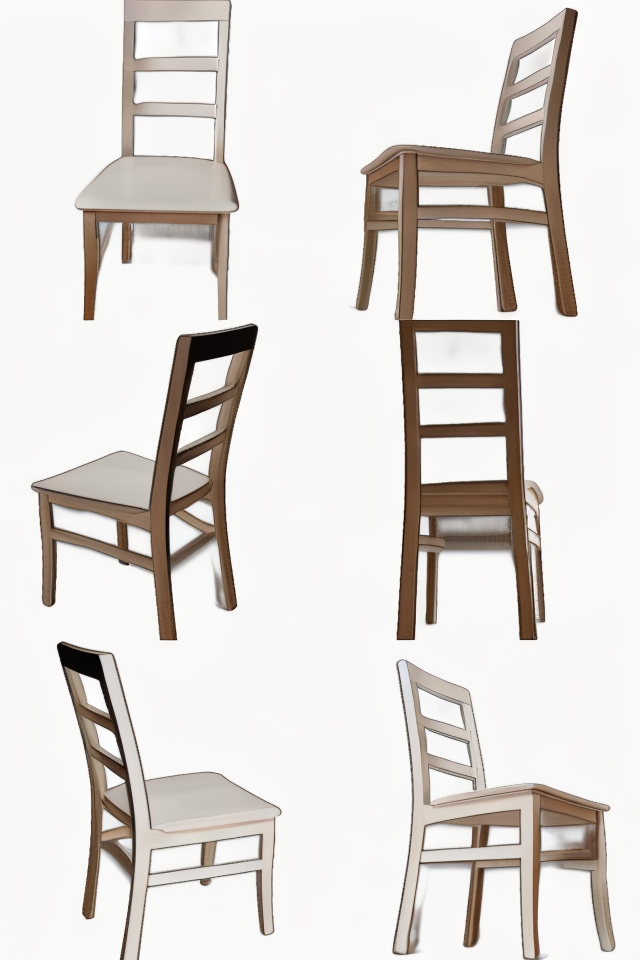

In [11]:
print("Result type:", type(result))
print("Images type:", type(result.images))
print("Number of images:", len(result.images))

for i, img in enumerate(result.images):
    print(f"Image {i+1}: size={img.size}, mode={img.mode}")
    display(img)

In [12]:
import os

from PIL import Image

contact_sheet = result.images[0]

VIEW_DIR = f"{BASE_DIR}/outputs/zero123_views/chair"
os.makedirs(VIEW_DIR, exist_ok=True)

chair_views = []

for row in range(3):
    for col in range(2):
        left = col * 320
        upper = row * 320

        view = contact_sheet.crop((
            left, upper,
            left + 320,
            upper + 320
        ))

        chair_views.append(view)

        view.save(f"{VIEW_DIR}/chair_view_{len(chair_views)}.png")

print("Total views:", len(chair_views))
print("Saved directory:", VIEW_DIR)

for i, view in enumerate(chair_views):
    print(f"View {i+1}: {view.size}")

Total views: 6
Saved directory: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views/chair
View 1: (320, 320)
View 2: (320, 320)
View 3: (320, 320)
View 4: (320, 320)
View 5: (320, 320)
View 6: (320, 320)


In [13]:
import gc
import torch

del pipeline
del result
del generated_images

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

free, total = torch.cuda.mem_get_info()

print("Zero123++ released")
print("Free VRAM:", round(free / 1024**3, 2), "GB")

Zero123++ released
Free VRAM: 14.36 GB


In [15]:
from src.utils.train_util import instantiate_from_config

print("instantiate_from_config imported successfully")

instantiate_from_config imported successfully


In [17]:
CONFIG_PATH = f"{REPO_DIR}/configs/instant-mesh-large.yaml"

config = OmegaConf.load(CONFIG_PATH)

print("Configuration loaded successfully")
print("Model type:", config.model.target)
print("Model parameters:")
print(config.model.params)

Configuration loaded successfully


ConfigAttributeError: Missing key model
    full_key: model
    object_type=dict

In [18]:
print("Top-level configuration keys:")

for key in config.keys():
    print(f"\n{key}:")
    print(OmegaConf.to_yaml(config[key])[:2000])

Top-level configuration keys:

model_config:
target: src.models.lrm_mesh.InstantMesh
params:
  encoder_feat_dim: 768
  encoder_freeze: false
  encoder_model_name: facebook/dino-vitb16
  transformer_dim: 1024
  transformer_layers: 16
  transformer_heads: 16
  triplane_low_res: 32
  triplane_high_res: 64
  triplane_dim: 80
  rendering_samples_per_ray: 128
  grid_res: 128
  grid_scale: 2.1


infer_config:
unet_path: ckpts/diffusion_pytorch_model.bin
model_path: ckpts/instant_mesh_large.ckpt
texture_resolution: 1024
render_resolution: 512



In [19]:
model_config = config.model_config

# Reduce geometry resolution for T4 memory constraints
model_config.params.grid_res = 80

print("Model target:", model_config.target)
print("Grid resolution:", model_config.params.grid_res)
print("Transformer layers:", model_config.params.transformer_layers)
print("Triplane resolution:", model_config.params.triplane_high_res)

Model target: src.models.lrm_mesh.InstantMesh
Grid resolution: 80
Transformer layers: 16
Triplane resolution: 64


In [21]:
import torch
import transformers.pytorch_utils as pytorch_utils

def find_pruneable_heads_and_indices(
    heads,
    n_heads,
    head_size,
    already_pruned_heads
):
    mask = torch.ones(n_heads, head_size)

    heads = set(heads) - already_pruned_heads

    for head in heads:
        head -= sum(1 for h in already_pruned_heads if h < head)
        mask[head] = 0

    index = torch.arange(mask.numel())[mask.view(-1).bool()]

    return heads, index.long()


pytorch_utils.find_pruneable_heads_and_indices = (
    find_pruneable_heads_and_indices
)

print("Transformers compatibility patch applied")

Transformers compatibility patch applied


In [22]:
model = instantiate_from_config(model_config)

print("InstantMesh architecture initialized")
print("Model type:", type(model).__name__)
print("Grid resolution:", model.grid_res)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:140: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: facebook/dino-vitb16
Key                                              | Status  | 
-------------------------------------------------+---------+-
encoder.layer.{0...11}.adaLN_modulation.1.bias   | MISSING | 
encoder.layer.{0...11}.adaLN_modulation.1.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


InstantMesh architecture initialized
Model type: InstantMesh
Grid resolution: 80


In [23]:
import os

MESH_CKPT = f"{BASE_DIR}/models/instantmesh/instant_mesh_large.ckpt"

print("Checkpoint exists:", os.path.exists(MESH_CKPT))

if os.path.exists(MESH_CKPT):
    print(
        "Checkpoint size:",
        round(os.path.getsize(MESH_CKPT) / (1024**3), 2),
        "GB"
    )

Checkpoint exists: True
Checkpoint size: 1.41 GB


In [24]:
import torch
import gc

checkpoint = torch.load(
    MESH_CKPT,
    map_location="cpu",
    weights_only=True,
    mmap=True
)

state_dict = checkpoint.get("state_dict", checkpoint)

# Remove the lrm_generator prefix, as in our earlier successful setup
state_dict = {
    key.replace("lrm_generator.", "", 1): value
    for key, value in state_dict.items()
    if key.startswith("lrm_generator.")
}

load_result = model.load_state_dict(state_dict, strict=True)

print("===== INSTANTMESH CHECKPOINT VERIFICATION =====")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

del checkpoint, state_dict
gc.collect()

===== INSTANTMESH CHECKPOINT VERIFICATION =====
Missing keys: []
Unexpected keys: []


98

In [25]:
model = model.cuda()
model.eval()

model.init_geometry(
    grid_res=80,
    grid_scale=2.1
)

print("InstantMesh moved to GPU")
print("Grid resolution:", model.grid_res)
print("Model device:", next(model.parameters()).device)

free, total = torch.cuda.mem_get_info()
print("Free VRAM:", round(free / 1024**3, 2), "GB")

AttributeError: 'InstantMesh' object has no attribute 'init_geometry'

In [26]:
import inspect

print("Geometry-related methods:")

for name in dir(model):
    if any(word in name.lower() for word in ["geometry", "mesh", "extract", "grid"]):
        print(name)

print("\nExtract mesh signature:")

if hasattr(model, "extract_mesh"):
    print(inspect.signature(model.extract_mesh))

Geometry-related methods:
extract_mesh
forward_geometry
get_geometry_prediction
grid_res
grid_scale
init_flexicubes_geometry
render_mesh

Extract mesh signature:
(planes: torch.Tensor, use_texture_map: bool = False, texture_resolution: int = 1024, **kwargs)


In [27]:
import inspect

print(inspect.signature(model.init_flexicubes_geometry))
print("\nMethod implementation:")
print(inspect.getsource(model.init_flexicubes_geometry))

(device, fovy=50.0)

Method implementation:
    def init_flexicubes_geometry(self, device, fovy=50.0):
        camera = PerspectiveCamera(fovy=fovy, device=device)
        renderer = NeuralRender(device, camera_model=camera)
        self.geometry = FlexiCubesGeometry(
            grid_res=self.grid_res, 
            scale=self.grid_scale, 
            renderer=renderer, 
            render_type='neural_render',
            device=device,
        )



In [28]:
model.init_flexicubes_geometry(
    device="cuda",
    fovy=50.0
)

print("FlexiCubes geometry initialized")
print("Grid resolution:", model.grid_res)
print("Grid scale:", model.grid_scale)
print("Geometry type:", type(model.geometry).__name__)

free, total = torch.cuda.mem_get_info()
print("Free VRAM:", round(free / 1024**3, 2), "GB")

FlexiCubes geometry initialized
Grid resolution: 80
Grid scale: 2.1
Geometry type: FlexiCubesGeometry
Free VRAM: 12.57 GB


In [29]:
from PIL import Image
import torch
import os

chair_views = []

for i in range(1, 7):
    path = f"{VIEW_DIR}/chair_view_{i}.png"
    img = Image.open(path).convert("RGB")
    chair_views.append(img)

print("Loaded views:", len(chair_views))

for i, img in enumerate(chair_views):
    print(f"View {i+1}: {img.size}")

Loaded views: 6
View 1: (320, 320)
View 2: (320, 320)
View 3: (320, 320)
View 4: (320, 320)
View 5: (320, 320)
View 6: (320, 320)


In [30]:
import inspect
from src.utils import infer_util

print("Available camera-related utilities:")

for name in dir(infer_util):
    if any(word in name.lower() for word in ["camera", "input", "view"]):
        obj = getattr(infer_util, name)
        print(name, inspect.signature(obj) if callable(obj) else type(obj))

Available camera-related utilities:


In [31]:
from pathlib import Path

inference_file = Path(REPO_DIR) / "run.py"

print("File exists:", inference_file.exists())

if inference_file.exists():
    source = inference_file.read_text()

    for i, line in enumerate(source.splitlines(), 1):
        if any(word in line.lower() for word in [
            "get_zero123plus_input_cameras",
            "input_cameras",
            "get_c2w",
            "forward_planes",
            "images ="
        ]):
            print(f"{i}: {line}")

File exists: True
18:     get_zero123plus_input_cameras,
181:     images = np.asarray(output_image, dtype=np.float32) / 255.0
182:     images = torch.from_numpy(images).permute(2, 0, 1).contiguous().float()     # (3, 960, 640)
183:     images = rearrange(images, 'c (n h) (m w) -> (n m) c h w', n=3, m=2)        # (6, 3, 320, 320)
194: input_cameras = get_zero123plus_input_cameras(batch_size=1, radius=4.0*args.scale).to(device)
201:     images = sample['images'].unsqueeze(0).to(device)
202:     images = v2.functional.resize(images, 320, interpolation=3, antialias=True).clamp(0, 1)
206:         images = images[:, indices]
207:         input_cameras = input_cameras[:, indices]
211:         planes = model.forward_planes(images, input_cameras)


In [32]:
import inspect
from src.utils.camera_util import get_zero123plus_input_cameras

print(inspect.signature(get_zero123plus_input_cameras))
print(inspect.getsource(get_zero123plus_input_cameras))

(batch_size=1, radius=4.0, fov=30.0)
def get_zero123plus_input_cameras(batch_size=1, radius=4.0, fov=30.0):
    """
    Get the input camera parameters.
    """
    azimuths = np.array([30, 90, 150, 210, 270, 330]).astype(float)
    elevations = np.array([20, -10, 20, -10, 20, -10]).astype(float)
    
    c2ws = spherical_camera_pose(azimuths, elevations, radius)
    c2ws = c2ws.float().flatten(-2)

    Ks = FOV_to_intrinsics(fov).unsqueeze(0).repeat(6, 1, 1).float().flatten(-2)

    extrinsics = c2ws[:, :12]
    intrinsics = torch.stack([Ks[:, 0], Ks[:, 4], Ks[:, 2], Ks[:, 5]], dim=-1)
    cameras = torch.cat([extrinsics, intrinsics], dim=-1)

    return cameras.unsqueeze(0).repeat(batch_size, 1, 1)



In [33]:
import numpy as np
import torch
from torchvision.transforms import v2
from einops import rearrange
from src.utils.camera_util import get_zero123plus_input_cameras

# Convert six PIL images to tensor
images = np.stack([
    np.asarray(img, dtype=np.float32) / 255.0
    for img in chair_views
])

images = torch.from_numpy(images)
images = images.permute(0, 3, 1, 2).contiguous()

# Shape: [1, 6, 3, 320, 320]
images = images.unsqueeze(0).cuda()

# Official InstantMesh camera parameters
input_cameras = get_zero123plus_input_cameras(
    batch_size=1,
    radius=4.0 * 1.0
).cuda()

print("Images shape:", images.shape)
print("Camera shape:", input_cameras.shape)
print("Images device:", images.device)
print("Camera device:", input_cameras.device)

Images shape: torch.Size([1, 6, 3, 320, 320])
Camera shape: torch.Size([1, 6, 16])
Images device: cuda:0
Camera device: cuda:0


In [34]:
with torch.inference_mode():
    planes = model.forward_planes(
        images,
        input_cameras
    )

print("Triplanes generated")
print("Shape:", planes.shape)
print("Device:", planes.device)
print("Data type:", planes.dtype)

free, total = torch.cuda.mem_get_info()
print("Free VRAM:", round(free / 1024**3, 2), "GB")

[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


AttributeError: 'ViTModel' object has no attribute 'get_head_mask'

In [36]:
from src.models.encoder.dino import ViTModel

def compatible_get_head_mask(self, head_mask, num_hidden_layers):
    if head_mask is None:
        return [None] * num_hidden_layers

    return self._convert_head_mask_to_5d(
        head_mask,
        num_hidden_layers
    )

ViTModel.get_head_mask = compatible_get_head_mask

print("DINO get_head_mask compatibility patch applied")

DINO get_head_mask compatibility patch applied


In [37]:
with torch.inference_mode():
    planes = model.forward_planes(
        images,
        input_cameras
    )

print("Triplanes generated successfully")
print("Shape:", planes.shape)
print("Device:", planes.device)
print("Data type:", planes.dtype)

free, total = torch.cuda.mem_get_info()
print("Free VRAM:", round(free / 1024**3, 2), "GB")

Triplanes generated successfully
Shape: torch.Size([1, 3, 80, 64, 64])
Device: cuda:0
Data type: torch.float32
Free VRAM: 10.57 GB


In [38]:
import inspect

print("Signature:")
print(inspect.signature(model.extract_mesh))

print("\nImplementation:")
print(inspect.getsource(model.extract_mesh))

Signature:
(planes: torch.Tensor, use_texture_map: bool = False, texture_resolution: int = 1024, **kwargs)

Implementation:
    def extract_mesh(
        self, 
        planes: torch.Tensor, 
        use_texture_map: bool = False,
        texture_resolution: int = 1024,
        **kwargs,
    ):
        '''
        Extract a 3D mesh from FlexiCubes. Only support batch_size 1.
        :param planes: triplane features
        :param use_texture_map: use texture map or vertex color
        :param texture_resolution: the resolution of texure map
        '''
        assert planes.shape[0] == 1
        device = planes.device

        # predict geometry first
        mesh_v, mesh_f, sdf, deformation, v_deformed, sdf_reg_loss = self.get_geometry_prediction(planes)
        vertices, faces = mesh_v[0], mesh_f[0]

        if not use_texture_map:
            # query vertex colors
            vertices_tensor = vertices.unsqueeze(0)
            vertices_colors = self.synthesizer.get_texture_predictio

In [39]:
with torch.inference_mode():
    vertices, faces, colors = model.extract_mesh(
        planes,
        use_texture_map=False
    )

print("===== CHAIR MESH =====")
print("Vertices:", vertices.shape)
print("Faces:", faces.shape)
print("Colors:", colors.shape)
print("Vertex dtype:", vertices.dtype)

===== CHAIR MESH =====
Vertices: (9926, 3)
Faces: (19872, 3)
Colors: (9926, 3)
Vertex dtype: float32


In [40]:
import trimesh
import numpy as np
import os

mesh = trimesh.Trimesh(
    vertices=vertices,
    faces=faces,
    vertex_colors=colors,
    process=True
)

print("===== MESH VALIDATION =====")
print("Watertight:", mesh.is_watertight)
print("Winding consistent:", mesh.is_winding_consistent)
print("Valid:", mesh.is_valid)
print("Surface area:", mesh.area)
print("Volume:", mesh.volume)
print("Bounds:\n", mesh.bounds)

# Export
GLB_PATH = f"{BASE_DIR}/outputs/chair_3d.glb"
OBJ_PATH = f"{BASE_DIR}/outputs/chair_3d.obj"

mesh.export(GLB_PATH)
mesh.export(OBJ_PATH)

print("\n===== EXPORT =====")
print("GLB:", GLB_PATH)
print("OBJ:", OBJ_PATH)
print("GLB size:", round(os.path.getsize(GLB_PATH)/1024**2, 2), "MB")

===== MESH VALIDATION =====
Watertight: True
Winding consistent: True


AttributeError: 'Trimesh' object has no attribute 'is_valid'

In [41]:
import numpy as np
import trimesh
import os

print("===== MESH VALIDATION =====")

print("Watertight:", mesh.is_watertight)
print("Winding consistent:", mesh.is_winding_consistent)
print("Finite vertices:", np.isfinite(mesh.vertices).all())
print("Finite faces:", np.isfinite(mesh.faces).all())
print("Surface area:", mesh.area)
print("Volume:", mesh.volume)
print("Bounds:\n", mesh.bounds)

# Export
GLB_PATH = f"{BASE_DIR}/outputs/chair_3d.glb"
OBJ_PATH = f"{BASE_DIR}/outputs/chair_3d.obj"

mesh.export(GLB_PATH)
mesh.export(OBJ_PATH)

print("\n===== EXPORT =====")
print("GLB exists:", os.path.exists(GLB_PATH))
print("OBJ exists:", os.path.exists(OBJ_PATH))
print("GLB size:", round(os.path.getsize(GLB_PATH) / 1024**2, 2), "MB")

===== MESH VALIDATION =====
Watertight: True
Winding consistent: True
Finite vertices: True
Finite faces: True
Surface area: 4.776312588663049
Volume: 0.16272738403254264
Bounds:
 [[-0.64436716 -0.50102651 -0.97904748]
 [ 0.80396885  0.73820347  0.9805519 ]]

===== EXPORT =====
GLB exists: True
OBJ exists: True
GLB size: 0.38 MB


In [42]:
print("Opening reconstructed chair...")

mesh.show()

Opening reconstructed chair...


In [44]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI"
)

print("Project exists:", PROJECT_DIR.exists())
print("Backend exists:", (PROJECT_DIR / "backend").exists())
print("Main file exists:", (PROJECT_DIR / "backend/main.py").exists())
print("Routes file exists:", (PROJECT_DIR / "backend/routes.py").exists())

Project exists: True
Backend exists: False
Main file exists: False
Routes file exists: False


In [45]:
import zipfile
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI"
)

ZIP_PATH = PROJECT_DIR / "sketch2shape_code.zip"

if not ZIP_PATH.exists():
    raise FileNotFoundError(f"ZIP not found: {ZIP_PATH}")

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(PROJECT_DIR)

print("Project extraction completed!")

Project extraction completed!


In [46]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI"
)

required_files = [
    "backend/__init__.py",
    "backend/main.py",
    "backend/routes.py",
    "backend/schemas.py",
    "ml/preprocessing.py",
    "ml/image_generation.py",
    "ml/reconstruction.py",
    "ml/mesh_validation.py",
    "services/model_loader.py",
    "services/pipeline.py",
    "frontend/app.py",
]

for file in required_files:
    exists = (PROJECT_DIR / file).exists()
    print(f"{'✅' if exists else '❌'} {file}")

✅ backend/__init__.py
✅ backend/main.py
✅ backend/routes.py
✅ backend/schemas.py
✅ ml/preprocessing.py
✅ ml/image_generation.py
✅ ml/reconstruction.py
✅ ml/mesh_validation.py
✅ services/model_loader.py
✅ services/pipeline.py
✅ frontend/app.py


In [47]:
from pathlib import Path
import torch

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI"
)

INSTANTMESH_DIR = Path("/content/InstantMesh")

required_paths = {
    "InstantMesh repository": INSTANTMESH_DIR,
    "InstantMesh config": INSTANTMESH_DIR / "configs/instant-mesh-large.yaml",
    "InstantMesh checkpoint": PROJECT_DIR / "models/instantmesh/instant_mesh_large.ckpt",
    "InstantMesh UNet checkpoint": PROJECT_DIR / "models/instantmesh/diffusion_pytorch_model.bin",
    "Zero123++ model": PROJECT_DIR / "models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd",
}

for name, path in required_paths.items():
    print(f"{'✅' if path.exists() else '❌'} {name}: {path.exists()}")

print("\nGPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")

✅ InstantMesh repository: True
✅ InstantMesh config: True
✅ InstantMesh checkpoint: True
✅ InstantMesh UNet checkpoint: True
✅ Zero123++ model: True

GPU: Tesla T4


In [50]:
import sys
import py_compile
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI"
)

sys.path.insert(0, str(PROJECT_DIR))

files = [
    "backend/main.py",
    "backend/routes.py",
    "backend/schemas.py",
    "ml/preprocessing.py",
    "ml/image_generation.py",
    "ml/reconstruction.py",
    "ml/mesh_validation.py",
    "services/model_loader.py",
    "services/pipeline.py",
    "frontend/app.py"
]

for file in files:
    try:
        py_compile.compile(
            str(PROJECT_DIR / file),
            doraise=True
        )
        print("✅", file)
    except Exception as error:
        print("❌", file, error)

✅ backend/main.py
✅ backend/routes.py
✅ backend/schemas.py
✅ ml/preprocessing.py
✅ ml/image_generation.py
✅ ml/reconstruction.py
✅ ml/mesh_validation.py
✅ services/model_loader.py
✅ services/pipeline.py
✅ frontend/app.py


In [51]:
import importlib.util

packages = [
    "fastapi",
    "uvicorn",
    "multipart",
    "gradio",
    "torch",
    "diffusers",
    "transformers",
    "cv2",
    "rembg",
    "trimesh",
    "omegaconf",
    "yaml",
    "xatlas",
    "nvdiffrast"
]

for package in packages:
    try:
        available = importlib.util.find_spec(package) is not None
        print(f"{'✅' if available else '❌'} {package}")
    except (ImportError, ValueError):
        print(f"❌ {package}")

✅ fastapi
✅ uvicorn
✅ multipart
✅ gradio
✅ torch
✅ diffusers
✅ transformers
✅ cv2
✅ rembg
✅ trimesh
✅ omegaconf
✅ yaml
✅ xatlas
✅ nvdiffrast


In [52]:
import sys
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI"
)

INSTANTMESH_DIR = Path("/content/InstantMesh")

sys.path.insert(0, str(PROJECT_DIR))
sys.path.insert(0, str(INSTANTMESH_DIR))

try:
    from ml.preprocessing import preprocess_sketch, remove_background
    print("✅ Preprocessing")

    from ml.image_generation import ImageGenerator
    print("✅ Image generation")

    from ml.reconstruction import Reconstruction
    print("✅ Reconstruction")

    from ml.mesh_validation import MeshValidator
    print("✅ Mesh validation")

    from services.model_loader import ModelLoader
    print("✅ Model loader")

    from services.pipeline import Sketch2ShapePipeline
    print("✅ Pipeline")

    from backend.main import app
    print("✅ FastAPI application")

except Exception as error:
    print("\n❌ IMPORT ERROR:")
    print(type(error).__name__, error)

✅ Preprocessing
✅ Image generation
✅ Reconstruction
✅ Mesh validation
✅ Model loader
✅ Pipeline
✅ FastAPI application


In [53]:
import subprocess
import sys
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI"
)

log_file = PROJECT_DIR / "outputs/backend.log"

command = [
    sys.executable,
    "-m",
    "uvicorn",
    "backend.main:app",
    "--host", "0.0.0.0",
    "--port", "8000"
]

with open(log_file, "w") as log:
    process = subprocess.Popen(
        command,
        cwd=str(PROJECT_DIR),
        stdout=log,
        stderr=subprocess.STDOUT
    )

print("FastAPI process started.")
print("Process ID:", process.pid)
print("Log file:", log_file)

FastAPI process started.
Process ID: 74961
Log file: /content/drive/MyDrive/Sketch2Shape_AI/outputs/backend.log


In [54]:
import requests
import time

for attempt in range(10):
    try:
        response = requests.get(
            "http://127.0.0.1:8000/",
            timeout=5
        )

        print("Status:", response.status_code)
        print("Response:", response.json())
        break

    except requests.RequestException:
        time.sleep(2)

else:
    print("Backend did not respond. Check backend.log.")

Backend did not respond. Check backend.log.


In [56]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI"
)

log_file = PROJECT_DIR / "outputs/backend.log"

if log_file.exists():
    print(log_file.read_text()[-12000:])
else:
    print("Backend log file not found.")

Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/usr/local/lib/python3.13/dist-packages/uvicorn/__main__.py", line 4, in <module>
    uvicorn.main()
    ~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/click/core.py", line 1631, in __call__
    return self.main(*args, **kwargs)
           ~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/click/core.py", line 1552, in main
    rv = self.invoke(ctx)
  File "/usr/local/lib/python3.13/dist-packages/click/core.py", line 1415, in invoke
    return ctx.invoke(self.callback, **ctx.params)
           ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/click/core.py", line 910, in invoke
    return callback(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/uvicorn/main.py", line 448, in main
    run(
    ~~~^
        app,
        ^^^^
    ...<49 lines>...
   

In [57]:
print("Process status:", process.poll())

Process status: 1


In [58]:
from src.utils.camera_util import get_zero123plus_input_cameras

In [59]:
import sys
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI"
)

INSTANTMESH_DIR = Path("/content/InstantMesh")

sys.path.insert(0, str(PROJECT_DIR))
sys.path.insert(0, str(INSTANTMESH_DIR))

from ml.reconstruction import Reconstruction

print("Reconstruction import successful!")

Reconstruction import successful!


In [60]:
import subprocess
import sys
import time
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI"
)

log_file = PROJECT_DIR / "outputs/backend.log"

command = [
    sys.executable,
    "-m", "uvicorn",
    "backend.main:app",
    "--host", "0.0.0.0",
    "--port", "8000"
]

with open(log_file, "w") as log:
    process = subprocess.Popen(
        command,
        cwd=str(PROJECT_DIR),
        stdout=log,
        stderr=subprocess.STDOUT
    )

time.sleep(5)

print("Process status:", process.poll())
print("\nBackend logs:")
print(log_file.read_text()[-6000:])

Process status: None

Backend logs:



In [61]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8000/",
        timeout=10
    )

    print("HTTP Status:", response.status_code)
    print("Response:", response.json())

except requests.RequestException as error:
    print("Connection error:", error)

HTTP Status: 200
Response: {'message': 'Welcome to Sketch2Shape AI', 'status': 'running', 'documentation': '/docs'}


In [62]:
import requests

response = requests.get(
    "http://127.0.0.1:8000/api/health",
    timeout=10
)

print("HTTP Status:", response.status_code)
print("Health Response:", response.json())

HTTP Status: 200
Health Response: {'status': 'healthy', 'device': 'cuda', 'message': 'Sketch2Shape AI backend is running.'}


In [63]:
response = requests.get(
    "http://127.0.0.1:8000/docs",
    timeout=10
)

print("Swagger UI available:", response.status_code == 200)

Swagger UI available: True


In [65]:
from google.colab import output

output.serve_kernel_port_as_window(8000)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [66]:
from IPython.display import IFrame

In [67]:
output.serve_kernel_port_as_window(8000)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [68]:
from google.colab import output

backend_url = output.eval_js(
    "google.colab.kernel.proxyPort(8000)"
)

print("Backend URL:", backend_url)

: 

In [1]:
import os
import subprocess
import sys
import time
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI"
)

# Confirm backend is running
if process.poll() is not None:
    raise RuntimeError("FastAPI backend is not running. Restart it first.")

# Configure frontend to communicate with FastAPI
env = os.environ.copy()
env["SKETCH2SHAPE_API"] = "http://127.0.0.1:8000"

frontend_log = PROJECT_DIR / "outputs/frontend.log"

with open(frontend_log, "w") as log:
    frontend_process = subprocess.Popen(
        [
            sys.executable,
            "frontend/app.py"
        ],
        cwd=str(PROJECT_DIR),
        env=env,
        stdout=log,
        stderr=subprocess.STDOUT
    )

time.sleep(8)

print("Frontend process:", frontend_process.poll())
print("Frontend log:")
print(frontend_log.read_text()[-4000:])

NameError: name 'process' is not defined

In [2]:
import sys
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI"
)

INSTANTMESH_DIR = Path("/content/InstantMesh")

sys.path.insert(0, str(PROJECT_DIR))
sys.path.insert(0, str(INSTANTMESH_DIR))

print("Project:", PROJECT_DIR.exists())
print("InstantMesh:", INSTANTMESH_DIR.exists())

Project: False
InstantMesh: False


In [3]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI"
)

print("Project exists:", PROJECT_DIR.exists())

if PROJECT_DIR.exists():
    print("Project contents:")
    for item in PROJECT_DIR.iterdir():
        print("-", item.name)

Project exists: True
Project contents:
- models
- inputs
- outputs
- examples
- sketch2shape_code.zip
- backend
- .gitignore
- README.md
- requirements.txt
- docs
- tests
- configs
- notebooks
- frontend
- services
- ml


In [5]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("PyTorch:", torch.__version__)

CUDA available: True
GPU: Tesla T4
PyTorch: 2.11.0+cu130


In [6]:
import subprocess
from pathlib import Path

INSTANTMESH_DIR = Path("/content/InstantMesh")

if not INSTANTMESH_DIR.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/TencentARC/InstantMesh.git",
            str(INSTANTMESH_DIR)
        ],
        check=True
    )

print("InstantMesh restored:", INSTANTMESH_DIR.exists())

InstantMesh restored: True


In [7]:
import sys

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI"
)

sys.path.insert(0, str(PROJECT_DIR))
sys.path.insert(0, str(INSTANTMESH_DIR))

print("Project path configured.")
print("InstantMesh path configured.")

Project path configured.
InstantMesh path configured.


In [8]:
import sys
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI"
)

INSTANTMESH_DIR = Path("/content/InstantMesh")

sys.path.insert(0, str(PROJECT_DIR))
sys.path.insert(0, str(INSTANTMESH_DIR))

print("Project:", PROJECT_DIR.exists())
print("InstantMesh:", INSTANTMESH_DIR.exists())

Project: True
InstantMesh: True


In [9]:
import subprocess
import sys

backend_log = PROJECT_DIR / "outputs/backend.log"

with open(backend_log, "w") as log:
    process = subprocess.Popen(
        [
            sys.executable, "-m", "uvicorn",
            "backend.main:app",
            "--host", "0.0.0.0",
            "--port", "8000"
        ],
        cwd=str(PROJECT_DIR),
        stdout=log,
        stderr=subprocess.STDOUT
    )

print("Backend PID:", process.pid)

Backend PID: 4047


In [10]:
import requests
import time

for attempt in range(15):
    try:
        response = requests.get(
            "http://127.0.0.1:8000/",
            timeout=5
        )
        print("Status:", response.status_code)
        print(response.json())
        break
    except requests.RequestException:
        time.sleep(2)
else:
    print(backend_log.read_text()[-8000:])

Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/usr/local/lib/python3.13/dist-packages/uvicorn/__main__.py", line 4, in <module>
    uvicorn.main()
    ~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/click/core.py", line 1631, in __call__
    return self.main(*args, **kwargs)
           ~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/click/core.py", line 1552, in main
    rv = self.invoke(ctx)
  File "/usr/local/lib/python3.13/dist-packages/click/core.py", line 1415, in invoke
    return ctx.invoke(self.callback, **ctx.params)
           ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/click/core.py", line 910, in invoke
    return callback(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/uvicorn/main.py", line 448, in main
    run(
    ~~~^
        app,
        ^^^^
    ...<49 lines>...
   

In [11]:
import os

env = os.environ.copy()
env["SKETCH2SHAPE_API"] = "http://127.0.0.1:8000"

frontend_log = PROJECT_DIR / "outputs/frontend.log"

with open(frontend_log, "w") as log:
    frontend_process = subprocess.Popen(
        [sys.executable, "frontend/app.py"],
        cwd=str(PROJECT_DIR),
        env=env,
        stdout=log,
        stderr=subprocess.STDOUT
    )

print("Frontend PID:", frontend_process.pid)

Frontend PID: 4327


In [12]:
frontend_process.terminate()
print("Frontend stopped.")

Frontend stopped.


In [13]:
%pip install rembg onnxruntime

INFO: pip is looking at multiple versions of numba to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 41.1 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 84.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.7/13.7 MB 112.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 66.6 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 132.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.7/59.7 MB 62.3 MB/s  0:00:006m0:00:0100:01
  Attempting uninstall: pillow
    Found existing installation: pillow 11.3.0
    Uninstalling pillow-11.3.0:
      Successfully uninstalled pillow-11.3.0
  Attempting uninstall: numpy━━━━━━━━━━━━━━━━━━━ 0/8 [pillow]
    Found existing installation: numpy 2.1.3 0/8 [pillow]
    Uninstalling numpy-2.1.3:━━━━━━━━━━━━━━━ 0/8 [pillow]
      Successfully uninstalled numpy

In [14]:
import rembg
import onnxruntime

print("rembg:", rembg.__version__)
print("ONNX Runtime:", onnxruntime.__version__)

AttributeError: module 'numpy._core._multiarray_umath' has no attribute '_blas_supports_fpe'

In [15]:
from importlib.metadata import version, PackageNotFoundError

packages = [
    "numpy",
    "scipy",
    "numba",
    "pymatting",
    "rembg",
    "onnxruntime"
]

for package in packages:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

numpy: 2.5.4
scipy: 1.16.3
numba: 0.68.1
pymatting: 1.1.16
rembg: 2.0.86
onnxruntime: 1.31.1


In [16]:
import numpy as np
print("NumPy:", np.__version__)
print("NumPy import: OK")

NumPy: 2.1.3
NumPy import: OK


In [17]:
import scipy
print("SciPy:", scipy.__version__)
print("SciPy import: OK")

SciPy: 1.16.3
SciPy import: OK


In [18]:
import numba
print("Numba:", numba.__version__)
print("Numba import: OK")

Numba: 0.68.1
Numba import: OK


In [19]:
import torch

print("Torch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

Torch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4


In [20]:
import rembg

print("rembg imported successfully!")
print("Version:", rembg.__version__)

AttributeError: module 'numpy._core._multiarray_umath' has no attribute '_blas_supports_fpe'

In [21]:
%pip install --no-cache-dir --force-reinstall \
    "numpy==2.1.3" \
    "scipy==1.16.3" \
    "numba==0.68.1" \
    "pymatting==1.1.16" \
    "rembg==2.0.86" \
    "onnxruntime==1.31.1"

INFO: pip is looking at multiple versions of rembg to determine which version is compatible with other requirements. This could take a while.
ERROR: Cannot install numba==0.68.1, numpy==2.1.3, pymatting==1.1.16, rembg==2.0.86 and scipy==1.16.3 because these package versions have conflicting dependencies.

The conflict is caused by:
    The user requested numpy==2.1.3
    scipy 1.16.3 depends on numpy<2.6 and >=1.25.2
    numba 0.68.1 depends on numpy<2.6 and >=1.22
    pymatting 1.1.16 depends on numpy>=1.16.0
    rembg 2.0.86 depends on numpy<3.0.0 and >=2.3.0

Additionally, some packages in these conflicts have no matching distributions available for your environment:
    numpy

To fix this you could try to:
1. loosen the range of package versions you've specified
2. remove package versions to allow pip to attempt to solve the dependency conflict

ERROR: ResolutionImpossible: for help visit https://pip.pypa.io/en/latest/topics/dependency-resolution/#dealing-with-dependency-conflicts


In [22]:
import cv2
import numpy as np
from PIL import Image

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("PIL:", Image.__version__ if hasattr(Image, "__version__") else "OK")

OpenCV: 4.14.0
NumPy: 2.1.3
PIL: 11.3.0


In [23]:

def remove_background(
    input_path: str,
    output_path: str,
    foreground_scale: float = 0.85,
    model_name: str = "opencv"
) -> Image.Image:
    """
    Remove background using OpenCV GrabCut.
    No rembg or ONNX Runtime required.
    """

    image = cv2.imread(input_path)

    if image is None:
        raise FileNotFoundError(input_path)

    height, width = image.shape[:2]

    mask = np.zeros((height, width), np.uint8)

    background_model = np.zeros((1, 65), np.float64)
    foreground_model = np.zeros((1, 65), np.float64)

    margin_x = max(1, int(width * 0.05))
    margin_y = max(1, int(height * 0.05))

    rectangle = (
        margin_x,
        margin_y,
        width - 2 * margin_x,
        height - 2 * margin_y
    )

    cv2.grabCut(
        image,
        mask,
        rectangle,
        background_model,
        foreground_model,
        5,
        cv2.GC_INIT_WITH_RECT
    )

    foreground_mask = np.where(
        (mask == cv2.GC_FGD) |
        (mask == cv2.GC_PR_FGD),
        255,
        0
    ).astype(np.uint8)

    rgba = cv2.cvtColor(image, cv2.COLOR_BGR2RGBA)
    rgba[:, :, 3] = foreground_mask

    result = Image.fromarray(rgba)

    bbox = result.getchannel("A").getbbox()

    if bbox is None:
        raise ValueError("No foreground object detected.")

    foreground = result.crop(bbox)

    canvas_size = 512
    max_size = int(canvas_size * foreground_scale)

    foreground.thumbnail(
        (max_size, max_size),
        Image.Resampling.LANCZOS
    )

    canvas = Image.new(
        "RGBA",
        (canvas_size, canvas_size),
        (0, 0, 0, 0)
    )

    x = (canvas_size - foreground.width) // 2
    y = (canvas_size - foreground.height) // 2

    canvas.alpha_composite(foreground, (x, y))
    canvas.save(output_path)

    return canvas


In [24]:
import numpy as np

umath = np._core._multiarray_umath

if not hasattr(umath, "_blas_supports_fpe"):
    umath._blas_supports_fpe = lambda *args, **kwargs: False

print(
    "Compatibility patch applied:",
    hasattr(umath, "_blas_supports_fpe")
)

Compatibility patch applied: True


In [26]:
%pip install --no-cache-dir --force-reinstall --no-deps "numpy==2.1.3"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 184.9 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled numpy-2.5.4


In [27]:
import numpy as np

print("NumPy:", np.__version__)
print("NumPy location:", np.__file__)
print("NumPy array test:", np.array([1, 2, 3]))

NumPy: 2.1.3
NumPy location: /usr/local/lib/python3.13/dist-packages/numpy/__init__.py
NumPy array test: [1 2 3]


In [28]:
import scipy.linalg
print("SciPy linear algebra working")

SciPy linear algebra working


In [29]:
from rembg import remove, new_session

print("rembg working")

rembg working


In [31]:
%pip install trimesh==5.2.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 751.5/751.5 kB 8.3 MB/s  0:00:00


In [32]:
import trimesh

print("Trimesh:", trimesh.__version__)
print("Mesh export support:", trimesh.available_formats())

Trimesh: 5.2.0
Mesh export support: {'gltf', '3dxml', 'bz2', 'zip', 'xaml', 'tar.gz', 'obj', 'tar.bz2', 'stl', 'ply', 'glb', 'stl_ascii', 'dxf', 'off', 'xyz', '3mf'}


In [34]:
import sys
from pathlib import Path

INSTANTMESH_DIR = Path("/content/InstantMesh")

print("Repository exists:", INSTANTMESH_DIR.exists())

if str(INSTANTMESH_DIR) not in sys.path:
    sys.path.insert(0, str(INSTANTMESH_DIR))

print("InstantMesh path added.")

Repository exists: True
InstantMesh path added.


In [37]:
from pathlib import Path
import os
import sys

print("Current directory:", os.getcwd())
print("Python path entries:")

for p in sys.path[:10]:
    print(" ", p)

print("\nChecking repository locations:")

for path in [
    Path("/content/InstantMesh"),
    Path("/content/drive/MyDrive/InstantMesh"),
    Path("/content/drive/MyDrive/Sketch2Shape_AI/InstantMesh")
]:
    print(path, "Exists:", path.exists())

    if path.exists():
        print("Contents:", [x.name for x in path.iterdir()][:15])

Current directory: /content
Python path entries:
  /content/InstantMesh
  /content/drive/MyDrive/Sketch2Shape_AI
  /content/InstantMesh
  /content/drive/MyDrive/Sketch2Shape_AI
  /content/InstantMesh
  /content/drive/MyDrive/Sketch2Shape_AI
  /content
  /env/python
  /usr/lib/python313.zip
  /usr/lib/python3.13

Checking repository locations:
/content/InstantMesh Exists: True
Contents: ['README.md', 'src', 'assets', 'app.py', '.git', 'docker', 'train.py', 'LICENSE', 'requirements.txt', 'configs', '.gitignore', 'examples', 'run.py', 'zero123plus']
/content/drive/MyDrive/InstantMesh Exists: False
/content/drive/MyDrive/Sketch2Shape_AI/InstantMesh Exists: False


In [38]:
from pathlib import Path
import sys

INSTANTMESH_DIR = Path("/content/InstantMesh")

print("src directory:", (INSTANTMESH_DIR / "src").exists())
print("src __init__.py:", (INSTANTMESH_DIR / "src/__init__.py").exists())

# Put InstantMesh first in Python's search path
sys.path.insert(0, "/content/InstantMesh")

print("Resolved path:", sys.path[0])

src directory: True
src __init__.py: True
Resolved path: /content/InstantMesh


In [39]:
import importlib.util

spec = importlib.util.find_spec("src")

print("src module found:", spec is not None)

if spec:
    print("Module location:", spec.origin or spec.submodule_search_locations)

src module found: False


In [40]:
from src.utils.camera_util import get_zero123plus_input_cameras

print("InstantMesh camera utilities imported successfully!")

ModuleNotFoundError: No module named 'src'

In [41]:
import os
import sys
import importlib
import importlib.util
from pathlib import Path
from importlib.machinery import PathFinder

repo = Path("/content/InstantMesh")
src = repo / "src"

print("Repository:", repo.resolve())
print("src path:", src.resolve())
print("src is directory:", src.is_dir())
print("init is file:", (src / "__init__.py").is_file())
print("Read permission:", os.access(src, os.R_OK))

print("\nDirectory contents:")
print(os.listdir(src)[:20])

print("\nPython path:")
print(sys.path[:5])

print("\nPathFinder result:")
print(PathFinder.find_spec("src", [str(repo)]))

print("\nsrc already loaded:", "src" in sys.modules)

Repository: /content/InstantMesh
src path: /content/InstantMesh/src
src is directory: True
init is file: True
Read permission: True

Directory contents:
['model_mesh.py', 'model.py', 'utils', 'models', 'data', '__init__.py']

Python path:
['/content/InstantMesh', '/content/InstantMesh', '/content/drive/MyDrive/Sketch2Shape_AI', '/content/InstantMesh', '/content/drive/MyDrive/Sketch2Shape_AI']

PathFinder result:
None

src already loaded: False


In [42]:
import sys
import os
import importlib
import importlib.util
from importlib.machinery import PathFinder

repo = "/content/InstantMesh"

# Refresh Python's import caches
importlib.invalidate_caches()

# Remove stale importer cache for this directory
sys.path_importer_cache.pop(repo, None)

# Ensure repository is first
sys.path.insert(0, repo)

# Refresh again
importlib.invalidate_caches()

print("Path exists:", os.path.isdir(repo))
print("src exists:", os.path.isdir(os.path.join(repo, "src")))
print("src init exists:", os.path.isfile(os.path.join(repo, "src", "__init__.py")))

spec = PathFinder.find_spec("src", [repo])

print("Package discovery:", spec)

if spec is not None:
    print("Package location:", spec.origin)

Path exists: True
src exists: True
src init exists: True
Package discovery: ModuleSpec(name='src', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7c3303008710>, origin='/content/InstantMesh/src/__init__.py', submodule_search_locations=['/content/InstantMesh/src'])
Package location: /content/InstantMesh/src/__init__.py


In [43]:
import src

print("Imported src from:", src.__file__)

from src.utils.camera_util import get_zero123plus_input_cameras

print("InstantMesh camera utilities imported successfully!")

Imported src from: /content/InstantMesh/src/__init__.py
InstantMesh camera utilities imported successfully!


In [44]:
import sys
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Sketch2Shape_AI")
INSTANTMESH_DIR = Path("/content/InstantMesh")

sys.path.insert(0, str(PROJECT_DIR))
sys.path.insert(0, str(INSTANTMESH_DIR))

from ml.preprocessing import preprocess_sketch, remove_background
from ml.image_generation import ImageGenerator
from ml.reconstruction import Reconstruction
from ml.mesh_validation import MeshValidator
from services.model_loader import ModelLoader
from services.pipeline import Sketch2ShapePipeline
from backend.main import app

print("All application imports successful!")

All application imports successful!


In [45]:
import subprocess
import sys
import time

backend_log = PROJECT_DIR / "outputs/backend.log"

with open(backend_log, "w") as log:
    process = subprocess.Popen(
        [
            sys.executable, "-m", "uvicorn",
            "backend.main:app",
            "--host", "0.0.0.0",
            "--port", "8000"
        ],
        cwd=str(PROJECT_DIR),
        stdout=log,
        stderr=subprocess.STDOUT
    )

time.sleep(5)

print("Backend PID:", process.pid)
print("Process status:", process.poll())
print(backend_log.read_text()[-5000:])

Backend PID: 8537
Process status: None



In [46]:
import requests

response = requests.get("http://127.0.0.1:8000/", timeout=10)

print("HTTP Status:", response.status_code)
print("Response:", response.json())

HTTP Status: 200
Response: {'message': 'Welcome to Sketch2Shape AI', 'status': 'running', 'documentation': '/docs'}


In [47]:
import os
import subprocess
import sys
import time

env = os.environ.copy()
env["SKETCH2SHAPE_API"] = "http://127.0.0.1:8000"

frontend_log = PROJECT_DIR / "outputs/frontend.log"

with open(frontend_log, "w") as log:
    frontend_process = subprocess.Popen(
        [sys.executable, "frontend/app.py"],
        cwd=str(PROJECT_DIR),
        env=env,
        stdout=log,
        stderr=subprocess.STDOUT
    )

time.sleep(8)

print("Frontend PID:", frontend_process.pid)
print("Process status:", frontend_process.poll())
print(frontend_log.read_text()[-4000:])

Frontend PID: 8778
Process status: None



In [48]:
from google.colab import output

output.serve_kernel_port_as_iframe(7860)

<IPython.core.display.Javascript object>

In [49]:
!pip install -q pyngrok

In [50]:
from pyngrok import ngrok

# Create a public tunnel to FastAPI
public_url = ngrok.connect(8000).public_url

print("Public API URL:", public_url)
print("API Documentation:", public_url + "/docs")

ERROR:pyngrok.process.ngrok:t=2026-10-31T22:53:43+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
ERROR:pyngrok.process.ngrok:t=2026-10-31T22:53:43+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
CRITICAL:pyngrok.process.ngrok:t=2026-10-31T22:53:43+0000 lvl=crit msg="command failed" err="authentication failed: This ngrok session is not authenticated. ngrok requi

PyngrokNgrokError: The ngrok process errored on start: authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n.

In [51]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 \
    -O /usr/local/bin/cloudflared

!chmod +x /usr/local/bin/cloudflared

!cloudflared --version

cloudflared version 2026.10.7 (built 2026-10-30-17:05 UTC)


In [52]:
import subprocess
import time
import re

tunnel_log = PROJECT_DIR / "outputs/cloudflare.log"

with open(tunnel_log, "w") as log:
    tunnel_process = subprocess.Popen(
        [
            "cloudflared",
            "tunnel",
            "--url", "http://127.0.0.1:8000",
            "--no-autoupdate"
        ],
        stdout=log,
        stderr=subprocess.STDOUT
    )

time.sleep(10)

log_text = tunnel_log.read_text()
print(log_text[-4000:])

match = re.search(
    r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
    log_text
)

if match:
    PUBLIC_API_URL = match.group(0)
    print("\nPublic API URL:", PUBLIC_API_URL)
    print("API documentation:", PUBLIC_API_URL + "/docs")
else:
    print("\nTunnel URL not found yet. Check the log again.")

nnector ID: d05d38fa-8a5a-4fa3-8bcf-8a7d8dad5301
2026-10-31T22:54:32Z INF Initial protocol quic
2026-10-31T22:54:32Z INF ICMP proxy will use 172.28.0.12 as source for IPv4
2026-10-31T22:54:32Z INF ICMP proxy will use ::1 in zone lo as source for IPv6
2026/10/31 22:54:32 failed to sufficiently increase receive buffer size (was: 208 kiB, wanted: 7168 kiB, got: 416 kiB). See https://github.com/quic-go/quic-go/wiki/UDP-Buffer-Sizes for details.
2026-10-31T22:54:32Z INF ICMP proxy will use 172.28.0.12 as source for IPv4
2026-10-31T22:54:32Z INF ICMP proxy will use ::1 in zone lo as source for IPv6
2026-10-31T22:54:32Z INF Starting metrics server on 127.0.0.1:20241/metrics
2026-10-31T22:54:32Z INF Tunnel connection curve preferences: [X25519MLKEM768 CurveID(65074) CurveP256] connIndex=0 event=0 ip=198.41.200.23
2026-10-31T22:54:33Z INF Registered tunnel connection connIndex=0 connection=14ae4192-53e7-4656-974e-f3f41101f134 event=0 ip=198.41.200.23 location=lax13 protocol=quic
2026-10-31T22:5

In [54]:
import requests
import subprocess
import time

BACKEND_URL = "http://127.0.0.1:8000"

print("=" * 45)
print("SKETCH2SHAPE AI - BACKEND DIAGNOSTICS")
print("=" * 45)

# 1. Check FastAPI health
try:
    response = requests.get(
        f"{BACKEND_URL}/",
        timeout=10
    )

    print("\n[1] FastAPI Status:", response.status_code)
    print("Response:", response.json())

except Exception as e:
    print("\n[1] FastAPI Error:", str(e))


# 2. Check API documentation
try:
    response = requests.get(
        f"{BACKEND_URL}/docs",
        timeout=10
    )

    print("\n[2] API Docs:", response.status_code)

except Exception as e:
    print("\n[2] API Docs Error:", str(e))


# 3. Check GPU
try:
    import torch

    print("\n[3] CUDA Available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print(
            "GPU Memory Allocated:",
            round(torch.cuda.memory_allocated() / 1024**3, 2),
            "GB"
        )
        print(
            "GPU Memory Reserved:",
            round(torch.cuda.memory_reserved() / 1024**3, 2),
            "GB"
        )

except Exception as e:
    print("\n[3] GPU Check Error:", str(e))


# 4. Check running backend processes
print("\n[4] Backend Processes:")

result = subprocess.run(
    ["pgrep", "-af", "uvicorn"],
    capture_output=True,
    text=True
)

print(result.stdout if result.stdout else "No Uvicorn process found.")


# 5. Check output files
from pathlib import Path

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI/outputs"
)

print("\n[5] Recent Generated Files:")

if OUTPUT_DIR.exists():
    files = sorted(
        OUTPUT_DIR.rglob("*"),
        key=lambda p: p.stat().st_mtime if p.is_file() else 0,
        reverse=True
    )

    for file in [f for f in files if f.is_file()][:10]:
        print(
            file.name,
            f"({round(file.stat().st_size / 1024, 2)} KB)"
        )
else:
    print("Output directory not found.")

print("\n" + "=" * 45)
print("DIAGNOSTICS COMPLETED")
print("=" * 45)

SKETCH2SHAPE AI - BACKEND DIAGNOSTICS

[1] FastAPI Error: HTTPConnectionPool(host='127.0.0.1', port=8000): Read timed out. (read timeout=10)

[2] API Docs Error: HTTPConnectionPool(host='127.0.0.1', port=8000): Read timed out. (read timeout=10)

[3] CUDA Available: True
GPU: Tesla T4
GPU Memory Allocated: 0.0 GB
GPU Memory Reserved: 0.0 GB

[4] Backend Processes:
8537 /usr/bin/python3 -m uvicorn backend.main:app --host 0.0.0.0 --port 8000


[5] Recent Generated Files:
cloudflare.log (5.93 KB)
backend.log (8.91 KB)
processed_object.png (159.25 KB)
generated_image.png (404.92 KB)
processed_sketch.png (3.85 KB)
frontend.log (0.0 KB)
chair_3d.glb (388.93 KB)
chair_3d.obj (999.86 KB)
chair_view_1.png (53.98 KB)
chair_view_2.png (76.61 KB)

DIAGNOSTICS COMPLETED


In [55]:
import subprocess
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/Sketch2Shape_AI")

# 1. Inspect backend process
print("=" * 50)
print("BACKEND PROCESS")
print("=" * 50)

result = subprocess.run(
    ["ps", "-p", "8537", "-o", "pid,stat,%cpu,%mem,etime,cmd"],
    capture_output=True,
    text=True
)
print(result.stdout)

# 2. Inspect backend logs
print("\n" + "=" * 50)
print("BACKEND LOG")
print("=" * 50)

log_candidates = [
    PROJECT / "backend.log",
    PROJECT / "outputs" / "backend.log",
    Path("/content/backend.log")
]

for log_path in log_candidates:
    if log_path.exists():
        print(f"\nLog file: {log_path}")
        lines = log_path.read_text(
            errors="replace"
        ).splitlines()

        print("\n".join(lines[-60:]))
        break
else:
    print("Backend log not found in expected locations.")

# 3. Inspect Cloudflare logs
print("\n" + "=" * 50)
print("CLOUDFLARE LOG")
print("=" * 50)

cloudflare_candidates = [
    PROJECT / "cloudflare.log",
    PROJECT / "outputs" / "cloudflare.log",
    Path("/content/cloudflare.log")
]

for log_path in cloudflare_candidates:
    if log_path.exists():
        print(f"\nLog file: {log_path}")
        lines = log_path.read_text(
            errors="replace"
        ).splitlines()

        print("\n".join(lines[-30:]))
        break
else:
    print("Cloudflare log not found in expected locations.")

BACKEND PROCESS
    PID STAT %CPU %MEM     ELAPSED CMD
   8537 Sl    3.1 35.1       37:34 /usr/bin/python3 -m uvicorn backend.main:app --host 0.0.0.0 --port 8000


BACKEND LOG

Log file: /content/drive/MyDrive/Sketch2Shape_AI/outputs/backend.log
 96%|█████████████████████████████████████▎ | 168M/176M [00:02<00:00, 66.3MB/s]
 99%|██████████████████████████████████████▊| 175M/176M [00:02<00:00, 62.3MB/s]
  0%|                                               | 0.00/176M [00:00<?, ?B/s]
100%|████████████████████████████████████████| 176M/176M [00:00<00:00, 456GB/s]
Generating six viewpoints...

Loading pipeline components...:  12%|█▎        | 1/8 [02:33<17:52, 153.17s/it]

Loading weights:   0%|          | 0/520 [00:00<?, ?it/s]

Loading weights:   1%|▏         | 7/520 [00:03<03:47,  2.25it/s]

Loading weights:   2%|▏         | 8/520 [00:04<03:22,  2.53it/s]

Loading weights:   2%|▏         | 9/520 [00:04<04:53,  1.74it/s]

Loading weights:   3%|▎         | 15/520 [00:06<02:38,  3.20it/s]

L

In [56]:
import time
from pathlib import Path

log_path = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI/outputs/backend.log"
)

for i in range(3):
    print(f"\nCheck {i + 1}")

    lines = log_path.read_text(
        errors="replace"
    ).splitlines()

    weight_lines = [
        line for line in lines
        if "Loading weights:" in line
    ]

    print("Latest loading progress:")
    print(weight_lines[-1] if weight_lines else "No progress line found")

    time.sleep(15)


Check 1
Latest loading progress:
Loading weights: 100%|██████████| 520/520 [00:31<00:00, 16.25it/s]

Check 2
Latest loading progress:
Loading weights:  11%|█▏        | 42/372 [00:11<02:27,  2.23it/s]

Check 3
Latest loading progress:
Loading weights: 100%|██████████| 372/372 [00:22<00:00, 16.82it/s]


In [57]:
from pathlib import Path
import time

log_path = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI/outputs/backend.log"
)

for i in range(3):
    lines = log_path.read_text(errors="replace").splitlines()

    print(f"\n--- Check {i + 1} ---")

    for line in lines[-15:]:
        print(line)

    time.sleep(10)


--- Check 1 ---

Loading weights:  29%|██▉       | 107/372 [00:17<01:21,  3.24it/s]

Loading weights:  29%|██▉       | 108/372 [00:18<01:31,  2.88it/s]

Loading weights:  29%|██▉       | 109/372 [00:19<01:48,  2.43it/s]

Loading weights:  38%|███▊      | 142/372 [00:21<00:20, 11.34it/s]

Loading weights: 100%|██████████| 372/372 [00:22<00:00, 16.82it/s]

Loading pipeline components...: 100%|██████████| 8/8 [03:59<00:00, 29.93s/it]

--- Check 2 ---

Loading weights:  29%|██▉       | 107/372 [00:17<01:21,  3.24it/s]

Loading weights:  29%|██▉       | 108/372 [00:18<01:31,  2.88it/s]

Loading weights:  29%|██▉       | 109/372 [00:19<01:48,  2.43it/s]

Loading weights:  38%|███▊      | 142/372 [00:21<00:20, 11.34it/s]

Loading weights: 100%|██████████| 372/372 [00:22<00:00, 16.82it/s]

Loading pipeline components...: 100%|██████████| 8/8 [03:59<00:00, 29.93s/it]

--- Check 3 ---

Loading weights:  29%|██▉       | 107/372 [00:17<01:21,  3.24it/s]

Loading weights:  29%|██▉       | 108/372 

In [58]:
from pathlib import Path
import time

base = Path("/content/drive/MyDrive/Sketch2Shape_AI")

folders = [
    base / "outputs",
    base / "outputs" / "zero123_views",
]

for folder in folders:
    print(f"\n--- {folder} ---")

    if folder.exists():
        for f in sorted(
            folder.rglob("*"),
            key=lambda x: x.stat().st_mtime if x.is_file() else 0,
            reverse=True
        )[:12]:
            if f.is_file():
                print(
                    f.name,
                    round(f.stat().st_size / 1024, 1), "KB"
                )


--- /content/drive/MyDrive/Sketch2Shape_AI/outputs ---
backend.log 17.3 KB
cloudflare.log 5.9 KB
processed_object.png 159.2 KB
generated_image.png 404.9 KB
processed_sketch.png 3.8 KB
frontend.log 0.0 KB
chair_3d.glb 388.9 KB
chair_3d.obj 999.9 KB
chair_view_1.png 54.0 KB
chair_view_2.png 76.6 KB
chair_view_3.png 77.7 KB
chair_view_4.png 62.2 KB

--- /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views ---
chair_view_1.png 54.0 KB
chair_view_2.png 76.6 KB
chair_view_3.png 77.7 KB
chair_view_4.png 62.2 KB
chair_view_5.png 70.2 KB
chair_view_6.png 77.9 KB
mango_view_1.png 139.3 KB
mango_view_2.png 121.9 KB
mango_view_3.png 141.9 KB
mango_view_4.png 145.9 KB
mango_view_5.png 157.1 KB
mango_view_6.png 148.9 KB


In [59]:
!nvidia-smi

Sat Oct 31 23:30:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   72C    P0             68W /   70W |    7451MiB /  15360MiB |     99%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [60]:
from pathlib import Path
import time

log = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI/outputs/backend.log"
)

for i in range(3):
    lines = log.read_text(errors="replace").splitlines()

    print(f"\n--- Check {i + 1} ---")
    print("\n".join(lines[-20:]))

    time.sleep(10)


--- Check 1 ---
100%|██████████| 75/75 [00:41<00:00,  1.81it/s]
Reconstructing 3D geometry...
INFO:     14.139.195.134:0 - "POST /api/generate HTTP/1.1" 500 Internal Server Error
INFO:     127.0.0.1:48054 - "GET / HTTP/1.1" 200 OK
INFO:     127.0.0.1:34282 - "GET /docs HTTP/1.1" 200 OK

--- Check 2 ---
100%|██████████| 75/75 [00:41<00:00,  1.81it/s]
Reconstructing 3D geometry...
INFO:     14.139.195.134:0 - "POST /api/generate HTTP/1.1" 500 Internal Server Error
INFO:     127.0.0.1:48054 - "GET / HTTP/1.1" 200 OK
INFO:     127.0.0.1:34282 - "GET /docs HTTP/1.1" 200 OK

--- Check 3 ---
100%|██████████| 75/75 [00:41<00:00,  1.81it/s]
Reconstructing 3D geometry...
INFO:     14.139.195.134:0 - "POST /api/generate HTTP/1.1" 500 Internal Server Error
INFO:     127.0.0.1:48054 - "GET / HTTP/1.1" 200 OK
INFO:     127.0.0.1:34282 - "GET /docs HTTP/1.1" 200 OK


In [61]:
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI/outputs"
)

for filename in [
    "generated_model.glb",
    "generated_model.obj",
    "chair_3d.glb",
    "chair_3d.obj"
]:
    path = output_dir / filename

    if path.exists():
        print(filename, round(path.stat().st_size / 1024, 2), "KB")

chair_3d.glb 388.93 KB
chair_3d.obj 999.86 KB


In [62]:
from pathlib import Path
import re

BASE = Path("/content/drive/MyDrive/Sketch2Shape_AI")

# 1. Search backend log for exception details
log_path = BASE / "outputs" / "backend.log"
lines = log_path.read_text(errors="replace").splitlines()

print("=" * 55)
print("PYTHON ERRORS / TRACEBACKS")
print("=" * 55)

patterns = re.compile(
    r"Traceback|Error:|Exception|RuntimeError|ValueError|"
    r"CUDA out of memory|TypeError|AttributeError|ImportError",
    re.IGNORECASE
)

matches = [
    i for i, line in enumerate(lines)
    if patterns.search(line)
]

if matches:
    for i in matches[-5:]:
        print("\n".join(lines[max(0, i-5):min(len(lines), i+15)]))
        print("-" * 40)
else:
    print("No traceback found in backend.log.")

# 2. Inspect route exception handling
print("\n" + "=" * 55)
print("BACKEND ROUTE EXCEPTION HANDLING")
print("=" * 55)

routes_path = BASE / "backend" / "routes.py"

if routes_path.exists():
    route_lines = routes_path.read_text(errors="replace").splitlines()

    for i, line in enumerate(route_lines):
        if "except" in line or "pipeline.process" in line:
            start = max(0, i-4)
            end = min(len(route_lines), i+12)
            print(f"\nLines {start+1}-{end}:")
            print("\n".join(
                f"{j+1}: {route_lines[j]}"
                for j in range(start, end)
            ))

PYTHON ERRORS / TRACEBACKS
No traceback found in backend.log.

BACKEND ROUTE EXCEPTION HANDLING

Lines 103-118:
103: 
104:         with input_path.open("wb") as buffer:
105:             shutil.copyfileobj(image.file, buffer)
106: 
107:         result = pipeline.process(
108:             input_path=input_path,
109:             input_type=input_type,
110:             object_name=object_name,
111:             style=style,
112:             material=material,
113:             seed=seed
114:         )
115: 
116:         return GenerationResponse(
117:             success=True,
118:             message="3D model generated successfully.",

Lines 122-137:
122:             obj_path=result["export"]["obj_path"],
123:             validation=result["validation"]
124:         )
125: 
126:     except HTTPException:
127:         raise
128: 
129:     except Exception as error:
130: 
131:         raise HTTPException(
132:             status_code=500,
133:             detail=f"3D generation failed: {str(

In [63]:
import ast
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI/backend/routes.py"
)

ast.parse(path.read_text())

print("routes.py syntax is valid!")

routes.py syntax is valid!


In [64]:
import os
import time
import signal
import subprocess
import requests
import psutil

from pathlib import Path

PROJECT = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI"
)

LOG_FILE = PROJECT / "outputs" / "backend.log"

print("Stopping old FastAPI process...")

# Find and stop only the Uvicorn backend process
for process in psutil.process_iter(["pid", "cmdline"]):
    try:
        cmdline = " ".join(process.info["cmdline"] or [])

        if (
            "uvicorn" in cmdline
            and "backend.main:app" in cmdline
            and process.pid != os.getpid()
        ):
            print("Stopping PID:", process.pid)
            process.terminate()

            try:
                process.wait(timeout=15)
            except psutil.TimeoutExpired:
                process.kill()

    except (psutil.NoSuchProcess, psutil.AccessDenied):
        pass

time.sleep(3)

print("\nStarting updated FastAPI backend...")

log_handle = open(LOG_FILE, "a", buffering=1)

backend_process = subprocess.Popen(
    [
        "python",
        "-m",
        "uvicorn",
        "backend.main:app",
        "--host", "0.0.0.0",
        "--port", "8000"
    ],
    cwd=str(PROJECT),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("New backend PID:", backend_process.pid)

# Wait for health endpoint
for attempt in range(30):
    try:
        response = requests.get(
            "http://127.0.0.1:8000/api/health",
            timeout=5
        )

        if response.status_code == 200:
            print("\nSUCCESS: FastAPI is running!")
            print(response.json())
            break

    except requests.RequestException:
        time.sleep(2)

else:
    print("\nBackend did not become healthy.")
    print(LOG_FILE.read_text(errors="replace")[-5000:])

Stopping old FastAPI process...
Stopping PID: 8537

Starting updated FastAPI backend...
New backend PID: 20620

SUCCESS: FastAPI is running!
{'status': 'healthy', 'device': 'cuda', 'message': 'Sketch2Shape AI backend is running.'}


In [65]:
import requests

TUNNEL_URL = "https://value-seat-relay-glass.trycloudflare.com"

try:
    response = requests.get(
        f"{TUNNEL_URL}/api/health",
        timeout=15
    )

    print("Tunnel status:", response.status_code)
    print("Response:", response.json())

except Exception as e:
    print("Tunnel error:", e)

Tunnel status: 200
Response: {'status': 'healthy', 'device': 'cuda', 'message': 'Sketch2Shape AI backend is running.'}


In [66]:
from pathlib import Path

log = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI/outputs/backend.log"
)

lines = log.read_text(errors="replace").splitlines()

print("\n".join(lines[-100:]))

Loading weights: 100%|██████████| 372/372 [00:22<00:00, 16.82it/s]

Loading pipeline components...: 100%|██████████| 8/8 [03:59<00:00, 29.93s/it]
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.

100%|██████████| 75/75 [00:41<00:00,  1.81it/s]
Reconstructing 3D geometry...
INFO:     14.139.195.134:0 - "POST /api/generate HTTP/1.1" 500 Internal Server Error
INFO:     127.0.0.1:48054 - "GET / HTTP/1.1" 200 OK
INFO:     127.0.0.1:34282 - "GET /docs HTTP/1.1" 200 OK
INFO:     Shutting down
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.
INFO:     Finished server proces

In [67]:
from pathlib import Path

log = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI/outputs/backend.log"
)

lines = log.read_text(errors="replace").splitlines()

# Find the latest generation failure
error_positions = [
    i for i, line in enumerate(lines)
    if "Sketch2Shape generation failed" in line
    or "Traceback (most recent call last)" in line
]

if error_positions:
    start = max(0, error_positions[-1] - 5)
    end = min(len(lines), error_positions[-1] + 45)

    print("\n".join(lines[start:end]))
else:
    print("No new traceback found.")
    print("\n".join(lines[-40:]))

No new traceback found.

Loading weights:  53%|█████▎    | 104/196 [00:01<00:00, 117.55it/s]

Loading weights:  73%|███████▎  | 143/196 [00:01<00:00, 127.59it/s]

Loading weights:  87%|████████▋ | 171/196 [00:01<00:00, 130.05it/s]

Loading weights: 100%|██████████| 196/196 [00:01<00:00, 109.19it/s]

Loading pipeline components...: 100%|██████████| 6/6 [00:16<00:00,  2.78s/it]
You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/hugg

In [68]:
from pathlib import Path

log = Path("/content/drive/MyDrive/Sketch2Shape_AI/outputs/backend.log")
lines = log.read_text(errors="replace").splitlines()

print("\n".join(lines[-100:]))

100%|██████████| 75/75 [00:40<00:00,  1.87it/s]
ERROR:    [2bee7365aaf0] Sketch2Shape generation failed.
Traceback (most recent call last):
  File "/content/drive/.shortcut-targets-by-id/1wO7Z4cy_CcUFAGpcRz0l9dcekvupTeKb/Sketch2Shape_AI/backend/routes.py", line 154, in generate_3d_model
    result = pipeline.process(
        input_path=input_path,
    ...<4 lines>...
        seed=seed
    )
  File "/content/drive/.shortcut-targets-by-id/1wO7Z4cy_CcUFAGpcRz0l9dcekvupTeKb/Sketch2Shape_AI/services/pipeline.py", line 167, in process
    instantmesh_model = self.loader.load_instantmesh(
        grid_res=self.grid_res
    )
  File "/content/drive/.shortcut-targets-by-id/1wO7Z4cy_CcUFAGpcRz0l9dcekvupTeKb/Sketch2Shape_AI/services/model_loader.py", line 256, in load_instantmesh
    self.instantmesh_model = instantiate_from_config(
                             ~~~~~~~~~~~~~~~~~~~~~~~^
        model_config
        ^^^^^^^^^^^^
    )
    ^
  File "/content/InstantMesh/src/utils/train_util.py", lin

In [69]:
import sys
import os
import shutil
import torch
import subprocess

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))

print("\nCUDA_HOME:", os.environ.get("CUDA_HOME"))
print("nvcc path:", shutil.which("nvcc"))

if shutil.which("nvcc"):
    subprocess.run(["nvcc", "--version"])
else:
    print("CUDA compiler (nvcc) not found.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
PyTorch CUDA: 13.0
GPU: Tesla T4

CUDA_HOME: None
nvcc path: /usr/local/cuda/bin/nvcc


In [70]:
import os
import subprocess
import sys

# Configure CUDA
os.environ["CUDA_HOME"] = "/usr/local/cuda"
os.environ["PATH"] = "/usr/local/cuda/bin:" + os.environ["PATH"]

# Compile specifically for Tesla T4 (compute capability 7.5)
os.environ["TORCH_CUDA_ARCH_LIST"] = "7.5"

# Install build dependencies
subprocess.run([
    sys.executable, "-m", "pip", "install",
    "setuptools", "wheel", "ninja"
], check=True)

# Install NVIDIA nvdiffrast
subprocess.run([
    sys.executable, "-m", "pip", "install",
    "git+https://github.com/NVlabs/nvdiffrast.git",
    "--no-build-isolation"
], check=True)

print("nvdiffrast installation completed.")

nvdiffrast installation completed.


In [71]:
import torch
import nvdiffrast.torch as dr

print("nvdiffrast imported successfully!")
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

nvdiffrast imported successfully!
CUDA available: True
GPU: Tesla T4


In [72]:
import os
import sys
import time
import signal
import subprocess
import requests
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Sketch2Shape_AI")
LOG_FILE = PROJECT_DIR / "outputs" / "backend.log"

# Stop only the old FastAPI process
try:
    os.kill(20620, signal.SIGTERM)
    time.sleep(3)
except ProcessLookupError:
    print("Old backend already stopped.")

# Start FastAPI again
log_handle = open(LOG_FILE, "a")

backend = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "backend.main:app",
        "--host", "0.0.0.0",
        "--port", "8000"
    ],
    cwd=str(PROJECT_DIR),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("New backend PID:", backend.pid)

New backend PID: 23857


In [74]:
import os
import sys
import time
import subprocess
import requests
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Sketch2Shape_AI")
LOG_FILE = PROJECT_DIR / "outputs" / "backend.log"

# 1. Stop previous backend processes
print("Stopping previous backend...")

subprocess.run(
    "pkill -f 'uvicorn backend.main:app' || true",
    shell=True
)

time.sleep(3)

# 2. Start fresh backend
print("Starting new backend...")

log_handle = open(LOG_FILE, "a")

backend = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "backend.main:app",
        "--host", "0.0.0.0",
        "--port", "8000"
    ],
    cwd=str(PROJECT_DIR),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("New PID:", backend.pid)

# 3. Wait for startup
for attempt in range(20):
    if backend.poll() is not None:
        print("Backend exited with code:", backend.returncode)
        break

    try:
        response = requests.get(
            "http://127.0.0.1:8000/api/health",
            timeout=3
        )

        if response.status_code == 200:
            print("Backend started successfully!")
            print(response.json())
            break

    except requests.RequestException:
        time.sleep(2)

else:
    print("Backend did not become healthy.")

# 4. Show recent log if startup failed
if backend.poll() is not None:
    print("\n========== STARTUP ERROR ==========")
    lines = LOG_FILE.read_text(errors="replace").splitlines()
    print("\n".join(lines[-70:]))

Stopping previous backend...
Starting new backend...
New PID: 24136
Backend started successfully!
{'status': 'healthy', 'device': 'cuda', 'message': 'Sketch2Shape AI backend is running.'}


In [75]:
from pathlib import Path

log = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI/outputs/backend.log"
)

lines = log.read_text(errors="replace").splitlines()

# Find the latest failed request
for i in range(len(lines) - 1, -1, -1):
    if "Sketch2Shape generation failed" in lines[i]:
        print("\n".join(lines[i:i+65]))
        break
else:
    print("\n".join(lines[-80:]))

ERROR:    [c21c238a0e14] Sketch2Shape generation failed.
Traceback (most recent call last):
  File "/content/drive/.shortcut-targets-by-id/1wO7Z4cy_CcUFAGpcRz0l9dcekvupTeKb/Sketch2Shape_AI/backend/routes.py", line 154, in generate_3d_model
    result = pipeline.process(
        input_path=input_path,
    ...<4 lines>...
        seed=seed
    )
  File "/content/drive/.shortcut-targets-by-id/1wO7Z4cy_CcUFAGpcRz0l9dcekvupTeKb/Sketch2Shape_AI/services/pipeline.py", line 167, in process
    instantmesh_model = self.loader.load_instantmesh(
        grid_res=self.grid_res
    )
  File "/content/drive/.shortcut-targets-by-id/1wO7Z4cy_CcUFAGpcRz0l9dcekvupTeKb/Sketch2Shape_AI/services/model_loader.py", line 256, in load_instantmesh
    self.instantmesh_model = instantiate_from_config(
                             ~~~~~~~~~~~~~~~~~~~~~~~^
        model_config
        ^^^^^^^^^^^^
    )
    ^
  File "/content/InstantMesh/src/utils/train_util.py", line 18, in instantiate_from_config
    return get_

In [76]:
import subprocess
import sys

subprocess.run([
    sys.executable, "-m", "pip", "install", "xatlas"
], check=True)

print("xatlas installed successfully!")

xatlas installed successfully!


In [77]:
import xatlas
print("xatlas imported successfully!")

xatlas imported successfully!


In [78]:
from pathlib import Path

repo = Path("/content/InstantMesh")

for filename in ["requirements.txt", "setup.py", "pyproject.toml"]:
    path = repo / filename

    if path.exists():
        print(f"\n========== {filename} ==========")
        print(path.read_text(errors="replace"))


========== requirements.txt ==========
pytorch-lightning==2.1.2
gradio==3.41.2
huggingface-hub
einops
omegaconf
torchmetrics
webdataset
accelerate
tensorboard
PyMCubes
trimesh
rembg
transformers==4.34.1
diffusers==0.20.2
bitsandbytes
imageio[ffmpeg]
xatlas
plyfile
git+https://github.com/NVlabs/nvdiffrast/


In [79]:
modules = [
    "nvdiffrast.torch",
    "xatlas",
    "trimesh",
    "pytorch_lightning",
    "omegaconf",
    "einops",
    "imageio",
    "cv2",
    "rembg",
    "transformers",
    "diffusers",
]

import importlib.util

for module in modules:
    root = module.split(".")[0]
    print(f"{module}:",
          "AVAILABLE" if importlib.util.find_spec(root) else "MISSING")

nvdiffrast.torch: AVAILABLE
xatlas: AVAILABLE
trimesh: AVAILABLE
pytorch_lightning: MISSING
omegaconf: AVAILABLE
einops: AVAILABLE
imageio: AVAILABLE
cv2: AVAILABLE
rembg: AVAILABLE
transformers: AVAILABLE
diffusers: AVAILABLE


In [80]:
import ast
from pathlib import Path

repo = Path("/content/InstantMesh")

requirements = repo / "requirements.txt"
if requirements.exists():
    print("INSTANTMESH REQUIREMENTS:")
    print(requirements.read_text())

print("\nMISSING IMPORTS IN INSTANTMESH:")

modules = set()

for pyfile in repo.rglob("*.py"):
    if any(part.startswith(".") for part in pyfile.parts):
        continue

    try:
        tree = ast.parse(pyfile.read_text(errors="ignore"))
        for node in ast.walk(tree):
            if isinstance(node, ast.Import):
                modules.update(alias.name.split(".")[0] for alias in node.names)
            elif isinstance(node, ast.ImportFrom) and node.module:
                modules.add(node.module.split(".")[0])
    except Exception:
        pass

import importlib.util

for module in sorted(modules):
    try:
        available = importlib.util.find_spec(module) is not None
    except (ImportError, ValueError, ModuleNotFoundError):
        available = False

    if not available:
        print("MISSING:", module)

INSTANTMESH REQUIREMENTS:
pytorch-lightning==2.1.2
gradio==3.41.2
huggingface-hub
einops
omegaconf
torchmetrics
webdataset
accelerate
tensorboard
PyMCubes
trimesh
rembg
transformers==4.34.1
diffusers==0.20.2
bitsandbytes
imageio[ffmpeg]
xatlas
plyfile
git+https://github.com/NVlabs/nvdiffrast/

MISSING IMPORTS IN INSTANTMESH:
MISSING: decoder
MISSING: dino
MISSING: dmtet
MISSING: dmtet_utils
MISSING: encoder
MISSING: flexicubes
MISSING: geometry
MISSING: mcubes
MISSING: pipeline
MISSING: pytorch_lightning
MISSING: ray_marcher
MISSING: renderer
MISSING: torchmetrics
MISSING: utils
MISSING: webdataset


In [81]:
import importlib.metadata as md

packages = [
    "torch",
    "torchvision",
    "transformers",
    "diffusers",
    "accelerate",
    "torchmetrics",
    "pytorch-lightning",
    "webdataset",
    "PyMCubes",
    "plyfile",
    "tensorboard",
]

for package in packages:
    try:
        print(f"{package}: {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package}: MISSING")

torch: 2.11.0+cu130
torchvision: 0.26.0+cu130
transformers: 5.21.0
diffusers: 0.42.1
accelerate: 1.15.0
torchmetrics: MISSING
pytorch-lightning: MISSING
webdataset: MISSING
PyMCubes: MISSING
plyfile: MISSING
tensorboard: 2.21.0


In [82]:
import subprocess
import sys

packages = [
    "pytorch-lightning==2.1.2",
    "torchmetrics",
    "webdataset",
    "PyMCubes",
    "plyfile",
    "lightning-utilities",
    "braceexpand",
]

subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--no-deps",
        *packages
    ],
    check=True
)

print("Installation completed.")

Installation completed.


In [83]:
import torch
import pytorch_lightning
import torchmetrics
import webdataset
import mcubes
import plyfile
import nvdiffrast.torch
import xatlas

print("All imports successful!")
print("PyTorch:", torch.__version__)
print("Lightning:", pytorch_lightning.__version__)

/usr/local/lib/python3.13/dist-packages/lightning_fabric/__init__.py:40: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.


All imports successful!
PyTorch: 2.11.0+cu130
Lightning: 2.1.2


In [84]:
import sys
import importlib

sys.path.insert(0, "/content/InstantMesh")
importlib.invalidate_caches()

modules = [
    "nvdiffrast.torch",
    "xatlas",
    "src.models.lrm_mesh",
    "src.utils.mesh_util",
    "src.models.encoder.dino",
]

for module in modules:
    try:
        importlib.import_module(module)
        print("SUCCESS:", module)
    except Exception as e:
        print("FAILED:", module, "->", repr(e))

SUCCESS: nvdiffrast.torch
SUCCESS: xatlas
FAILED: src.models.lrm_mesh -> ImportError("cannot import name 'find_pruneable_heads_and_indices' from 'transformers.pytorch_utils' (/usr/local/lib/python3.13/dist-packages/transformers/pytorch_utils.py)")
SUCCESS: src.utils.mesh_util
FAILED: src.models.encoder.dino -> ImportError("cannot import name 'find_pruneable_heads_and_indices' from 'transformers.pytorch_utils' (/usr/local/lib/python3.13/dist-packages/transformers/pytorch_utils.py)")


In [85]:
import torch
import transformers.pytorch_utils as pytorch_utils

def find_pruneable_heads_and_indices(
    heads,
    n_heads,
    head_size,
    already_pruned_heads
):
    mask = torch.ones(n_heads, head_size)

    heads = set(heads) - already_pruned_heads

    for head in heads:
        head -= sum(
            1 for h in already_pruned_heads if h < head
        )
        mask[head] = 0

    index = torch.arange(mask.numel())[
        mask.reshape(-1).bool()
    ]

    return heads, index.long()


pytorch_utils.find_pruneable_heads_and_indices = (
    find_pruneable_heads_and_indices
)

print("Transformers compatibility patch applied.")

Transformers compatibility patch applied.


In [86]:
from src.models.encoder.dino import ViTModel

def compatible_get_head_mask(self, head_mask, num_hidden_layers):
    if head_mask is None:
        return [None] * num_hidden_layers

    return self._convert_head_mask_to_5d(
        head_mask,
        num_hidden_layers
    )

ViTModel.get_head_mask = compatible_get_head_mask

print("ViT compatibility patch applied.")

ViT compatibility patch applied.


In [87]:
import importlib

modules = [
    "src.models.lrm_mesh",
    "src.models.encoder.dino",
    "src.utils.mesh_util",
]

for module in modules:
    try:
        importlib.import_module(module)
        print("SUCCESS:", module)
    except Exception as e:
        print("FAILED:", module, "->", repr(e))

SUCCESS: src.models.lrm_mesh
SUCCESS: src.models.encoder.dino
SUCCESS: src.utils.mesh_util


In [88]:
import os
import sys
import time
import subprocess
import requests
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Sketch2Shape_AI")
LOG_FILE = PROJECT_DIR / "outputs" / "backend.log"

# 1. Stop previous FastAPI process
print("Stopping previous FastAPI backend...")

subprocess.run(
    "pkill -f 'uvicorn backend.main:app' || true",
    shell=True
)

time.sleep(3)

# 2. Start fresh backend
print("Starting FastAPI...")

log_handle = open(LOG_FILE, "a")

backend = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "backend.main:app",
        "--host", "0.0.0.0",
        "--port", "8000"
    ],
    cwd=str(PROJECT_DIR),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("New PID:", backend.pid)

# 3. Wait and verify
for attempt in range(30):
    if backend.poll() is not None:
        print("Backend exited:", backend.returncode)
        break

    try:
        response = requests.get(
            "http://127.0.0.1:8000/api/health",
            timeout=3
        )

        if response.status_code == 200:
            print("\nBackend started successfully!")
            print(response.json())
            break

    except requests.RequestException:
        time.sleep(2)

else:
    print("Backend health check timed out.")

# 4. Print startup errors if any
if backend.poll() is not None:
    print("\n========== BACKEND LOG ==========")
    lines = LOG_FILE.read_text(errors="replace").splitlines()
    print("\n".join(lines[-60:]))

Stopping previous FastAPI backend...
Starting FastAPI...
New PID: 27127

Backend started successfully!
{'status': 'healthy', 'device': 'cuda', 'message': 'Sketch2Shape AI backend is running.'}


In [89]:
import sys
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Sketch2Shape_AI")

sys.path.insert(0, str(PROJECT_DIR))

from services.pipeline import Sketch2ShapePipeline

pipeline = Sketch2ShapePipeline(
    base_dir=PROJECT_DIR,
    instantmesh_repo=Path("/content/InstantMesh"),
    grid_res=80
)

print("Pipeline initialized successfully!")

model = pipeline.loader.load_instantmesh(grid_res=80)

print("InstantMesh model loaded successfully!")

Pipeline initialized successfully!


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  343MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: facebook/dino-vitb16
Key                                              | Status  | 
-------------------------------------------------+---------+-
encoder.layer.{0...11}.adaLN_modulation.1.bias   | MISSING | 
encoder.layer.{0...11}.adaLN_modulation.1.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

preprocessor_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

InstantMesh model loaded successfully!


In [90]:
import requests
import subprocess
from pathlib import Path

print("========== BACKEND PROCESS ==========")
subprocess.run(
    "ps aux | grep '[u]vicorn'",
    shell=True
)

print("\n========== GPU STATUS ==========")
subprocess.run("nvidia-smi", shell=True)

print("\n========== LATEST BACKEND LOG ==========")

log = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI/outputs/backend.log"
)

lines = log.read_text(errors="replace").splitlines()
print("\n".join(lines[-60:]))

print("\n========== OUTPUT FILES ==========")

output_dir = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI/outputs"
)

for f in sorted(output_dir.glob("*")):
    if f.is_file():
        print(f.name, f.stat().st_size, "bytes")

========== BACKEND PROCESS ==========

========== GPU STATUS ==========

========== LATEST BACKEND LOG ==========
        camera_radius=4.0
        ^^^^^^^^^^^^^^^^^
    )
    ^
  File "/content/drive/.shortcut-targets-by-id/1wO7Z4cy_CcUFAGpcRz0l9dcekvupTeKb/Sketch2Shape_AI/ml/reconstruction.py", line 147, in generate_mesh
    self.instantmesh_model.extract_mesh(
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        planes,
        ^^^^^^^
        use_texture_map=use_texture_map
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/content/InstantMesh/src/models/lrm_mesh.py", line 357, in extract_mesh
    mesh_v, mesh_f, sdf, deformation, v_deformed, sdf_reg_loss = self.get_geometry_prediction(planes)
                                                                 ~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^
  File "/content/InstantMesh/src/models/lrm_mesh.py", line 165, in get_geometry_prediction
    sdf, deformation, sdf_reg_loss, weight = self.get_sdf_deformation_prediction(planes)
     

In [91]:
import gc
import torch

# Release the standalone InstantMesh test model
if "model" in globals():
    del model

if "pipeline" in globals():
    del pipeline

gc.collect()
torch.cuda.empty_cache()

print("Notebook model references released.")
print("GPU memory allocated:", round(
    torch.cuda.memory_allocated() / 1024**3, 2
), "GB")

print("GPU memory reserved:", round(
    torch.cuda.memory_reserved() / 1024**3, 2
), "GB")

Notebook model references released.
GPU memory allocated: 0.0 GB
GPU memory reserved: 0.0 GB


In [92]:
!nvidia-smi

Sun Nov  1 00:10:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   65C    P0             30W /   70W |   12951MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [93]:
import os
import signal
import time

try:
    os.kill(27127, signal.SIGTERM)
    print("FastAPI stopped.")
except ProcessLookupError:
    print("FastAPI was already stopped.")

time.sleep(4)

FastAPI stopped.


In [94]:
!nvidia-smi

Sun Nov  1 00:11:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   64C    P0             30W /   70W |     121MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [98]:
import sys
import time
import subprocess
import requests
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Sketch2Shape_AI")
LOG_FILE = PROJECT_DIR / "outputs" / "backend.log"

# 1. Check syntax before starting
print("Checking Python syntax...")

files = [
    PROJECT_DIR / "backend" / "routes.py",
    PROJECT_DIR / "services" / "pipeline.py",
    PROJECT_DIR / "services" / "model_loader.py",
]

for file in files:
    result = subprocess.run(
        [sys.executable, "-m", "py_compile", str(file)],
        capture_output=True,
        text=True
    )
    if result.returncode != 0:
        print(f"SYNTAX ERROR in {file.name}:")
        print(result.stderr)
        raise RuntimeError("Fix syntax errors before starting backend.")

print("All three files passed syntax checks.")

# 2. Stop previous FastAPI processes
print("\nStopping previous FastAPI processes...")

import psutil

for proc in psutil.process_iter(["pid", "cmdline"]):
    try:
        cmd = " ".join(proc.info["cmdline"] or [])
        if "uvicorn" in cmd and "backend.main:app" in cmd:
            print("Stopping PID:", proc.pid)
            proc.terminate()
    except (psutil.NoSuchProcess, psutil.AccessDenied):
        pass

time.sleep(3)

# 3. Start fresh FastAPI
print("\nStarting FastAPI...")

log_handle = open(LOG_FILE, "a", buffering=1)

backend = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "backend.main:app",
        "--host", "0.0.0.0",
        "--port", "8000"
    ],
    cwd=str(PROJECT_DIR),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("Backend PID:", backend.pid)

# 4. Health check
healthy = False

for attempt in range(30):
    if backend.poll() is not None:
        print("Backend exited:", backend.returncode)
        break

    try:
        response = requests.get(
            "http://127.0.0.1:8000/api/health",
            timeout=3
        )

        if response.status_code == 200:
            print("\nBACKEND STARTED SUCCESSFULLY")
            print(response.json())
            healthy = True
            break

    except requests.RequestException:
        time.sleep(2)

if not healthy:
    print("\nBackend startup failed or timed out.")
    print("\nLatest logs:")
    lines = LOG_FILE.read_text(errors="replace").splitlines()
    print("\n".join(lines[-70:]))

Checking Python syntax...
All three files passed syntax checks.

Stopping previous FastAPI processes...

Starting FastAPI...
Backend PID: 31292

BACKEND STARTED SUCCESSFULLY
{'status': 'healthy', 'device': 'cuda', 'message': 'Sketch2Shape AI backend is running.'}


In [99]:
import requests

url = "https://value-seat-relay-glass.trycloudflare.com/api/health"

r = requests.get(url, timeout=20)
print("Tunnel:", r.status_code)
print(r.json())

Tunnel: 200
{'status': 'healthy', 'device': 'cuda', 'message': 'Sketch2Shape AI backend is running.'}


In [100]:
import subprocess
from pathlib import Path

print("========== GPU ==========")
subprocess.run(["nvidia-smi"])

print("\n========== BACKEND PROCESS ==========")
subprocess.run(
    "ps aux | grep '[u]vicorn'",
    shell=True
)

print("\n========== LATEST BACKEND LOG ==========")

log = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI/outputs/backend.log"
)

lines = log.read_text(errors="replace").splitlines()
print("\n".join(lines[-100:]))

========== GPU ==========

========== BACKEND PROCESS ==========

========== LATEST BACKEND LOG ==========
Loading pipeline components...: 100%|██████████| 8/8 [00:17<00:00,  2.17s/it]
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.

100%|██████████| 75/75 [00:43<00:00,  1.73it/s]
Reconstructing 3D geometry...

Loading weights: 100%|██████████| 198/198 [00:00<00:00, 24530.27it/s]
[transformers] ViTModel LOAD REPORT from: facebook/dino-vitb16
Key                                              | Status  | 
-------------------------------------------------+---------+-
encoder.layer.{0...11}.adaLN_modulati

In [101]:
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI/outputs"
)

for name in ["generated_model.glb", "generated_model.obj"]:
    path = output_dir / name

    if path.exists():
        print(f"{name}: {path.stat().st_size / 1024:.2f} KB")
    else:
        print(f"{name}: NOT FOUND")

generated_model.glb: 463.88 KB
generated_model.obj: 1203.04 KB


In [102]:
import trimesh
from pathlib import Path

glb_path = Path("/content/drive/MyDrive/Sketch2Shape_AI/outputs/generated_model.glb")

scene = trimesh.load(glb_path)

print("Loaded:", scene)
print("Geometry count:", len(scene.geometry))

for name, mesh in scene.geometry.items():
    print(f"\nMesh: {name}")
    print("Vertices:", len(mesh.vertices))
    print("Faces:", len(mesh.faces))
    print("Watertight:", mesh.is_watertight)
    print("Winding consistent:", mesh.is_winding_consistent)
    print("Volume:", mesh.volume)
    print("Surface area:", mesh.area)

Loaded: <trimesh.Scene(len(geometry)=1)>
Geometry count: 1

Mesh: geometry_0
Vertices: 11864
Faces: 23684
Watertight: False
Winding consistent: True
Volume: 2.2379668549360012
Surface area: 8.670084512487911


In [103]:
import trimesh
import numpy as np

path = "/content/drive/MyDrive/Sketch2Shape_AI/outputs/generated_model.glb"

scene = trimesh.load(path)
mesh = list(scene.geometry.values())[0]

# Count edges shared by only one face
edge_counts = np.bincount(mesh.edges_unique_inverse)
boundary_edges = np.sum(edge_counts == 1)

# Count connected components
components = mesh.split(only_watertight=False)

print("Boundary edges:", boundary_edges)
print("Connected components:", len(components))
print("Watertight:", mesh.is_watertight)
print("Is volume:", mesh.is_volume)
print("Euler number:", mesh.euler_number)

Boundary edges: 24
Connected components: 8
Watertight: False
Is volume: False
Euler number: 10


In [104]:
import trimesh

path = "/content/drive/MyDrive/Sketch2Shape_AI/outputs/generated_model.glb"

scene = trimesh.load(path)
mesh = list(scene.geometry.values())[0]

components = mesh.split(only_watertight=False)

components = sorted(
    components,
    key=lambda x: len(x.faces),
    reverse=True
)

for i, component in enumerate(components):
    print(f"\nComponent {i + 1}")
    print("Vertices:", len(component.vertices))
    print("Faces:", len(component.faces))
    print("Watertight:", component.is_watertight)
    print("Surface area:", round(component.area, 4))
    print("Bounds:", component.bounds.round(3))


Component 1
Vertices: 11808
Faces: 23612
Watertight: True
Surface area: 8.6688
Bounds: [[-0.741 -0.697 -0.984]
 [ 0.818  0.688  0.993]]

Component 2
Vertices: 8
Faces: 12
Watertight: True
Surface area: 0.0002
Bounds: [[-1.033  0.329 -0.399]
 [-1.016  0.332 -0.395]]

Component 3
Vertices: 8
Faces: 12
Watertight: True
Surface area: 0.0004
Bounds: [[-1.033  0.327 -0.333]
 [-1.015  0.334 -0.327]]

Component 4
Vertices: 8
Faces: 12
Watertight: True
Surface area: 0.0001
Bounds: [[-1.033  0.33  -0.266]
 [-1.017  0.331 -0.265]]

Component 5
Vertices: 8
Faces: 12
Watertight: True
Surface area: 0.0
Bounds: [[ 0.13  -0.069 -0.755]
 [ 0.13  -0.069 -0.755]]

Component 6
Vertices: 8
Faces: 12
Watertight: True
Surface area: 0.0002
Bounds: [[ 1.017  0.329 -0.399]
 [ 1.034  0.332 -0.395]]

Component 7
Vertices: 8
Faces: 12
Watertight: True
Surface area: 0.0004
Bounds: [[ 1.016  0.327 -0.333]
 [ 1.034  0.334 -0.327]]

Component 8
Vertices: 8
Faces: 12
Watertight: True
Surface area: 0.0001
Bounds: [[ 1.

In [105]:
import trimesh
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI/outputs"
)

original_path = output_dir / "generated_model.glb"

scene = trimesh.load(original_path)
mesh = list(scene.geometry.values())[0]

# Separate connected components
components = mesh.split(only_watertight=False)

# Keep the largest component
clean_mesh = max(components, key=lambda c: len(c.faces))

# Verify before exporting
print("Vertices:", len(clean_mesh.vertices))
print("Faces:", len(clean_mesh.faces))
print("Watertight:", clean_mesh.is_watertight)
print("Winding consistent:", clean_mesh.is_winding_consistent)
print("Volume:", clean_mesh.volume)

# Export separate cleaned files
clean_mesh.export(output_dir / "generated_model_clean.glb")
clean_mesh.export(output_dir / "generated_model_clean.obj")

print("\nCleaned GLB and OBJ exported successfully.")

Vertices: 11808
Faces: 23612
Watertight: True
Winding consistent: True
Volume: 2.238063146217431

Cleaned GLB and OBJ exported successfully.


In [106]:
import sys

PROJECT_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from ml.mesh_validation import MeshValidator
import trimesh

In [107]:
glb_path = f"{PROJECT_DIR}/outputs/generated_model.glb"

scene = trimesh.load(glb_path)
mesh = list(scene.geometry.values())[0]

vertices = mesh.vertices
faces = mesh.faces
colors = mesh.visual.vertex_colors

print("Original vertices:", len(vertices))
print("Original faces:", len(faces))

Original vertices: 11864
Original faces: 23684


In [108]:
validator = MeshValidator(
    vertices,
    faces,
    colors
)

# Clean disconnected artifacts
validator.remove_small_components(min_face_count=100)

# Validate
validation = validator.validate()

for key, value in validation.items():
    print(f"{key}: {value}")

vertex_count: 11808
face_count: 23612
watertight: True
winding_consistent: True
finite_vertices: True
finite_faces: True
surface_area: 8.668830479076874
volume: 2.238063146217431
bounds: [[-0.7410717606544495, -0.6970928907394409, -0.983555257320404], [0.8175277709960938, 0.6882036924362183, 0.9934031963348389]]


In [109]:
export_info = validator.export(
    f"{PROJECT_DIR}/outputs",
    filename="validation_test"
)

print("\nExport results:")
for key, value in export_info.items():
    print(f"{key}: {value}")


Export results:
glb_path: /content/drive/MyDrive/Sketch2Shape_AI/outputs/validation_test.glb
obj_path: /content/drive/MyDrive/Sketch2Shape_AI/outputs/validation_test.obj
glb_size_mb: 0.45
obj_size_mb: 1.17


In [110]:
cleaned = trimesh.load(
    f"{PROJECT_DIR}/outputs/validation_test.glb"
)

cleaned_mesh = list(cleaned.geometry.values())[0]

print("Exported GLB watertight:", cleaned_mesh.is_watertight)
print("Exported GLB vertices:", len(cleaned_mesh.vertices))
print("Exported GLB faces:", len(cleaned_mesh.faces))

Exported GLB watertight: True
Exported GLB vertices: 11808
Exported GLB faces: 23612


In [111]:
from services.pipeline import Sketch2ShapePipeline
from ml.mesh_validation import MeshValidator

print("Pipeline import successful!")
print("MeshValidator import successful!")

Pipeline import successful!
MeshValidator import successful!


In [112]:
import inspect
from services.pipeline import Sketch2ShapePipeline

print(inspect.getsource(Sketch2ShapePipeline.process))

    def process(
        self,
        input_path,
        input_type,
        object_name="object",
        style="photorealistic",
        material="not specified",
        seed=42
    ):
        """
        Run complete image-to-3D generation.

        input_type: 'sketch' or 'photo'
        """

        input_path = Path(input_path)

        if not input_path.exists():
            raise FileNotFoundError(
                f"Input image not found: {input_path}"
            )

        if input_type not in ["sketch", "photo"]:
            raise ValueError(
                "input_type must be 'sketch' or 'photo'"
            )

        print("Starting Sketch2Shape pipeline...")

        # ----------------------------------
        # 1. Input preprocessing
        # ----------------------------------

        if input_type == "sketch":

            print("Preprocessing sketch...")

            sketch_path = self.output_dir / "processed_sketch.png"

            processed_sketch = preproce

In [114]:
import requests

response = requests.get(
    "http://127.0.0.1:8000/api/health"
)

print("Status:", response.status_code)
print("Response:", response.json())

Status: 200
Response: {'status': 'healthy', 'device': 'cuda', 'message': 'Sketch2Shape AI backend is running.'}


In [115]:
import requests

response = requests.get(
    "http://127.0.0.1:8000/openapi.json"
)

print("Available endpoints:")

for path in response.json()["paths"]:
    print(path)

Available endpoints:
/api/health
/api/generate
/api/download/{filename}
/
/api/info


In [116]:
import inspect
from backend.routes import pipeline

source = inspect.getsource(pipeline.process)

print(
    "Automatic mesh cleaning loaded:",
    "remove_small_components" in source
)

Automatic mesh cleaning loaded: True


In [117]:
from pathlib import Path

log_path = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI/outputs/backend.log"
)

if log_path.exists():
    lines = log_path.read_text(errors="replace").splitlines()
    print("\n".join(lines[-60:]))
else:
    print("Backend log not found:", log_path)

100%|██████████| 75/75 [00:43<00:00,  1.72it/s]
Reconstructing 3D geometry...

Loading weights: 100%|██████████| 198/198 [00:00<00:00, 25458.21it/s]
[transformers] ViTModel LOAD REPORT from: facebook/dino-vitb16
Key                                              | Status  | 
-------------------------------------------------+---------+-
encoder.layer.{0...11}.adaLN_modulation.1.bias   | MISSING | 
encoder.layer.{0...11}.adaLN_modulation.1.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
INFO:     [adf47457f54f] 3D generation completed.
Validating 3D mesh...
Exporting 3D model...
Sketch2Shape pipeline completed!
INFO:     14.139.195.134:0 - "POST /api/generate HTTP/1.1" 200 OK


In [118]:
import trimesh
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/Sketch2Shape_AI/outputs"
)

glb_path = output_dir / "generated_model.glb"

print("File exists:", glb_path.exists())

scene = trimesh.load(glb_path)

print("Geometry count:", len(scene.geometry))

File exists: True
Geometry count: 1


In [121]:
pip install trimesh pyglet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 12.4 MB/s  0:00:00


In [120]:
from google.colab import files

files.download(str(glb_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [122]:
import requests

API_URL = "https://value-seat-relay-glass.trycloudflare.com"

url = f"{API_URL}/api/download/generated_model.glb"

response = requests.get(url, timeout=60)

print("Status:", response.status_code)
print("Content type:", response.headers.get("content-type"))
print("Downloaded bytes:", len(response.content))

if response.status_code == 200:
    with open("test_model.glb", "wb") as f:
        f.write(response.content)

    print("GLB downloaded successfully!")
else:
    print(response.text[:500])

Status: 200
Content type: model/gltf-binary
Downloaded bytes: 508536
GLB downloaded successfully!


In [123]:
import requests
from pathlib import Path

API_URL = "https://value-seat-relay-glass.trycloudflare.com"

# Your local project outputs folder
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

url = f"{API_URL}/api/download/generated_model.glb"

response = requests.get(url, timeout=120)
response.raise_for_status()

glb_path = output_dir / "generated_model.glb"
glb_path.write_bytes(response.content)

print("Saved at:", glb_path.resolve())
print("File size:", glb_path.stat().st_size, "bytes")
print("Exists:", glb_path.exists())

Saved at: /content/outputs/generated_model.glb
File size: 508536 bytes
Exists: True
